# Option B — Extended HSF CMS classification

**Om and Rishabh**

We compare bounded searches across model families and feature subsets for filename-labelled Higgs versus DY, Top and WW. The four training files are used for all fitting and validation choices. The supplied test files were already inspected in Option A, so any Option B test results are exploratory.

These reduced filenames do not verify CMS process identity, event-level independence or upstream selections. Results are unweighted and are not a physics-normalized measurement.


## Setup and experiment plan

Install `requirements_hsf_ml.txt` and put the eight ROOT files in `new_datasets/`. XGBoost and LightGBM are optional; when installed and their smoke tests pass, the search includes them. Otherwise the fixed 18-configuration budget is redistributed among the available families.

The notebook uses the same feature eligibility, seed, duplicate-aware split and preprocessing rules as Option A. It searches at most 18 configurations on all available training features, then tests at most nine feature sets for the selected configuration. Test-event values stay unread until the Option B freeze manifest is written.

CPU limits are detected at runtime. Set `HSF_CPU_THREADS` to a positive integer to cap the thread and worker settings on a constrained machine. GPU backends are selected only after hardware detection and a small training smoke test.


In [1]:
from __future__ import annotations

import hashlib
import importlib.util
import json
import os
import pickle
import shutil
import subprocess
import sys
import time
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.stats import ks_2samp
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
import uproot
from IPython.display import Image, Markdown, display

NOTEBOOK_STARTED = time.perf_counter()
CPU_AVAILABLE = (
    getattr(os, "process_cpu_count", lambda: None)()
    or os.cpu_count()
    or 1
)
CPU_OVERRIDE = os.environ.get("HSF_CPU_THREADS")
if CPU_OVERRIDE is None:
    HGB_THREADS = min(CPU_AVAILABLE, 4)
    RF_WORKERS = min(CPU_AVAILABLE, 8)
else:
    requested_threads = int(CPU_OVERRIDE)
    if requested_threads < 1:
        raise ValueError("HSF_CPU_THREADS must be a positive integer")
    HGB_THREADS = min(CPU_AVAILABLE, requested_threads)
    RF_WORKERS = min(CPU_AVAILABLE, requested_threads)

# Keep Joblib's worker count portable; avoid platform-specific physical-core probes.
os.environ["LOKY_MAX_CPU_COUNT"] = str(RF_WORKERS)


def estimator_thread_limit(cfg):
    """Bound native pools and avoid nesting them inside Random Forest workers."""
    return 1 if cfg["family"] == "random_forest" else HGB_THREADS


def score_group_ids(scores):
    """Encode exact score ties once for fast, exact bootstrap metrics."""
    _, group_ids = np.unique(scores, return_inverse=True)
    return group_ids.astype(np.int32, copy=False), int(group_ids.max()) + 1


def grouped_auc(pos_groups, neg_groups, group_count):
    """Compute ROC-AUC from exact score-tie counts."""
    pos_counts = np.bincount(pos_groups, minlength=group_count)
    neg_counts = np.bincount(neg_groups, minlength=group_count)
    n_pos = int(pos_counts.sum())
    n_neg = int(neg_counts.sum())
    neg_below = np.cumsum(neg_counts) - neg_counts
    return float(
        np.sum(pos_counts * (neg_below + 0.5 * neg_counts)) / (n_pos * n_neg)
    )


def grouped_auc_ap(pos_groups, neg_groups, group_count):
    """Compute ROC-AUC and average precision from exact score-tie counts."""
    pos_counts = np.bincount(pos_groups, minlength=group_count)
    neg_counts = np.bincount(neg_groups, minlength=group_count)
    n_pos = int(pos_counts.sum())
    n_neg = int(neg_counts.sum())
    neg_below = np.cumsum(neg_counts) - neg_counts
    auc = float(
        np.sum(pos_counts * (neg_below + 0.5 * neg_counts)) / (n_pos * n_neg)
    )

    descending_pos = pos_counts[::-1]
    descending_neg = neg_counts[::-1]
    occupied = (descending_pos + descending_neg) > 0
    true_positives = np.cumsum(descending_pos[occupied])
    false_positives = np.cumsum(descending_neg[occupied])
    ap = float(
        np.sum(
            (descending_pos[occupied] / n_pos)
            * (true_positives / (true_positives + false_positives))
        )
    )
    return auc, ap

SEED = 20261015
BOOTSTRAP_REPLICATES = 1000
BOOTSTRAP_SEED = SEED + 1
VALIDATION_FRACTION = 0.25
GROUP_SPLIT_FOLDS = 4
IMPORTANCE_REPEATS = 5
IMPORTANCE_ROW_CAP = 20000
MAX_FEATURE_SETS = 9
EPS_AUC = 0.01
EPS_AP = 0.01
THRESHOLD_RULE = "maximize validation balanced accuracy; ties use the highest threshold"
DEVELOPMENT_ROW_CAP = None
STEP_SIZE = "64 MB"
CLASSES = ["DY", "Higgs", "Top", "WW"]
POSITIVE_CLASS = "Higgs"
TRAIN_FILES = [f"{c}-train.root" for c in CLASSES]
TEST_FILES = [f"{c}-test.root" for c in CLASSES]
EXPECTED_FEATURES = [
    "Jet1_eta",
    "Jet1_phi",
    "Jet1_pt",
    "Jet2_eta",
    "Jet2_phi",
    "Jet2_pt",
    "Lepton1_eta",
    "Lepton1_phi",
    "Lepton1_pt",
    "Lepton2_eta",
    "Lepton2_phi",
    "Lepton2_pt",
    "PuppiMET_phi",
    "PuppiMET_pt",
    "dphill",
    "jet_cat",
    "mjj",
    "mll",
    "mth",
    "mtw2",
    "njet",
    "ptll",
]
FEATURES = EXPECTED_FEATURES.copy()
GROUPS = {
    "leptons": [
        "Lepton1_eta",
        "Lepton1_phi",
        "Lepton1_pt",
        "Lepton2_eta",
        "Lepton2_phi",
        "Lepton2_pt",
    ],
    "missing_momentum": ["PuppiMET_phi", "PuppiMET_pt"],
    "jets": [
        "Jet1_eta",
        "Jet1_phi",
        "Jet1_pt",
        "Jet2_eta",
        "Jet2_phi",
        "Jet2_pt",
        "mjj",
        "njet",
        "jet_cat",
    ],
    "dilepton_derived": ["dphill", "mll", "mth", "mtw2", "ptll"],
}
TOP_K = [5, 10, 15]
# Inspect optional packages and backend capability before declaring the search.
OPTIONAL_IMPORTS = {"xgboost": None, "lightgbm": None}
OPTIONAL_STATUS = {}
XGBClassifier = None
LGBMClassifier = None

try:
    import xgboost as xgb

    XGBClassifier = xgb.XGBClassifier
    OPTIONAL_IMPORTS["xgboost"] = xgb.__version__
except Exception as exc:
    OPTIONAL_STATUS["xgboost"] = {
        "available": False,
        "reason": f"not importable: {type(exc).__name__}: {exc}",
    }

try:
    import lightgbm as lgb

    LGBMClassifier = lgb.LGBMClassifier
    OPTIONAL_IMPORTS["lightgbm"] = lgb.__version__
except Exception as exc:
    OPTIONAL_STATUS["lightgbm"] = {
        "available": False,
        "reason": f"not importable: {type(exc).__name__}: {exc}",
    }

NVIDIA_DEVICE = None
NVIDIA_PROBE_REASON = "no NVIDIA device found"
if shutil.which("nvidia-smi"):
    try:
        gpu_probe = subprocess.run(
            ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
            check=True,
            capture_output=True,
            text=True,
            timeout=5,
        )
        NVIDIA_DEVICE = next(
            (line.strip() for line in gpu_probe.stdout.splitlines() if line.strip()),
            None,
        )
        if NVIDIA_DEVICE is None:
            NVIDIA_PROBE_REASON = "nvidia-smi returned no device names"
    except Exception as exc:
        NVIDIA_PROBE_REASON = f"nvidia-smi probe failed: {type(exc).__name__}: {exc}"
else:
    NVIDIA_PROBE_REASON = "nvidia-smi not found; no NVIDIA runtime detected"


def optional_smoke_test(family, device):
    """Check the requested backend on deterministic synthetic data only."""
    rng = np.random.default_rng(SEED)
    smoke_x = rng.normal(size=(192, len(EXPECTED_FEATURES))).astype(np.float32)
    smoke_y = (smoke_x[:, 0] + 0.4 * smoke_x[:, 1] > 0).astype(np.int8)
    if family == "xgboost":
        model = XGBClassifier(
            n_estimators=2,
            max_depth=2,
            learning_rate=0.1,
            tree_method="hist",
            device=device,
            n_jobs=HGB_THREADS,
            random_state=SEED,
            verbosity=0,
        )
    else:
        model = LGBMClassifier(
            n_estimators=2,
            max_depth=2,
            num_leaves=7,
            learning_rate=0.1,
            device_type=device,
            n_jobs=HGB_THREADS,
            random_state=SEED,
            verbosity=-1,
        )
    with threadpool_limits(limits=HGB_THREADS):
        model.fit(smoke_x, smoke_y)
        probabilities = model.predict_proba(smoke_x[:8])
    if probabilities.shape != (8, 2) or not np.isfinite(probabilities).all():
        raise RuntimeError("smoke-test predictions had an invalid shape or values")


for optional_family in ["xgboost", "lightgbm"]:
    classifier = XGBClassifier if optional_family == "xgboost" else LGBMClassifier
    if classifier is None:
        continue
    selected_backend = "CPU"
    selected_device = "cpu"
    gpu_reason = NVIDIA_PROBE_REASON if NVIDIA_DEVICE is None else None
    if NVIDIA_DEVICE is not None:
        gpu_device = "cuda" if optional_family == "xgboost" else "gpu"
        try:
            optional_smoke_test(optional_family, gpu_device)
            selected_backend = "CUDA" if optional_family == "xgboost" else "GPU"
            selected_device = gpu_device
        except Exception as exc:
            gpu_reason = f"GPU smoke test failed: {type(exc).__name__}: {exc}"
    try:
        if selected_backend == "CPU":
            optional_smoke_test(optional_family, "cpu")
    except Exception as exc:
        OPTIONAL_STATUS[optional_family] = {
            "available": False,
            "reason": f"CPU smoke test failed: {type(exc).__name__}: {exc}",
            "version": OPTIONAL_IMPORTS[optional_family],
        }
    else:
        OPTIONAL_STATUS[optional_family] = {
            "available": True,
            "version": OPTIONAL_IMPORTS[optional_family],
            "backend": selected_backend,
            "device": selected_device,
            "gpu_fallback_reason": gpu_reason,
        }

FAMILY_TEMPLATES = {
    "logistic_regression": [
        {"id": "logistic_C_0.05", "params": {"C": 0.05, "max_iter": 2000}},
        {"id": "logistic_C_0.3", "params": {"C": 0.3, "max_iter": 2000}},
        {"id": "logistic_C_3", "params": {"C": 3.0, "max_iter": 2000}},
        {"id": "logistic_C_20", "params": {"C": 20.0, "max_iter": 2000}},
        {"id": "logistic_C_100", "params": {"C": 100.0, "max_iter": 2000}},
    ],
    "decision_tree": [
        {"id": "decision_tree_depth3_leaf20", "params": {"max_depth": 3, "min_samples_leaf": 20}},
        {"id": "decision_tree_depth5_leaf10", "params": {"max_depth": 5, "min_samples_leaf": 10}},
        {"id": "decision_tree_depth8_leaf10", "params": {"max_depth": 8, "min_samples_leaf": 10}},
        {"id": "decision_tree_unlimited_leaf20", "params": {"max_depth": None, "min_samples_leaf": 20}},
        {"id": "decision_tree_unlimited_leaf50", "params": {"max_depth": None, "min_samples_leaf": 50}},
    ],
    "random_forest": [
        {"id": "random_forest_160_depth8", "params": {"n_estimators": 160, "max_depth": 8, "min_samples_leaf": 1}},
        {"id": "random_forest_200_depth16", "params": {"n_estimators": 200, "max_depth": 16, "min_samples_leaf": 5}},
        {"id": "random_forest_240_unlimited_leaf10", "params": {"n_estimators": 240, "max_depth": None, "min_samples_leaf": 10}},
        {"id": "random_forest_160_unlimited_leaf25", "params": {"n_estimators": 160, "max_depth": None, "min_samples_leaf": 25}},
    ],
    "hist_gradient_boosting": [
        {"id": "hist_gradient_boosting_leaves7_lr005", "params": {"max_leaf_nodes": 7, "learning_rate": 0.05, "max_iter": 100, "l2_regularization": 1.0, "early_stopping": False}},
        {"id": "hist_gradient_boosting_leaves15_lr008", "params": {"max_leaf_nodes": 15, "learning_rate": 0.08, "max_iter": 150, "l2_regularization": 1.0, "early_stopping": False}},
        {"id": "hist_gradient_boosting_leaves31_lr01", "params": {"max_leaf_nodes": 31, "learning_rate": 0.1, "max_iter": 150, "l2_regularization": 2.0, "early_stopping": False}},
        {"id": "hist_gradient_boosting_leaves15_lr012", "params": {"max_leaf_nodes": 15, "learning_rate": 0.12, "max_iter": 200, "l2_regularization": 2.0, "early_stopping": False}},
    ],
    "xgboost": [
        {"id": "xgboost_depth3_120", "params": {"n_estimators": 120, "max_depth": 3, "learning_rate": 0.05, "reg_lambda": 1.0}},
        {"id": "xgboost_depth4_160", "params": {"n_estimators": 160, "max_depth": 4, "learning_rate": 0.08, "reg_lambda": 1.0}},
        {"id": "xgboost_depth5_200", "params": {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.1, "reg_lambda": 2.0}},
    ],
    "lightgbm": [
        {"id": "lightgbm_leaves15_120", "params": {"n_estimators": 120, "num_leaves": 15, "max_depth": -1, "learning_rate": 0.05, "reg_lambda": 1.0}},
        {"id": "lightgbm_leaves31_160", "params": {"n_estimators": 160, "num_leaves": 31, "max_depth": -1, "learning_rate": 0.08, "reg_lambda": 1.0}},
        {"id": "lightgbm_leaves31_200", "params": {"n_estimators": 200, "num_leaves": 31, "max_depth": -1, "learning_rate": 0.1, "reg_lambda": 2.0}},
    ],
}

CORE_FAMILIES = [
    "logistic_regression",
    "decision_tree",
    "random_forest",
    "hist_gradient_boosting",
]
FAMILY_ORDER = CORE_FAMILIES + [
    family for family in ["xgboost", "lightgbm"]
    if OPTIONAL_STATUS.get(family, {}).get("available", False)
]
family_allocations = {family: min(3, len(FAMILY_TEMPLATES[family])) for family in FAMILY_ORDER}
remaining_budget = 18 - sum(family_allocations.values())
while remaining_budget > 0:
    advanced = False
    for family in FAMILY_ORDER:
        if family_allocations[family] < len(FAMILY_TEMPLATES[family]):
            family_allocations[family] += 1
            remaining_budget -= 1
            advanced = True
            if remaining_budget == 0:
                break
    if not advanced:
        break

MODEL_CONFIGS = []
for family in FAMILY_ORDER:
    for template in FAMILY_TEMPLATES[family][:family_allocations[family]]:
        optional = OPTIONAL_STATUS.get(family, {})
        MODEL_CONFIGS.append(
            {
                "family": family,
                "id": template["id"],
                "params": template["params"],
                "backend": optional.get("backend", "CPU"),
                "device": optional.get("device", "cpu"),
                "library_version": optional.get("version", sklearn.__version__),
                "workers": RF_WORKERS if family == "random_forest" else HGB_THREADS,
            }
        )
assert len(MODEL_CONFIGS) <= 18
assert len({cfg["id"] for cfg in MODEL_CONFIGS}) == len(MODEL_CONFIGS)
assert all(family_allocations[family] >= 3 for family in FAMILY_ORDER)

REPO = Path.cwd().resolve()
DATA_DIR = REPO / "new_datasets"
OUT_BASE = REPO / "outputs" / "hsf_classification_extended"
OUT_BASE.mkdir(parents=True, exist_ok=True)
version = 1
while (OUT_BASE / f"om_rishabh_hsf_classification_extended_20261016_v{version}").exists():
    version += 1
OUT_DIR = OUT_BASE / f"om_rishabh_hsf_classification_extended_20261016_v{version}"
OUT_DIR.mkdir(exist_ok=False)
# Test events stay gated until the model and freeze manifest are saved below.
FROZEN = False


def display_table(records, columns=None):
    """Render a compact Markdown table for notebook review."""
    records = list(records)
    if not records:
        display(Markdown("_No rows to display._"))
        return

    if columns is None:
        columns = list(dict.fromkeys(key for row in records for key in row))

    def format_value(value):
        if value is None:
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.4g}"
        if isinstance(value, (dict, list, tuple)):
            return json.dumps(value, sort_keys=True, separators=(",", ":"))
        return str(value).replace("|", "\\|").replace("\n", " ")

    header = "| " + " | ".join(columns) + " |"
    separator = "| " + " | ".join("---" for _ in columns) + " |"
    body = [
        "| " + " | ".join(format_value(row.get(column)) for column in columns) + " |"
        for row in records
    ]
    display(Markdown("\n".join([header, separator, *body])))


def hash_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for b in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(b)
    return h.hexdigest()


def make_estimator(cfg):
    p = cfg["params"]
    steps = [("imputer", SimpleImputer(strategy="median"))]
    fam = cfg["family"]
    if fam == "logistic_regression":
        steps += [
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(C=p["C"], max_iter=p["max_iter"], random_state=SEED),
            ),
        ]
    elif fam == "decision_tree":
        steps += [("model", DecisionTreeClassifier(**p, random_state=SEED))]
    elif fam == "random_forest":
        steps += [
            (
                "model",
                RandomForestClassifier(**p, random_state=SEED, n_jobs=RF_WORKERS),
            )
        ]
    elif fam == "hist_gradient_boosting":
        steps += [
            ("model", HistGradientBoostingClassifier(**p, random_state=SEED))
        ]
    elif fam == "xgboost":
        steps += [
            (
                "model",
                XGBClassifier(
                    **p,
                    tree_method="hist",
                    device=cfg["device"],
                    n_jobs=HGB_THREADS,
                    random_state=SEED,
                    verbosity=0,
                ),
            )
        ]
    elif fam == "lightgbm":
        steps += [
            (
                "model",
                LGBMClassifier(
                    **p,
                    device_type=cfg["device"],
                    n_jobs=HGB_THREADS,
                    random_state=SEED,
                    verbosity=-1,
                ),
            )
        ]
    else:
        raise ValueError(f"Unknown model family: {fam}")
    return Pipeline(steps)


print(
    {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "scikit_learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
        "uproot": uproot.__version__,
        "seed": SEED,
        "search_configurations": len(MODEL_CONFIGS),
        "available_families": FAMILY_ORDER,
        "optional_families": OPTIONAL_STATUS,
        "nvidia_device": NVIDIA_DEVICE,
        "bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "available_cpus": CPU_AVAILABLE,
        "hist_gradient_boosting_threads": HGB_THREADS,
        "random_forest_workers": RF_WORKERS,
        "cpu_override": CPU_OVERRIDE,
        "output": str(OUT_DIR),
    }
)


{'python': '3.14.8', 'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit_learn': '1.9.1', 'matplotlib': '3.11.2', 'uproot': '5.7.7', 'seed': 20261015, 'search_configurations': 18, 'available_families': ['logistic_regression', 'decision_tree', 'random_forest', 'hist_gradient_boosting', 'xgboost', 'lightgbm'], 'optional_families': {'xgboost': {'available': True, 'version': '3.4.1', 'backend': 'CPU', 'device': 'cpu', 'gpu_fallback_reason': 'nvidia-smi not found; no NVIDIA runtime detected'}, 'lightgbm': {'available': True, 'version': '4.7.0', 'backend': 'CPU', 'device': 'cpu', 'gpu_fallback_reason': 'nvidia-smi not found; no NVIDIA runtime detected'}}, 'nvidia_device': None, 'bootstrap_replicates': 1000, 'available_cpus': 10, 'hist_gradient_boosting_threads': 4, 'random_forest_workers': 8, 'cpu_override': None, 'output': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification_extended/om_rishabh_hsf_classification_extended_20261016_v3'}


## Input inventory

Hash all eight inputs and inspect ROOT objects, entry counts, branch names and types. Test files are metadata-only at this point.

In [2]:
FILES = TRAIN_FILES + TEST_FILES
missing = [f for f in FILES if not (DATA_DIR / f).is_file()]
if missing:
    raise FileNotFoundError(f"Missing inputs under {DATA_DIR}: {missing}")
inventory = []
for fn in FILES:
    p = DATA_DIR / fn
    row = {
        "filename": fn,
        "label": fn.split("-")[0],
        "split": fn.split("-")[1].split(".")[0],
        "bytes": p.stat().st_size,
        "sha256": hash_file(p),
    }
    with uproot.open(p) as rf:
        row["objects"] = [k.split(";")[0] for k in rf.keys()]
        if "Events" not in rf:
            raise KeyError(f"{fn} has no Events object")
        t = rf["Events"]
        row.update(
            entries=int(t.num_entries),
            object_class=t.classname,
            branches=list(t.keys()),
            types=t.typenames(),
        )
    inventory.append(row)

ROOT_FEATURES = list(inventory[0]["branches"])
if set(ROOT_FEATURES) != set(EXPECTED_FEATURES) or len(ROOT_FEATURES) != 22:
    raise ValueError(
        "The current ROOT schema differs from the expected 22-feature Option A schema: "
        f"missing={sorted(set(EXPECTED_FEATURES) - set(ROOT_FEATURES))}, "
        f"unexpected={sorted(set(ROOT_FEATURES) - set(EXPECTED_FEATURES))}"
    )
FEATURES = [name for name in EXPECTED_FEATURES if name in ROOT_FEATURES]
bad = []
for r in inventory:
    if set(r["branches"]) != set(FEATURES):
        bad.append((r["filename"], "branch list mismatch"))
    if r["types"] != inventory[0]["types"]:
        bad.append((r["filename"], "type schema mismatch"))
if bad:
    raise ValueError(bad)
display(
    Markdown(
        "|File|Label|Split|Entries|Size MB|SHA-256|\n|---|---|---|---:|---:|---|\n"
        + "\n".join(
            f"|{r['filename']}|{r['label']}|{r['split']}|{r['entries']:,}|{r['bytes'] / 1e6:.2f}|{r['sha256']}|"
            for r in inventory
        )
    )
)
print(
    {
        "ROOT_objects": inventory[0]["objects"],
        "object_class": inventory[0]["object_class"],
        "branch_types": inventory[0]["types"],
        "schemas_match": True,
        "test_values_read": False,
        "feature_order_source": "current ROOT branches ordered by the stable Option A schema",
    }
)


|File|Label|Split|Entries|Size MB|SHA-256|
|---|---|---|---:|---:|---|
|DY-train.root|DY|train|39,103|2.03|65d8e6ef0da05be440e6d38288ef479a9dc9055b9340fabf679a7b54f5367948|
|Higgs-train.root|Higgs|train|21,584|5.58|efcda212fba7ce344787840f7282a0fb37495861bbc71f1c74ca219c78041195|
|Top-train.root|Top|train|20,453|1.35|30beb02050e2c007792bd7313e69fcaba42c564da08db6e3f8b06687f17f4841|
|WW-train.root|WW|train|112,816|5.66|3388cb9207ac8fdc3dd3a964522a8047f00b0e5ee58eedfa7c5560d184e494c4|
|DY-test.root|DY|test|29,979|1.55|6cc2ef3cf337e3d6a021b1026874b0d4baae1735ca8b8e46aa8866ced9366803|
|Higgs-test.root|Higgs|test|112,075|5.77|68f470682df3a15f59792d0a995ccfc3be34ebe9a5d2dfb6987f064252ca1c13|
|Top-test.root|Top|test|531,601|79.29|ac26218027a3190e8c785a3497f9f9cabe5ed4f2ab47ea20d5ea6769d9b1b3bd|
|WW-test.root|WW|test|185,741|9.29|d1c0a375017360823c756a5994dac2248e2c59ef8a41d150ad70ae959685efe0|

{'ROOT_objects': ['Events'], 'object_class': 'ROOT::RNTuple', 'branch_types': {'Jet1_eta': 'float', 'Jet1_phi': 'float', 'Jet1_pt': 'float', 'Jet2_eta': 'float', 'Jet2_phi': 'float', 'Jet2_pt': 'float', 'Lepton1_eta': 'float', 'Lepton1_phi': 'float', 'Lepton1_pt': 'float', 'Lepton2_eta': 'float', 'Lepton2_phi': 'float', 'Lepton2_pt': 'float', 'PuppiMET_phi': 'float', 'PuppiMET_pt': 'float', 'dphill': 'float', 'jet_cat': 'std::int32_t', 'mjj': 'float', 'mll': 'float', 'mth': 'float', 'mtw2': 'float', 'njet': 'std::int32_t', 'ptll': 'float'}, 'schemas_match': True, 'test_values_read': False, 'feature_order_source': 'current ROOT branches ordered by the stable Option A schema'}


## Training data, quality and feature checks

Filename labels are provisional: Higgs is positive; DY, Top and WW form the combined background. The whitelist contains the stored kinematic and derived columns. There are no separate event IDs or generator weights in this schema. We retain all rows and do not apply physics normalization.

In [3]:
def read_matrix(path):
    blocks = []
    with uproot.open(path) as rf:
        for chunk in rf["Events"].iterate(
            expressions=FEATURES, step_size=STEP_SIZE, library="np"
        ):
            blocks.append(np.column_stack([chunk[n] for n in FEATURES]))
    return (
        np.concatenate(blocks).astype(np.float32, copy=False)
        if blocks
        else np.empty((0, len(FEATURES)), np.float32)
    )


training_read_started = time.perf_counter()
train_by_class = {fn.split("-")[0]: read_matrix(DATA_DIR / fn) for fn in TRAIN_FILES}
training_read_seconds = time.perf_counter() - training_read_started
file_counts = {c: len(train_by_class[c]) for c in CLASSES}
X = np.concatenate([train_by_class[c] for c in CLASSES])
labels = np.concatenate([np.repeat(c, len(train_by_class[c])) for c in CLASSES])
y = (labels == POSITIVE_CLASS).astype(np.int8)
y_process = np.array([CLASSES.index(c) for c in labels], dtype=np.int8)
assert DEVELOPMENT_ROW_CAP is None or len(X) <= DEVELOPMENT_ROW_CAP
quality = []
for j, name in enumerate(FEATURES):
    a = X[:, j].astype(float)
    finite = np.isfinite(a)
    q = np.quantile(a[finite], [0, 0.01, 0.25, 0.5, 0.75, 0.99, 1])
    quality.append(
        {
            "feature": name,
            "dtype": str(X[:, j].dtype),
            "NaN": int(np.isnan(a).sum()),
            "infinite": int(np.isinf(a).sum()),
            "minus_999": int(np.sum(a == -999)),
            "min": q[0],
            "q01": q[1],
            "median": q[3],
            "q99": q[5],
            "max": q[6],
            "zero_fraction": float(np.mean(a == 0)),
        }
    )
display_table(quality)
print(
    {
        "training_counts": file_counts,
        "total_rows": len(X),
        "NaN_policy": "median imputation fitted on fitting rows",
        "infinity_policy": "invalid; report and exclude from inference",
        "sentinel_policy": "no automatic -999 mapping; inspect counts above",
    }
)


def wrap_phi(a):
    return (np.asarray(a, dtype=float) + np.pi) % (2 * np.pi) - np.pi


def massless_mll(a):
    return np.sqrt(
        np.maximum(
            2
            * a["Lepton1_pt"]
            * a["Lepton2_pt"]
            * (
                np.cosh(a["Lepton1_eta"] - a["Lepton2_eta"])
                - np.cos(wrap_phi(a["Lepton1_phi"] - a["Lepton2_phi"]))
            ),
            0,
        )
    )


checks = []
for c in CLASSES:
    a = {n: train_by_class[c][:, i].astype(float) for i, n in enumerate(FEATURES)}
    calc_ptll = np.hypot(
        a["Lepton1_pt"] * np.cos(a["Lepton1_phi"])
        + a["Lepton2_pt"] * np.cos(a["Lepton2_phi"]),
        a["Lepton1_pt"] * np.sin(a["Lepton1_phi"])
        + a["Lepton2_pt"] * np.sin(a["Lepton2_phi"]),
    )
    for name, calc, stored in [
        ("ptll", calc_ptll, a["ptll"]),
        ("dphill", wrap_phi(a["Lepton1_phi"] - a["Lepton2_phi"]), a["dphill"]),
        ("mll_massless", massless_mll(a), a["mll"]),
    ]:
        d = np.abs(calc - stored)
        checks.append(
            {
                "label": c,
                "calculation": name,
                "median_abs_difference": float(np.median(d)),
                "q95_abs_difference": float(np.quantile(d, 0.95)),
                "max_abs_difference": float(np.max(d)),
            }
        )
display_table(checks)
print(
    "Massless mll is a diagnostic only: lepton masses and flavor ordering are absent, so residuals do not establish an error."
)


| feature | dtype | NaN | infinite | minus_999 | min | q01 | median | q99 | max | zero_fraction |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Jet1_eta | float32 | 0 | 0 | 0 | -4.681 | -3.285 | 0 | 3.283 | 4.683 | 0.6147 |
| Jet1_phi | float32 | 0 | 0 | 0 | -3.142 | -2.977 | 0 | 2.982 | 3.142 | 0.6147 |
| Jet1_pt | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 283.2 | 2012 | 0.6147 |
| Jet2_eta | float32 | 0 | 0 | 0 | -4.696 | -2.714 | 0 | 2.728 | 4.692 | 0.8735 |
| Jet2_phi | float32 | 0 | 0 | 0 | -3.142 | -2.649 | 0 | 2.648 | 3.142 | 0.8735 |
| Jet2_pt | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 110.6 | 871 | 0.8735 |
| Lepton1_eta | float32 | 0 | 0 | 0 | -2.5 | -2.34 | 0.001812 | 2.333 | 2.5 | 0 |
| Lepton1_phi | float32 | 0 | 0 | 0 | -3.142 | -3.077 | 0.003922 | 3.082 | 3.142 | 0 |
| Lepton1_pt | float32 | 0 | 0 | 0 | 25 | 25.39 | 45.27 | 214.5 | 941.8 | 0 |
| Lepton2_eta | float32 | 0 | 0 | 0 | -2.5 | -2.346 | -0.003062 | 2.339 | 2.5 | 0 |
| Lepton2_phi | float32 | 0 | 0 | 0 | -3.142 | -3.075 | -0.001355 | 3.08 | 3.142 | 0 |
| Lepton2_pt | float32 | 0 | 0 | 0 | 10 | 10.73 | 26.22 | 116.1 | 604.7 | 0 |
| PuppiMET_phi | float32 | 0 | 0 | 0 | -3.142 | -3.079 | 0.004033 | 3.083 | 3.142 | 0 |
| PuppiMET_pt | float32 | 0 | 0 | 0 | 0.03479 | 4.056 | 43.36 | 207.3 | 1203 | 0 |
| dphill | float32 | 0 | 0 | 0 | -3.142 | -3.126 | 0.007324 | 3.126 | 3.142 | 1.547e-05 |
| jet_cat | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 2 | 2 | 0.6147 |
| mjj | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 866.3 | 4777 | 0.6095 |
| mll | float32 | 0 | 0 | 0 | 0.125 | 9.387 | 65.55 | 366 | 1803 | 0 |
| mth | float32 | 0 | 0 | 0 | 0 | 1.508 | 65.8 | 240 | 1107 | 4.125e-05 |
| mtw2 | float32 | 0 | 0 | 0 | 0 | 0.7299 | 45.56 | 141.2 | 544 | 5.671e-05 |
| njet | float32 | 0 | 0 | 0 | 0 | 0 | 0 | 3 | 11 | 0.6147 |
| ptll | float32 | 0 | 0 | 0 | 0.06042 | 3.211 | 41.6 | 200.2 | 1141 | 0 |

{'training_counts': {'DY': 39103, 'Higgs': 21584, 'Top': 20453, 'WW': 112816}, 'total_rows': 193956, 'NaN_policy': 'median imputation fitted on fitting rows', 'infinity_policy': 'invalid; report and exclude from inference', 'sentinel_policy': 'no automatic -999 mapping; inspect counts above'}


| label | calculation | median_abs_difference | q95_abs_difference | max_abs_difference |
| --- | --- | --- | --- | --- |
| DY | ptll | 5.823e-07 | 2.199e-06 | 3.302e-05 |
| DY | dphill | 6.357e-08 | 2.384e-07 | 2.533e-07 |
| DY | mll_massless | 0.0002166 | 0.0006661 | 0.2576 |
| Higgs | ptll | 1.309e-06 | 5.052e-06 | 3.739e-05 |
| Higgs | dphill | 0 | 2.384e-07 | 2.384e-07 |
| Higgs | mll_massless | 0.0003486 | 0.001512 | 0.0348 |
| Top | ptll | 1.701e-06 | 7.055e-06 | 3.921e-05 |
| Top | dphill | 6.357e-08 | 2.384e-07 | 2.384e-07 |
| Top | mll_massless | 0.0001487 | 0.0008083 | 0.2027 |
| WW | ptll | 1.29e-06 | 5.558e-06 | 5.842e-05 |
| WW | dphill | 6.357e-08 | 2.384e-07 | 3.576e-07 |
| WW | mll_massless | 0.0001496 | 0.0007241 | 0.05975 |

Massless mll is a diagnostic only: lepton masses and flavor ordering are absent, so residuals do not establish an error.


## Duplicate policy and deterministic split

An exact duplicate full-feature vector is grouped by a stable hash of its canonical float32 bytes. Duplicate vectors are retained, and cross-label matches are reported separately. A four-fold StratifiedGroupKFold split is used; the fold closest to a 75/25 split and the full-sample class proportions becomes validation.

In [4]:
group_split_started = time.perf_counter()

# Group exact duplicate feature vectors so copies cannot leak across fitting and validation.
def row_key(row):
    v = np.asarray(row, dtype="<f4").copy()
    v[v == 0] = 0.0
    v[np.isnan(v)] = np.float32(np.nan)
    return hashlib.blake2b(v.tobytes(), digest_size=16).hexdigest()


groups = np.array([row_key(r) for r in X], dtype=object)
unique, inv, sizes = np.unique(groups, return_inverse=True, return_counts=True)
key_labels = {}
for k, l in zip(groups, labels):
    key_labels.setdefault(k, set()).add(l)
cross_keys = {k: v for k, v in key_labels.items() if len(v) > 1}
print(
    {
        "duplicate_groups": int(np.sum(sizes > 1)),
        "duplicate_rows_after_first": int(np.sum(sizes[sizes > 1] - 1)),
        "cross_label_feature_groups": len(cross_keys),
        "cross_label_rows": int(sum(np.sum(groups == k) for k in cross_keys)),
    }
)
counts = {c: int(np.sum(labels == c)) for c in CLASSES}
folds = list(
    StratifiedGroupKFold(
        n_splits=GROUP_SPLIT_FOLDS, shuffle=True, random_state=SEED
    ).split(X, y_process, groups)
)


def split_loss(pair):
    vi = pair[1]
    return abs(len(vi) / len(X) - VALIDATION_FRACTION) + sum(
        abs(np.mean(labels[vi] == c) - counts[c] / len(X)) for c in CLASSES
    )


# Choose the fold closest to the target size and class proportions; keep groups intact.
fit_i, val_i = min(folds, key=split_loss)
fit_i = np.asarray(fit_i)
val_i = np.asarray(val_i)
assert set(groups[fit_i]).isdisjoint(set(groups[val_i]))
X_fit, X_val = X[fit_i], X[val_i]
y_fit, y_val = y[fit_i], y[val_i]
lab_fit, lab_val = labels[fit_i], labels[val_i]
split_counts = {
    s: {c: int(np.sum(labs == c)) for c in CLASSES}
    for s, labs in [("fitting", lab_fit), ("validation", lab_val)]
}
print(
    {
        "method": "StratifiedGroupKFold(4), closest fold to 75/25 and class shares",
        "seed": SEED,
        "fit": len(fit_i),
        "validation": len(val_i),
        "class_counts": split_counts,
        "Higgs_prevalence_fit": float(y_fit.mean()),
        "Higgs_prevalence_validation": float(y_val.mean()),
        "group_overlap": False,
    }
)

group_split_seconds = time.perf_counter() - group_split_started


{'duplicate_groups': 0, 'duplicate_rows_after_first': 0, 'cross_label_feature_groups': 0, 'cross_label_rows': 0}


{'method': 'StratifiedGroupKFold(4), closest fold to 75/25 and class shares', 'seed': 20261015, 'fit': 145467, 'validation': 48489, 'class_counts': {'fitting': {'DY': 29327, 'Higgs': 16188, 'Top': 15340, 'WW': 84612}, 'validation': {'DY': 9776, 'Higgs': 5396, 'Top': 5113, 'WW': 28204}}, 'Higgs_prevalence_fit': 0.11128297139557425, 'Higgs_prevalence_validation': 0.11128297139557425, 'group_overlap': False}


## Fitting-partition exploration

The class-wise distributions and correlation matrix use fitting rows only. Correlation indicates linear association, not physical cause.

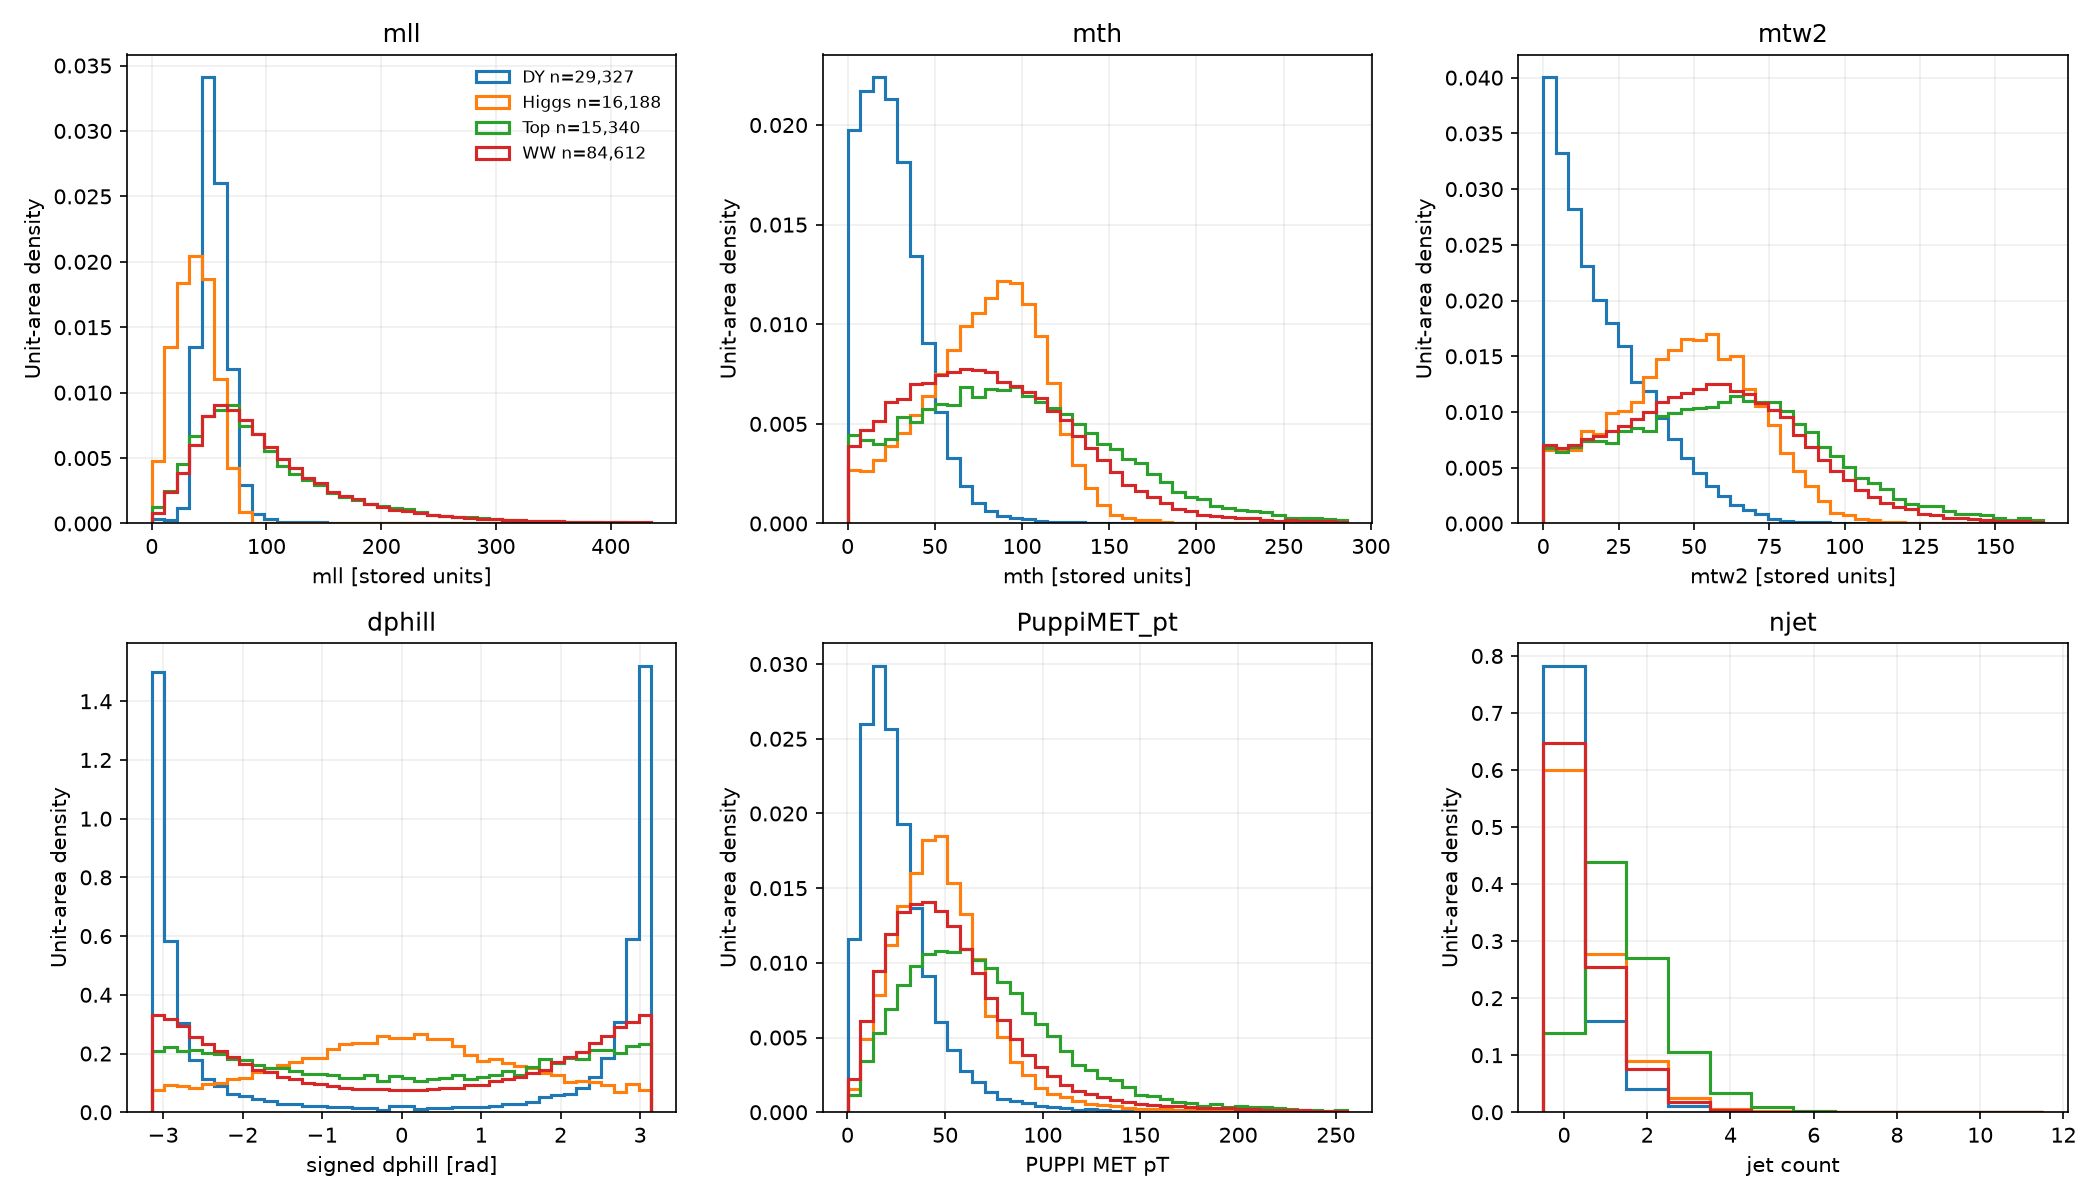

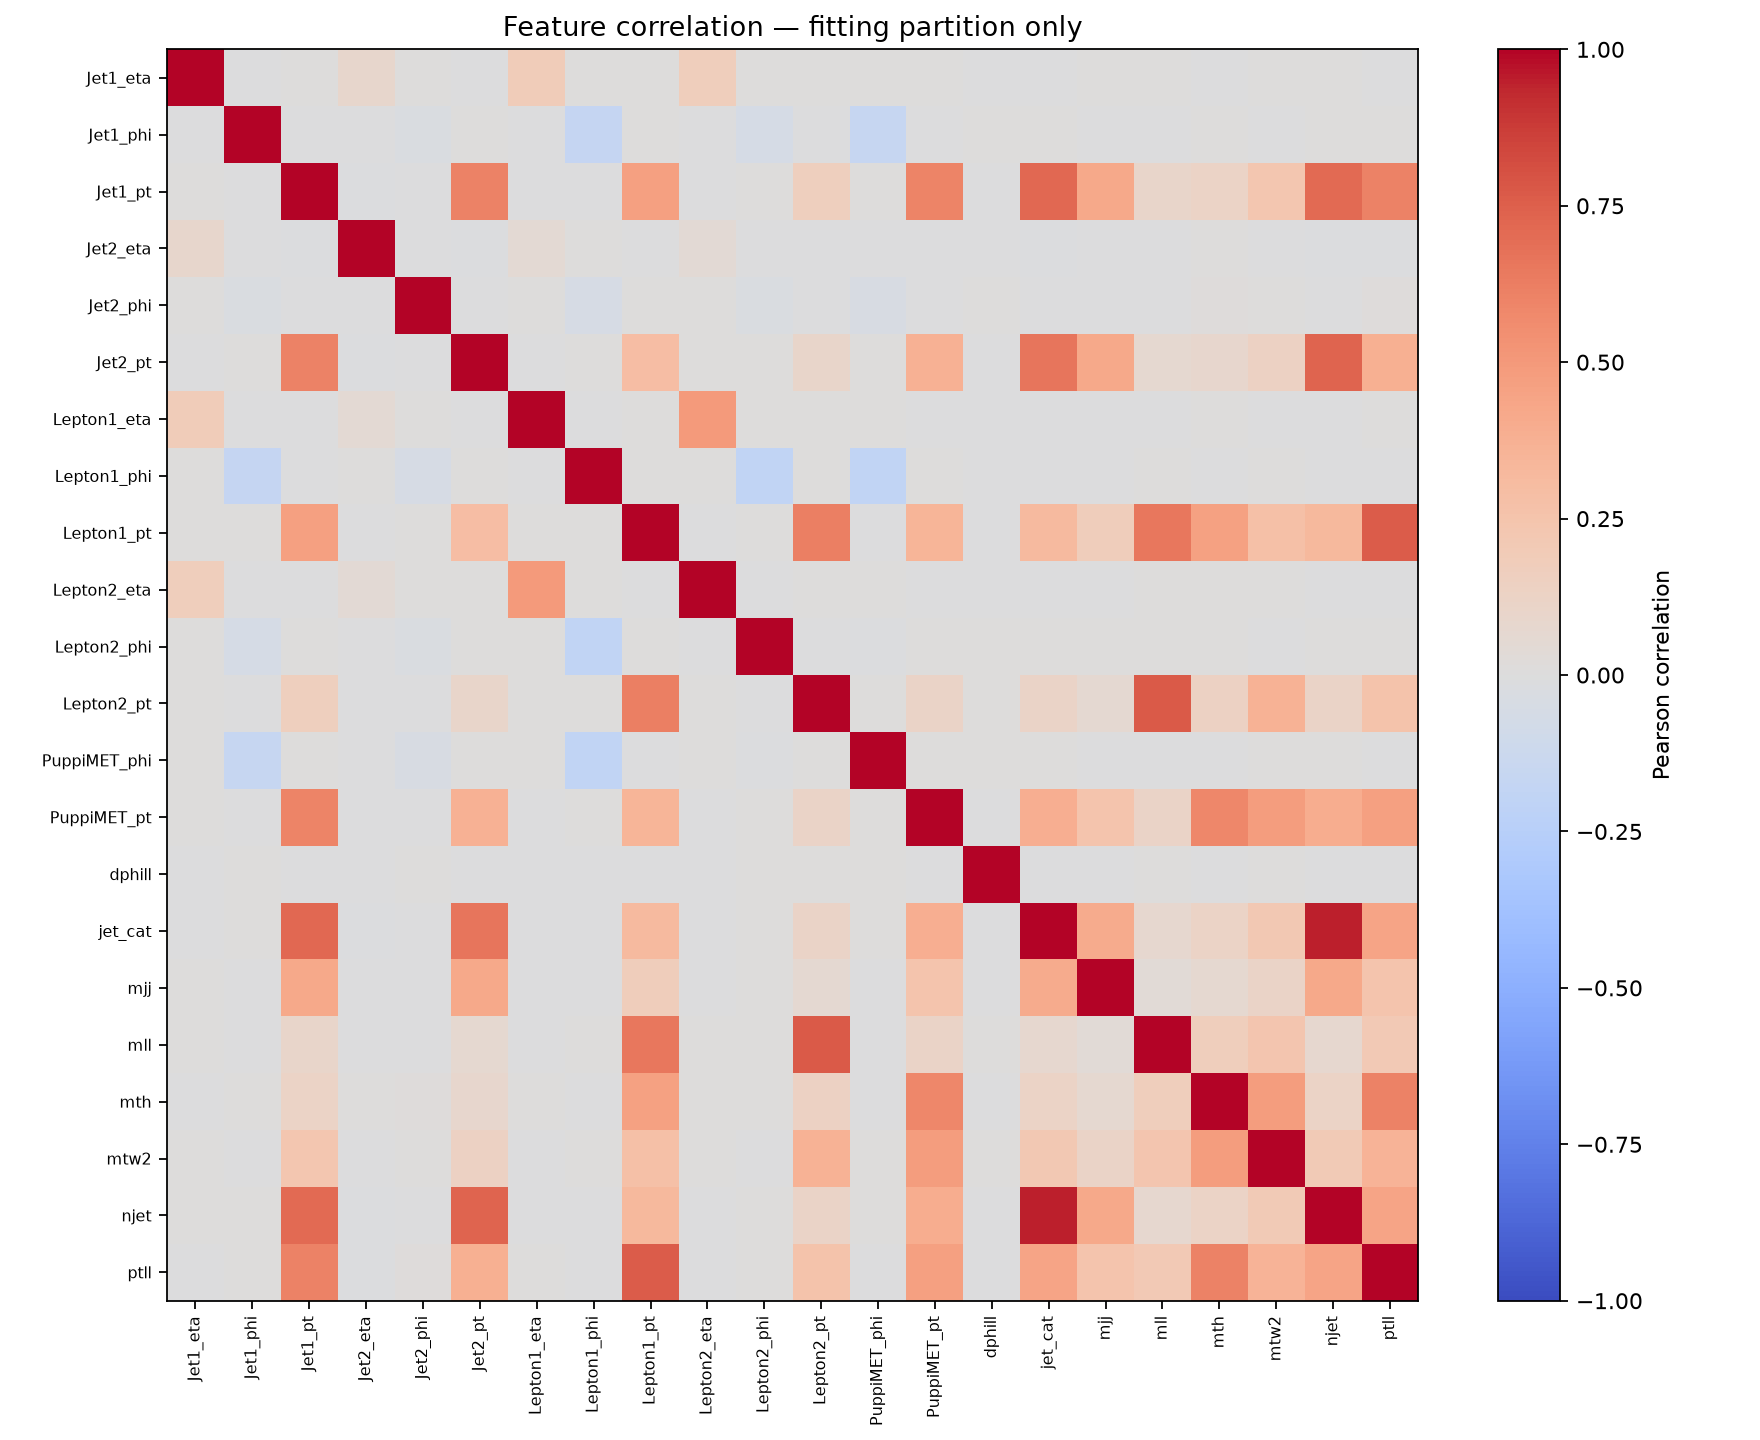

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, xlabel) in zip(
    axs.flat,
    [
        ("mll", "mll [stored units]"),
        ("mth", "mth [stored units]"),
        ("mtw2", "mtw2 [stored units]"),
        ("dphill", "signed dphill [rad]"),
        ("PuppiMET_pt", "PUPPI MET pT"),
        ("njet", "jet count"),
    ],
):
    j = FEATURES.index(name)
    hi = np.nanquantile(X_fit[:, j], 0.995)
    bins = (
        np.linspace(-np.pi, np.pi, 41)
        if name == "dphill"
        else (
            np.arange(
                int(np.nanmin(X_fit[:, j])) - 0.5, int(np.nanmax(X_fit[:, j])) + 1.5
            )
            if name == "njet"
            else np.linspace(np.nanmin(X_fit[:, j]), hi, 41)
        )
    )
    for c in CLASSES:
        vals = X_fit[lab_fit == c, j]
        ax.hist(
            vals,
            bins=bins,
            density=True,
            histtype="step",
            lw=1.5,
            label=f"{c} n={len(vals):,}",
        )
    ax.set(xlabel=xlabel, ylabel="Unit-area density", title=name)
    ax.grid(alpha=0.2)
axs[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "training_feature_distributions.png", dpi=150)
display(Image(filename=str(OUT_DIR / "training_feature_distributions.png")))
plt.close(fig)
corr = np.corrcoef(X_fit.astype(float), rowvar=False)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
ax.set_title("Feature correlation — fitting partition only")
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(OUT_DIR / "training_feature_correlation.png", dpi=160)
display(Image(filename=str(OUT_DIR / "training_feature_correlation.png")))
plt.close(fig)


## Option B candidate search

The full configuration plan is generated before fitting. All candidates use the same 22 training features, fitting rows, validation rows and preprocessing rules. We select by validation ROC-AUC; ties use average precision, the smaller absolute train–validation AUC gap, then simpler family order and ID. Scores at 0.5 are descriptive and may be affected by calibration differences.


In [6]:
def metrics(yy, ss, threshold):
    predictions = (ss >= threshold).astype(np.int8)
    return {
        "ROC-AUC": float(roc_auc_score(yy, ss)),
        "average_precision": float(average_precision_score(yy, ss)),
        "accuracy": float(accuracy_score(yy, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(yy, predictions)),
        "precision": float(precision_score(yy, predictions, zero_division=0)),
        "recall": float(recall_score(yy, predictions, zero_division=0)),
        "F1": float(f1_score(yy, predictions, zero_division=0)),
    }


def estimator_thread_limit(config):
    return 1 if config["family"] == "random_forest" else HGB_THREADS


plan_rows = [
    {
        "id": config["id"],
        "family": config["family"],
        "parameters": config["params"],
        "backend/device": f"{config['backend']}/{config['device']}",
        "library": config["library_version"],
        "workers": config["workers"],
        "features": "all 22",
    }
    for config in MODEL_CONFIGS
]
display_table(plan_rows)
display_table(
    [
        {"optional family": family, **status}
        for family, status in OPTIONAL_STATUS.items()
    ]
)
print(
    {
        "declared_budget": len(MODEL_CONFIGS),
        "family_allocations": family_allocations,
        "nvidia_device": NVIDIA_DEVICE,
        "thread_settings": {
            "available_cpus": CPU_AVAILABLE,
            "hist_gradient_boosting_and_boosting_threads": HGB_THREADS,
            "random_forest_workers": RF_WORKERS,
            "random_forest_native_threads": 1,
        },
    }
)

models = {}
scores = {}
rows = []
attempts = []
search_started = time.perf_counter()
for config in MODEL_CONFIGS:
    fit_started = time.perf_counter()
    warning_messages = []
    try:
        estimator = make_estimator(config)
        with warnings.catch_warnings(record=True) as captured_warnings:
            warnings.simplefilter("always")
            with threadpool_limits(limits=estimator_thread_limit(config)):
                estimator.fit(X_fit, y_fit)
                train_scores = estimator.predict_proba(X_fit)[:, 1]
                validation_scores = estimator.predict_proba(X_val)[:, 1]
        warning_messages = [
            f"{item.category.__name__}: {item.message}"
            for item in captured_warnings
        ]
        train_auc = float(roc_auc_score(y_fit, train_scores))
        validation_metrics = metrics(y_val, validation_scores, 0.5)
        row = {
            "id": config["id"],
            "family": config["family"],
            "params": config["params"],
            "backend": config["backend"],
            "device": config["device"],
            "library_version": config["library_version"],
            "workers": config["workers"],
            "runtime_seconds": time.perf_counter() - fit_started,
            "train_auc": train_auc,
            "validation": validation_metrics,
            "gap": train_auc - validation_metrics["ROC-AUC"],
            "warnings": warning_messages,
            "success": True,
            "failure_reason": None,
        }
        rows.append(row)
        models[config["id"]] = estimator
        scores[config["id"]] = {
            "fit": train_scores,
            "validation": validation_scores,
        }
        attempts.append(row)
    except Exception as exc:
        attempts.append(
            {
                "id": config["id"],
                "family": config["family"],
                "params": config["params"],
                "backend": config["backend"],
                "device": config["device"],
                "library_version": config["library_version"],
                "workers": config["workers"],
                "runtime_seconds": time.perf_counter() - fit_started,
                "success": False,
                "failure_reason": f"{type(exc).__name__}: {exc}",
                "warnings": warning_messages,
            }
        )
if not rows:
    raise RuntimeError("No candidate configuration completed successfully")
search_seconds = time.perf_counter() - search_started
candidate_fit_seconds = float(
    sum(attempt["runtime_seconds"] for attempt in attempts if attempt["success"])
)

family_complexity = {
    family: rank for rank, family in enumerate(FAMILY_ORDER)
}
best = max(rows, key=lambda row: row["validation"]["ROC-AUC"])
winner = max(
    rows,
    key=lambda row: (
        row["validation"]["ROC-AUC"],
        row["validation"]["average_precision"],
        -abs(row["gap"]),
        -family_complexity[row["family"]],
        row["id"],
    ),
)

candidate_table = []
for attempt in attempts:
    output_row = {
        "id": attempt["id"],
        "family": attempt["family"],
        "parameters": attempt["params"],
        "backend/device": f"{attempt['backend']}/{attempt['device']}",
        "library": attempt["library_version"],
        "workers": attempt["workers"],
        "runtime_s": attempt["runtime_seconds"],
        "status": "success" if attempt["success"] else "failed",
        "failure_reason": attempt["failure_reason"],
        "warnings": " | ".join(attempt["warnings"]),
    }
    if attempt["success"]:
        output_row.update(
            {
                "train_AUC": attempt["train_auc"],
                "validation_AUC": attempt["validation"]["ROC-AUC"],
                "validation_AP": attempt["validation"]["average_precision"],
                "accuracy_at_0.5": attempt["validation"]["accuracy"],
                "balanced_accuracy_at_0.5": attempt["validation"]["balanced_accuracy"],
                "precision_at_0.5": attempt["validation"]["precision"],
                "recall_at_0.5": attempt["validation"]["recall"],
                "F1_at_0.5": attempt["validation"]["F1"],
                "train_validation_AUC_gap": attempt["gap"],
            }
        )
    candidate_table.append(output_row)
display_table(candidate_table)

# Pair-bootstrap the leading four configurations on identical validation-event draws.
leaders = sorted(rows, key=lambda row: row["validation"]["ROC-AUC"], reverse=True)[:4]
leader_groups = {
    row["id"]: score_group_ids(scores[row["id"]]["validation"])
    for row in leaders
}
pos_validation = np.flatnonzero(y_val == 1)
neg_validation = np.flatnonzero(y_val == 0)
rng = np.random.default_rng(BOOTSTRAP_SEED)
leader_bootstrap = {
    row["id"]: {"auc": np.empty(BOOTSTRAP_REPLICATES), "ap": np.empty(BOOTSTRAP_REPLICATES)}
    for row in leaders
}
leading_bootstrap_started = time.perf_counter()
for replicate in range(BOOTSTRAP_REPLICATES):
    positive_draw = rng.choice(pos_validation, len(pos_validation), replace=True)
    negative_draw = rng.choice(neg_validation, len(neg_validation), replace=True)
    for row in leaders:
        group_ids, group_count = leader_groups[row["id"]]
        auc, ap = grouped_auc_ap(
            group_ids[positive_draw], group_ids[negative_draw], group_count
        )
        leader_bootstrap[row["id"]]["auc"][replicate] = auc
        leader_bootstrap[row["id"]]["ap"][replicate] = ap
leading_bootstrap_seconds = time.perf_counter() - leading_bootstrap_started
leader_comparisons = []
for row in leaders:
    auc_difference = leader_bootstrap[best["id"]]["auc"] - leader_bootstrap[row["id"]]["auc"]
    ap_difference = leader_bootstrap[best["id"]]["ap"] - leader_bootstrap[row["id"]]["ap"]
    leader_comparisons.append(
        {
            "candidate_vs_best": row["id"],
            "paired_AUC_difference_mean": float(np.mean(auc_difference)),
            "paired_AUC_difference_95pct": [
                float(np.quantile(auc_difference, 0.025)),
                float(np.quantile(auc_difference, 0.975)),
            ],
            "paired_AP_difference_mean": float(np.mean(ap_difference)),
            "paired_AP_difference_95pct": [
                float(np.quantile(ap_difference, 0.025)),
                float(np.quantile(ap_difference, 0.975)),
            ],
            "replicates": BOOTSTRAP_REPLICATES,
        }
    )
display_table(leader_comparisons)
print(
    {
        "attempted": len(attempts),
        "successful": len(rows),
        "failed": len(attempts) - len(rows),
        "search_seconds": search_seconds,
        "leading_paired_bootstrap_seconds": leading_bootstrap_seconds,
        "overall_winner": winner["id"],
        "primary_selection": "highest validation ROC-AUC; ties by AP, smaller absolute train-validation AUC gap, simpler family, then ID",
        "single_split_caveat": "validation comparisons on one partition can be optimistic",
    }
)


| id | family | parameters | backend/device | library | workers | features |
| --- | --- | --- | --- | --- | --- | --- |
| logistic_C_0.05 | logistic_regression | {"C":0.05,"max_iter":2000} | CPU/cpu | 1.9.1 | 4 | all 22 |
| logistic_C_0.3 | logistic_regression | {"C":0.3,"max_iter":2000} | CPU/cpu | 1.9.1 | 4 | all 22 |
| logistic_C_3 | logistic_regression | {"C":3.0,"max_iter":2000} | CPU/cpu | 1.9.1 | 4 | all 22 |
| decision_tree_depth3_leaf20 | decision_tree | {"max_depth":3,"min_samples_leaf":20} | CPU/cpu | 1.9.1 | 4 | all 22 |
| decision_tree_depth5_leaf10 | decision_tree | {"max_depth":5,"min_samples_leaf":10} | CPU/cpu | 1.9.1 | 4 | all 22 |
| decision_tree_depth8_leaf10 | decision_tree | {"max_depth":8,"min_samples_leaf":10} | CPU/cpu | 1.9.1 | 4 | all 22 |
| random_forest_160_depth8 | random_forest | {"max_depth":8,"min_samples_leaf":1,"n_estimators":160} | CPU/cpu | 1.9.1 | 8 | all 22 |
| random_forest_200_depth16 | random_forest | {"max_depth":16,"min_samples_leaf":5,"n_estimators":200} | CPU/cpu | 1.9.1 | 8 | all 22 |
| random_forest_240_unlimited_leaf10 | random_forest | {"max_depth":null,"min_samples_leaf":10,"n_estimators":240} | CPU/cpu | 1.9.1 | 8 | all 22 |
| hist_gradient_boosting_leaves7_lr005 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":1.0,"learning_rate":0.05,"max_iter":100,"max_leaf_nodes":7} | CPU/cpu | 1.9.1 | 4 | all 22 |
| hist_gradient_boosting_leaves15_lr008 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":1.0,"learning_rate":0.08,"max_iter":150,"max_leaf_nodes":15} | CPU/cpu | 1.9.1 | 4 | all 22 |
| hist_gradient_boosting_leaves31_lr01 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":2.0,"learning_rate":0.1,"max_iter":150,"max_leaf_nodes":31} | CPU/cpu | 1.9.1 | 4 | all 22 |
| xgboost_depth3_120 | xgboost | {"learning_rate":0.05,"max_depth":3,"n_estimators":120,"reg_lambda":1.0} | CPU/cpu | 3.4.1 | 4 | all 22 |
| xgboost_depth4_160 | xgboost | {"learning_rate":0.08,"max_depth":4,"n_estimators":160,"reg_lambda":1.0} | CPU/cpu | 3.4.1 | 4 | all 22 |
| xgboost_depth5_200 | xgboost | {"learning_rate":0.1,"max_depth":5,"n_estimators":200,"reg_lambda":2.0} | CPU/cpu | 3.4.1 | 4 | all 22 |
| lightgbm_leaves15_120 | lightgbm | {"learning_rate":0.05,"max_depth":-1,"n_estimators":120,"num_leaves":15,"reg_lambda":1.0} | CPU/cpu | 4.7.0 | 4 | all 22 |
| lightgbm_leaves31_160 | lightgbm | {"learning_rate":0.08,"max_depth":-1,"n_estimators":160,"num_leaves":31,"reg_lambda":1.0} | CPU/cpu | 4.7.0 | 4 | all 22 |
| lightgbm_leaves31_200 | lightgbm | {"learning_rate":0.1,"max_depth":-1,"n_estimators":200,"num_leaves":31,"reg_lambda":2.0} | CPU/cpu | 4.7.0 | 4 | all 22 |

| optional family | available | version | backend | device | gpu_fallback_reason |
| --- | --- | --- | --- | --- | --- |
| xgboost | True | 3.4.1 | CPU | cpu | nvidia-smi not found; no NVIDIA runtime detected |
| lightgbm | True | 4.7.0 | CPU | cpu | nvidia-smi not found; no NVIDIA runtime detected |

{'declared_budget': 18, 'family_allocations': {'logistic_regression': 3, 'decision_tree': 3, 'random_forest': 3, 'hist_gradient_boosting': 3, 'xgboost': 3, 'lightgbm': 3}, 'nvidia_device': None, 'thread_settings': {'available_cpus': 10, 'hist_gradient_boosting_and_boosting_threads': 4, 'random_forest_workers': 8, 'random_forest_native_threads': 1}}


| id | family | parameters | backend/device | library | workers | runtime_s | status | failure_reason | warnings | train_AUC | validation_AUC | validation_AP | accuracy_at_0.5 | balanced_accuracy_at_0.5 | precision_at_0.5 | recall_at_0.5 | F1_at_0.5 | train_validation_AUC_gap |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| logistic_C_0.05 | logistic_regression | {"C":0.05,"max_iter":2000} | CPU/cpu | 1.9.1 | 4 | 0.5806 | success | — |  | 0.8612 | 0.8654 | 0.4099 | 0.8893 | 0.5688 | 0.5087 | 0.1566 | 0.2395 | -0.004171 |
| logistic_C_0.3 | logistic_regression | {"C":0.3,"max_iter":2000} | CPU/cpu | 1.9.1 | 4 | 0.6655 | success | — |  | 0.8612 | 0.8654 | 0.4101 | 0.8894 | 0.5725 | 0.51 | 0.1648 | 0.2491 | -0.004142 |
| logistic_C_3 | logistic_regression | {"C":3.0,"max_iter":2000} | CPU/cpu | 1.9.1 | 4 | 0.5931 | success | — |  | 0.8612 | 0.8653 | 0.4102 | 0.8894 | 0.5729 | 0.51 | 0.1657 | 0.2501 | -0.00414 |
| decision_tree_depth3_leaf20 | decision_tree | {"max_depth":3,"min_samples_leaf":20} | CPU/cpu | 1.9.1 | 4 | 1.336 | success | — |  | 0.866 | 0.8679 | 0.373 | 0.8887 | 0.5 | 0 | 0 | 0 | -0.001876 |
| decision_tree_depth5_leaf10 | decision_tree | {"max_depth":5,"min_samples_leaf":10} | CPU/cpu | 1.9.1 | 4 | 1.881 | success | — |  | 0.8884 | 0.888 | 0.4184 | 0.8911 | 0.6127 | 0.522 | 0.2546 | 0.3423 | 0.0003467 |
| decision_tree_depth8_leaf10 | decision_tree | {"max_depth":8,"min_samples_leaf":10} | CPU/cpu | 1.9.1 | 4 | 2.605 | success | — |  | 0.9054 | 0.8953 | 0.456 | 0.8932 | 0.6167 | 0.5415 | 0.2611 | 0.3523 | 0.01004 |
| random_forest_160_depth8 | random_forest | {"max_depth":8,"min_samples_leaf":1,"n_estimators":160} | CPU/cpu | 1.9.1 | 8 | 8.765 | success | — |  | 0.9077 | 0.8996 | 0.4844 | 0.8888 | 0.5003 | 1 | 0.000556 | 0.001111 | 0.008143 |
| random_forest_200_depth16 | random_forest | {"max_depth":16,"min_samples_leaf":5,"n_estimators":200} | CPU/cpu | 1.9.1 | 8 | 14.61 | success | — |  | 0.9649 | 0.907 | 0.5099 | 0.8976 | 0.612 | 0.5973 | 0.2446 | 0.3471 | 0.05793 |
| random_forest_240_unlimited_leaf10 | random_forest | {"max_depth":null,"min_samples_leaf":10,"n_estimators":240} | CPU/cpu | 1.9.1 | 8 | 19.06 | success | — |  | 0.9716 | 0.9073 | 0.5065 | 0.8981 | 0.618 | 0.5981 | 0.2576 | 0.3601 | 0.06429 |
| hist_gradient_boosting_leaves7_lr005 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":1.0,"learning_rate":0.05,"max_iter":100,"max_leaf_nodes":7} | CPU/cpu | 1.9.1 | 4 | 1.937 | success | — |  | 0.9039 | 0.9044 | 0.5015 | 0.8966 | 0.5902 | 0.6101 | 0.1961 | 0.2968 | -0.0004553 |
| hist_gradient_boosting_leaves15_lr008 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":1.0,"learning_rate":0.08,"max_iter":150,"max_leaf_nodes":15} | CPU/cpu | 1.9.1 | 4 | 2.854 | success | — |  | 0.9166 | 0.9102 | 0.5219 | 0.8995 | 0.6376 | 0.5965 | 0.3008 | 0.3999 | 0.006471 |
| hist_gradient_boosting_leaves31_lr01 | hist_gradient_boosting | {"early_stopping":false,"l2_regularization":2.0,"learning_rate":0.1,"max_iter":150,"max_leaf_nodes":31} | CPU/cpu | 1.9.1 | 4 | 3.042 | success | — |  | 0.9287 | 0.9104 | 0.5211 | 0.8993 | 0.6481 | 0.5859 | 0.3249 | 0.418 | 0.01835 |
| xgboost_depth3_120 | xgboost | {"learning_rate":0.05,"max_depth":3,"n_estimators":120,"reg_lambda":1.0} | CPU/cpu | 3.4.1 | 4 | 0.8734 | success | — |  | 0.9029 | 0.9035 | 0.4891 | 0.8944 | 0.5862 | 0.5776 | 0.1898 | 0.2857 | -0.0005935 |
| xgboost_depth4_160 | xgboost | {"learning_rate":0.08,"max_depth":4,"n_estimators":160,"reg_lambda":1.0} | CPU/cpu | 3.4.1 | 4 | 0.9774 | success | — |  | 0.9145 | 0.9098 | 0.5196 | 0.8997 | 0.6334 | 0.6025 | 0.2908 | 0.3922 | 0.004625 |
| xgboost_depth5_200 | xgboost | {"learning_rate":0.1,"max_depth":5,"n_estimators":200,"reg_lambda":2.0} | CPU/cpu | 3.4.1 | 4 | 1.2 | success | — |  | 0.9262 | 0.9104 | 0.5222 | 0.8998 | 0.6449 | 0.5935 | 0.3171 | 0.4133 | 0.01578 |
| lightgbm_leaves15_120 | lightgbm | {"learning_rate":0.05,"max_depth":-1,"n_estimators":120,"num_leaves":15,"reg_lambda":1.0} | CPU/cpu | 4.7.0 | 4 | 1.368 | success | — |  | 0.9117 | 0.9093 | 0.5203 | 0.8995 | 0.6291 | 0.6038 | 0.2813 | 0.3838 | 0.002357 |
| lightgbm_leaves31_160 | lightgbm | {"learning_rate":0.08,"max_depth":-1,"n_estimators":160,"num_leaves":31,"reg_lambda":1.0} | CPU/cpu | 4.7.0 | 4 | 1.828 | success | — |  | 0.9272 | 0.9105 | 0.5205 | 0.8989 | 0.6453 | 0.5835 | 0.3191 | 0.4126 | 0.01665 |
| lightgbm_leaves31_200 | lightgbm | {"learning_rate":0.1,"max_depth":-1,"n_estimators":200,"num_leaves":31,"reg_lambda":2.0} | CPU/cpu | 4.7.0 | 4 | 2.037 | success | — |  | 0.9336 | 0.91 | 0.517 | 0.8983 | 0.6466 | 0.577 | 0.3228 | 0.414 | 0.02366 |

| candidate_vs_best | paired_AUC_difference_mean | paired_AUC_difference_95pct | paired_AP_difference_mean | paired_AP_difference_95pct | replicates |
| --- | --- | --- | --- | --- | --- |
| lightgbm_leaves31_160 | 0 | [0.0,0.0] | 0 | [0.0,0.0] | 1000 |
| xgboost_depth5_200 | 0.0001476 | [-0.00044414033196638893,0.0007390934056855534] | -0.001778 | [-0.005958993889557079,0.0028850952799509386] | 1000 |
| hist_gradient_boosting_leaves31_lr01 | 0.0001793 | [-0.0003404055758385815,0.000673115203525687] | -0.0005551 | [-0.004414671304305412,0.003345871637207406] | 1000 |
| hist_gradient_boosting_leaves15_lr008 | 0.00038 | [-0.00015979116666265948,0.0009050031959771025] | -0.001459 | [-0.005793586894367866,0.0031262426236075666] | 1000 |

{'attempted': 18, 'successful': 18, 'failed': 0, 'search_seconds': 66.21506729198154, 'leading_paired_bootstrap_seconds': 6.52938437499688, 'overall_winner': 'lightgbm_leaves31_160', 'primary_selection': 'highest validation ROC-AUC; ties by AP, smaller absolute train-validation AUC gap, simpler family, then ID', 'single_split_caveat': 'validation comparisons on one partition can be optimistic'}


One validation partition supports the search, so the selected score may be optimistic. The paired bootstrap for the leading configurations measures uncertainty on these same rows; it does not replace a second independent validation sample.


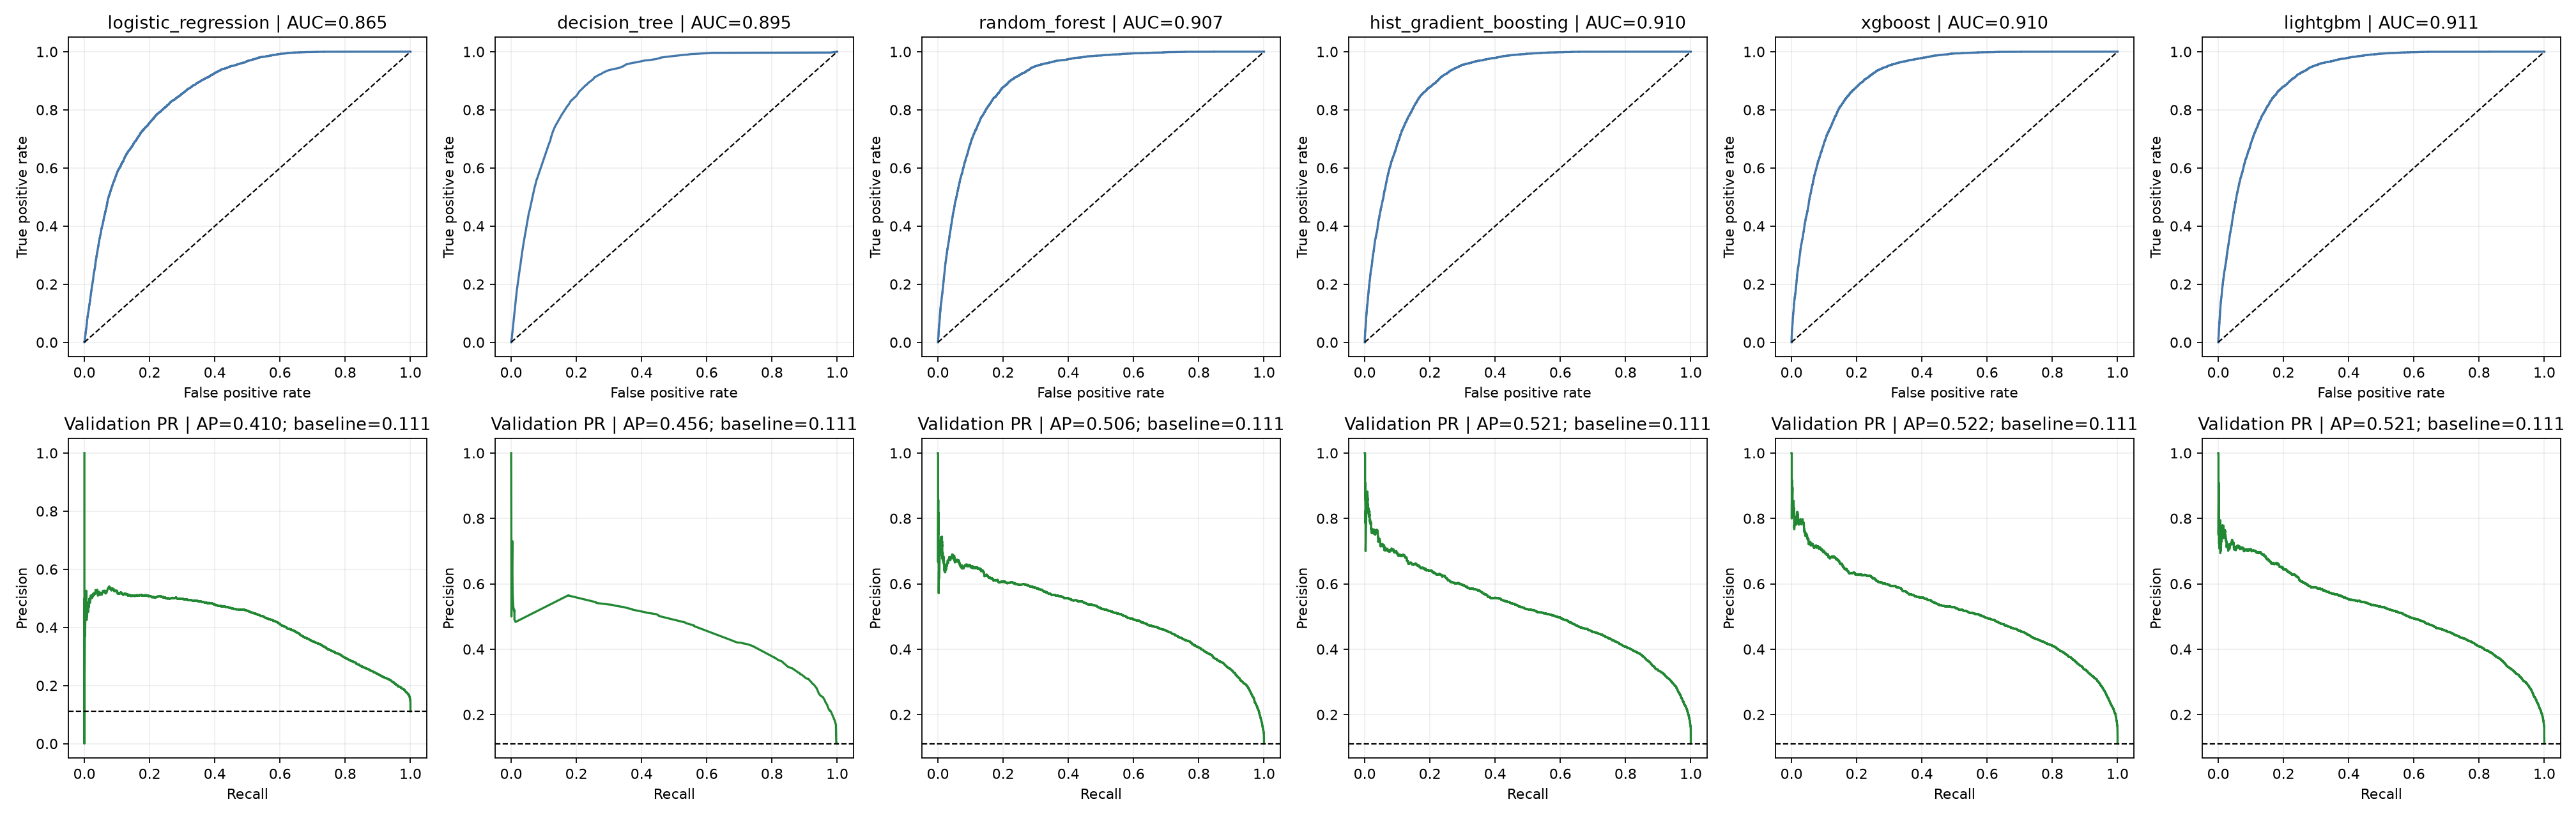

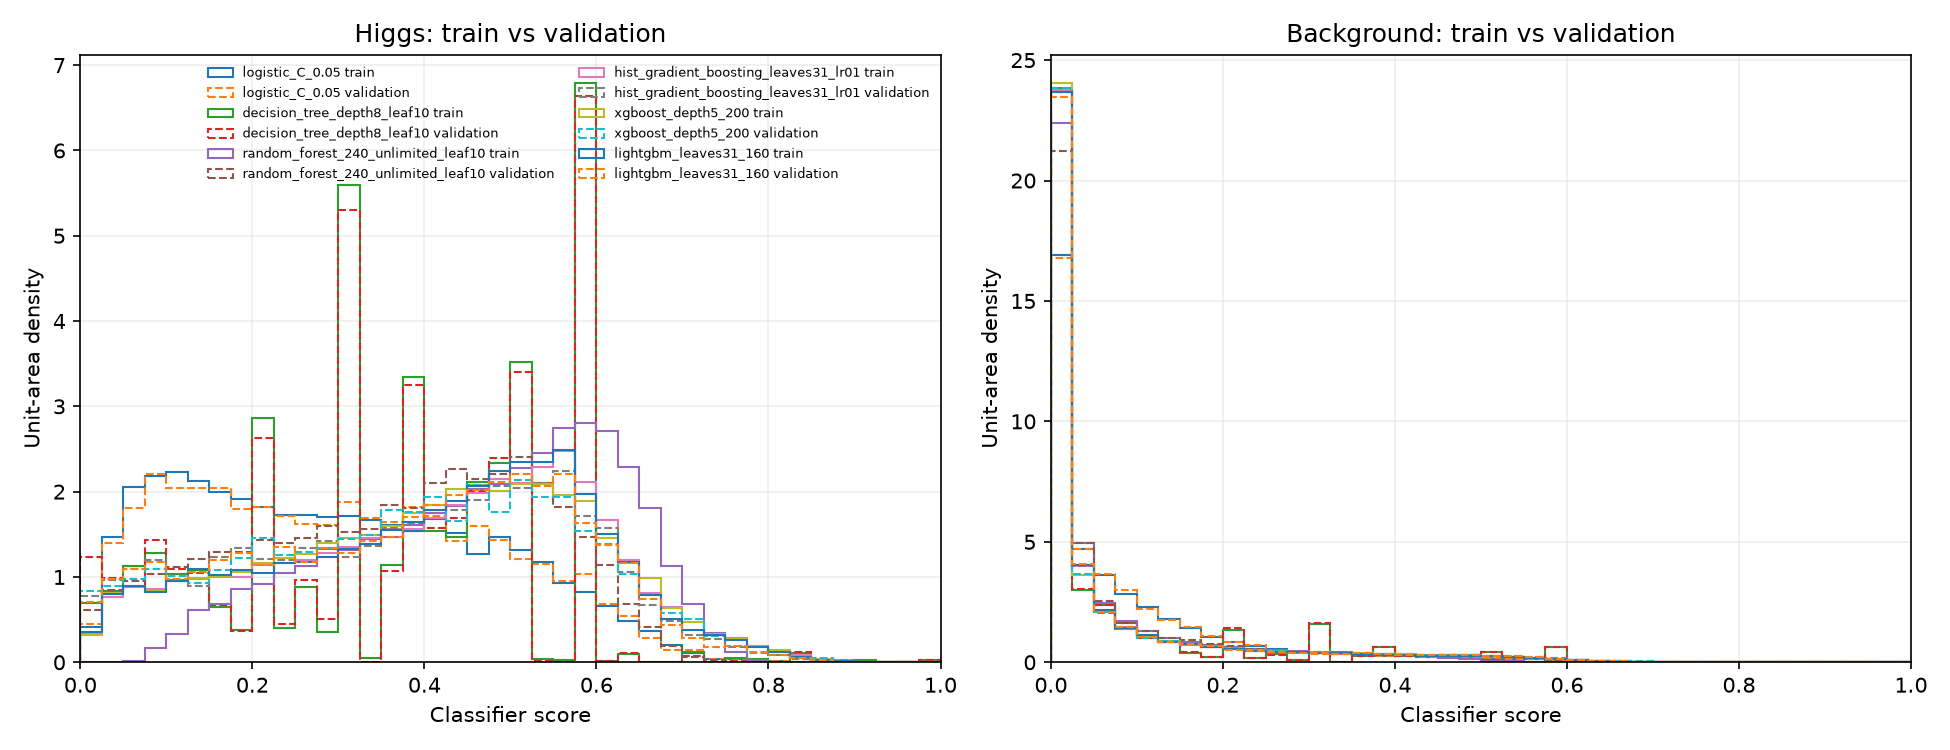

| configuration | class | train_rows | validation_rows | KS_D | KS_p |
| --- | --- | --- | --- | --- | --- |
| logistic_C_0.05 | Higgs | 16188 | 5396 | 0.02224 | 0.03598 |
| decision_tree_depth8_leaf10 | Higgs | 16188 | 5396 | 0.02051 | 0.06553 |
| random_forest_240_unlimited_leaf10 | Higgs | 16188 | 5396 | 0.2328 | 2.123e-193 |
| hist_gradient_boosting_leaves31_lr01 | Higgs | 16188 | 5396 | 0.05418 | 9.162e-11 |
| xgboost_depth5_200 | Higgs | 16188 | 5396 | 0.04658 | 4.551e-08 |
| lightgbm_leaves31_160 | Higgs | 16188 | 5396 | 0.0496 | 4.294e-09 |
| logistic_C_0.05 | Background | 129279 | 43093 | 0.004564 | 0.5098 |
| decision_tree_depth8_leaf10 | Background | 129279 | 43093 | 0.005964 | 0.1997 |
| random_forest_240_unlimited_leaf10 | Background | 129279 | 43093 | 0.03175 | 9.884e-29 |
| hist_gradient_boosting_leaves31_lr01 | Background | 129279 | 43093 | 0.009004 | 0.01053 |
| xgboost_depth5_200 | Background | 129279 | 43093 | 0.008083 | 0.02913 |
| lightgbm_leaves31_160 | Background | 129279 | 43093 | 0.008594 | 0.0168 |

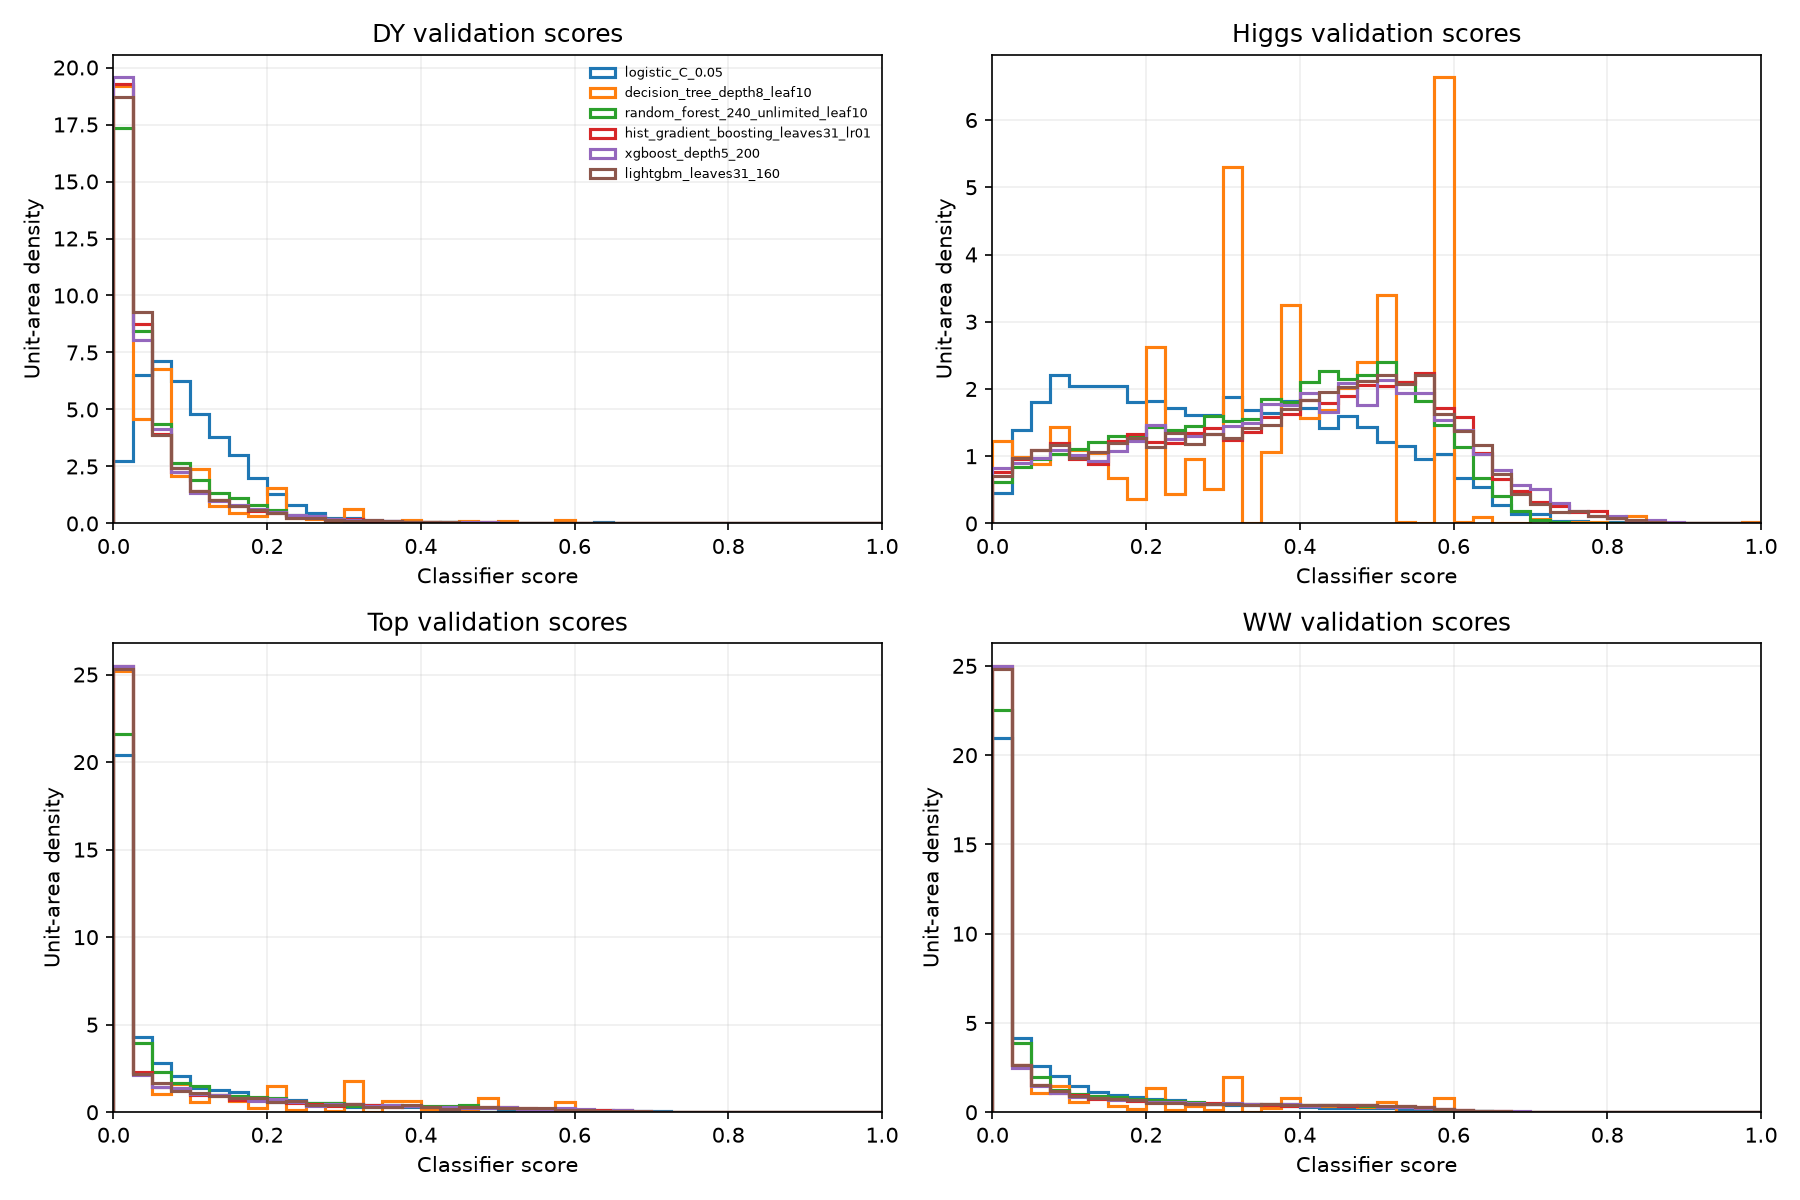

In [7]:
family_best = [
    max(
        [row for row in rows if row["family"] == family],
        key=lambda row: row["validation"]["ROC-AUC"],
    )
    for family in FAMILY_ORDER
]
short_ids = [row["id"] for row in family_best]

fig, axes = plt.subplots(2, len(family_best), figsize=(4.2 * len(family_best), 8))
if len(family_best) == 1:
    axes = np.asarray(axes).reshape(2, 1)
for column, row in enumerate(family_best):
    config_id = row["id"]
    validation_scores = scores[config_id]["validation"]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_val, validation_scores)
    precision, recall, _ = precision_recall_curve(y_val, validation_scores)
    axes[0, column].plot(false_positive_rate, true_positive_rate, color="#4477aa")
    axes[0, column].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0, column].set(
        xlabel="False positive rate",
        ylabel="True positive rate",
        title=f"{row['family']} | AUC={row['validation']['ROC-AUC']:.3f}",
    )
    axes[1, column].plot(recall, precision, color="#228833")
    axes[1, column].axhline(y_val.mean(), color="k", ls="--", lw=1)
    axes[1, column].set(
        xlabel="Recall",
        ylabel="Precision",
        title=f"Validation PR | AP={row['validation']['average_precision']:.3f}; baseline={y_val.mean():.3f}",
    )
for axis in axes.flat:
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / "family_best_validation_curves.png", dpi=160)
display(Image(filename=str(OUT_DIR / "family_best_validation_curves.png")))
plt.close(fig)

ks_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = np.linspace(0, 1, 41)
for axis, truth, class_name in [(axes[0], 1, "Higgs"), (axes[1], 0, "Background")]:
    for config_id in short_ids:
        training_scores = scores[config_id]["fit"][y_fit == truth]
        validation_scores = scores[config_id]["validation"][y_val == truth]
        axis.hist(training_scores, bins=bins, density=True, histtype="step", label=f"{config_id} train")
        axis.hist(validation_scores, bins=bins, density=True, histtype="step", ls="--", label=f"{config_id} validation")
        ks = ks_2samp(training_scores, validation_scores, method="auto")
        ks_rows.append(
            {
                "configuration": config_id,
                "class": class_name,
                "train_rows": len(training_scores),
                "validation_rows": len(validation_scores),
                "KS_D": float(ks.statistic),
                "KS_p": float(ks.pvalue),
            }
        )
    axis.set(xlim=(0, 1), xlabel="Classifier score", ylabel="Unit-area density", title=f"{class_name}: train vs validation")
    axis.grid(alpha=0.2)
axes[0].legend(frameon=False, fontsize=6, ncol=2)
fig.tight_layout()
fig.savefig(OUT_DIR / "family_best_train_validation_scores.png", dpi=150)
display(Image(filename=str(OUT_DIR / "family_best_train_validation_scores.png")))
plt.close(fig)
display_table(ks_rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, class_name in zip(axes.flat, CLASSES):
    process_mask = lab_val == class_name
    for config_id in short_ids:
        axis.hist(
            scores[config_id]["validation"][process_mask],
            bins=np.linspace(0, 1, 41),
            density=True,
            histtype="step",
            lw=1.5,
            label=config_id,
        )
    axis.set(xlim=(0, 1), xlabel="Classifier score", ylabel="Unit-area density", title=f"{class_name} validation scores")
    axis.grid(alpha=0.2)
axes[0, 0].legend(frameon=False, fontsize=6)
fig.tight_layout()
fig.savefig(OUT_DIR / "family_best_validation_scores_by_process.png", dpi=150)
display(Image(filename=str(OUT_DIR / "family_best_validation_scores_by_process.png")))
plt.close(fig)


## Validation feature importance and subsets

Permutation importance is predictive reliance, not physical causation. Correlated features can share importance. We rank features on a deterministic, stratified validation-row sample, then fit each declared subset from scratch. The nine-set limit includes the full set.


| feature | mean_AUC_decrease | std |
| --- | --- | --- |
| mll | 0.3339 | 0.006277 |
| mth | 0.03854 | 0.001456 |
| ptll | 0.03346 | 0.0006437 |
| Jet1_pt | 0.01026 | 0.000872 |
| dphill | 0.006871 | 0.0004336 |
| mtw2 | 0.003435 | 0.0004236 |
| PuppiMET_pt | 0.003427 | 0.000236 |
| Jet1_eta | 0.003202 | 0.0003429 |
| Lepton2_pt | 0.001514 | 0.0002463 |
| Lepton1_pt | 0.001426 | 0.0001725 |
| mjj | 0.001247 | 4.377e-05 |
| Lepton1_eta | 0.001168 | 0.0002821 |
| Lepton2_eta | 0.0009437 | 0.0003468 |
| Jet2_pt | 0.0003206 | 0.0002294 |
| PuppiMET_phi | 0.0001178 | 8.851e-05 |
| Jet2_phi | 0.0001135 | 2.415e-05 |
| Jet2_eta | 9.758e-05 | 0.0001171 |
| njet | 6.435e-06 | 2.445e-06 |
| jet_cat | 0 | 0 |
| Jet1_phi | -1.698e-06 | 0.0001045 |
| Lepton1_phi | -6.142e-05 | 5.798e-05 |
| Lepton2_phi | -0.000101 | 6.787e-05 |

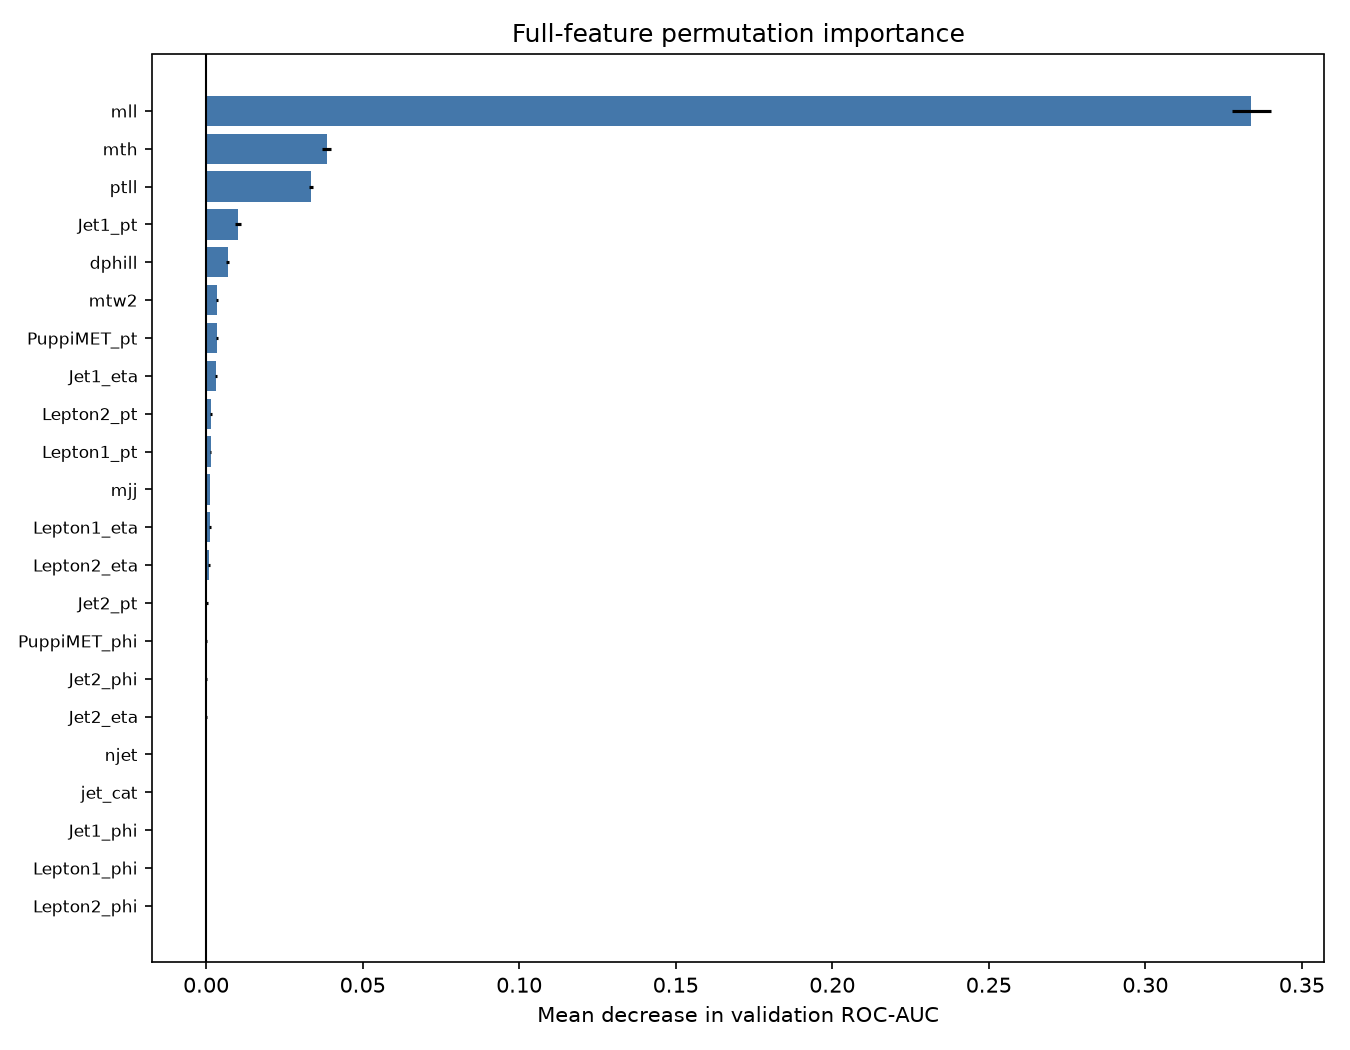

| feature_set | feature_count | features |
| --- | --- | --- |
| full | 22 | ["Jet1_eta","Jet1_phi","Jet1_pt","Jet2_eta","Jet2_phi","Jet2_pt","Lepton1_eta","Lepton1_phi","Lepton1_pt","Lepton2_eta","Lepton2_phi","Lepton2_pt","PuppiMET_phi","PuppiMET_pt","dphill","jet_cat","mjj","mll","mth","mtw2","njet","ptll"] |
| without_leptons | 16 | ["Jet1_eta","Jet1_phi","Jet1_pt","Jet2_eta","Jet2_phi","Jet2_pt","PuppiMET_phi","PuppiMET_pt","dphill","jet_cat","mjj","mll","mth","mtw2","njet","ptll"] |
| without_missing_momentum | 20 | ["Jet1_eta","Jet1_phi","Jet1_pt","Jet2_eta","Jet2_phi","Jet2_pt","Lepton1_eta","Lepton1_phi","Lepton1_pt","Lepton2_eta","Lepton2_phi","Lepton2_pt","dphill","jet_cat","mjj","mll","mth","mtw2","njet","ptll"] |
| without_jets | 13 | ["Lepton1_eta","Lepton1_phi","Lepton1_pt","Lepton2_eta","Lepton2_phi","Lepton2_pt","PuppiMET_phi","PuppiMET_pt","dphill","mll","mth","mtw2","ptll"] |
| without_dilepton_derived | 17 | ["Jet1_eta","Jet1_phi","Jet1_pt","Jet2_eta","Jet2_phi","Jet2_pt","Lepton1_eta","Lepton1_phi","Lepton1_pt","Lepton2_eta","Lepton2_phi","Lepton2_pt","PuppiMET_phi","PuppiMET_pt","jet_cat","mjj","njet"] |
| top_5 | 5 | ["mll","mth","ptll","Jet1_pt","dphill"] |
| top_10 | 10 | ["mll","mth","ptll","Jet1_pt","dphill","mtw2","PuppiMET_pt","Jet1_eta","Lepton2_pt","Lepton1_pt"] |
| top_15 | 15 | ["mll","mth","ptll","Jet1_pt","dphill","mtw2","PuppiMET_pt","Jet1_eta","Lepton2_pt","Lepton1_pt","mjj","Lepton1_eta","Lepton2_eta","Jet2_pt","PuppiMET_phi"] |
| without_mll | 21 | ["Jet1_eta","Jet1_phi","Jet1_pt","Jet2_eta","Jet2_phi","Jet2_pt","Lepton1_eta","Lepton1_phi","Lepton1_pt","Lepton2_eta","Lepton2_phi","Lepton2_pt","PuppiMET_phi","PuppiMET_pt","dphill","jet_cat","mjj","mth","mtw2","njet","ptll"] |

{'importance_seconds': 5.955480750009883, 'importance_rows': 20000, 'importance_row_cap': 20000, 'importance_seed': 20261015, 'subset_budget': 9, 'AUC_loss_tolerance': 0.01, 'AP_loss_tolerance': 0.01, 'paired_bootstrap_replicates': 1000}


In [8]:
imp_ix, _ = train_test_split(
    np.arange(len(y_val)),
    train_size=min(IMPORTANCE_ROW_CAP, len(y_val)),
    random_state=SEED,
    stratify=y_val,
)
t = time.perf_counter()
with threadpool_limits(limits=estimator_thread_limit(winner)):
    imp = permutation_importance(
        models[winner["id"]],
        X_val[imp_ix],
        y_val[imp_ix],
        scoring="roc_auc",
        n_repeats=IMPORTANCE_REPEATS,
        random_state=SEED,
        n_jobs=1,
    )
importance_seconds = time.perf_counter() - t
order = np.argsort(imp.importances_mean)[::-1]
ranked = [FEATURES[i] for i in order]
importance_table = [
    {
        "feature": FEATURES[i],
        "mean_AUC_decrease": float(imp.importances_mean[i]),
        "std": float(imp.importances_std[i]),
    }
    for i in order
]
display_table(importance_table)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(
    range(len(order)),
    imp.importances_mean[order],
    xerr=imp.importances_std[order],
    color="#4477aa",
)
ax.set_yticks(range(len(order)), [FEATURES[i] for i in order], fontsize=8)
ax.invert_yaxis()
ax.set(
    xlabel="Mean decrease in validation ROC-AUC",
    title="Full-feature permutation importance",
)
ax.axvline(0, color="k", lw=1)
fig.tight_layout()
fig.savefig(OUT_DIR / "importance_full.png", dpi=150)
display(Image(filename=str(OUT_DIR / "importance_full.png")))
plt.close(fig)
# Declare the complete subset list before fitting any subset candidate.
sets = [("full", FEATURES.copy())]
for group, cols in GROUPS.items():
    sets.append(("without_" + group, [f for f in FEATURES if f not in cols]))
for k in TOP_K:
    sets.append((f"top_{k}", ranked[:k]))
sets.append(("without_mll", [f for f in FEATURES if f != "mll"]))
seen = set()
sets = [(n, fs) for n, fs in sets if not (tuple(fs) in seen or seen.add(tuple(fs)))]
assert len(sets) <= MAX_FEATURE_SETS
set_plan = [
    {"feature_set": name, "feature_count": len(feature_list), "features": feature_list}
    for name, feature_list in sets
]
display_table(set_plan)
print(
    {
        "importance_seconds": importance_seconds,
        "importance_rows": len(imp_ix),
        "importance_row_cap": IMPORTANCE_ROW_CAP,
        "importance_seed": SEED,
        "subset_budget": len(sets),
        "AUC_loss_tolerance": EPS_AUC,
        "AP_loss_tolerance": EPS_AP,
        "paired_bootstrap_replicates": BOOTSTRAP_REPLICATES,
    }
)


In [9]:
subset_models = {}
subset_scores = {}
subset_rows = []
t = time.perf_counter()
for name, fs in sets:
    cols = [FEATURES.index(f) for f in fs]
    est = make_estimator(winner)
    with threadpool_limits(limits=estimator_thread_limit(winner)):
        est.fit(X_fit[:, cols], y_fit)
        ss = est.predict_proba(X_val[:, cols])[:, 1]
    m = metrics(y_val, ss, 0.5)
    subset_models[name] = est
    subset_scores[name] = ss
    subset_rows.append(
        {
            "name": name,
            "features": fs,
            "n": len(fs),
            "AUC": m["ROC-AUC"],
            "AP": m["average_precision"],
        }
    )
subset_fit_seconds = time.perf_counter() - t
subset_score_groups = {
    row["name"]: score_group_ids(subset_scores[row["name"]])
    for row in subset_rows
}
rng = np.random.default_rng(BOOTSTRAP_SEED + 10)
pos = np.flatnonzero(y_val == 1)
neg = np.flatnonzero(y_val == 0)
loss = {
    r["name"]: {
        "auc": np.empty(BOOTSTRAP_REPLICATES),
        "ap": np.empty(BOOTSTRAP_REPLICATES),
    }
    for r in subset_rows
}
# Paired bootstrap losses compare each reduced set with full on identical event draws.
subset_bootstrap_started = time.perf_counter()
for b in range(BOOTSTRAP_REPLICATES):
    pos_draw = rng.choice(pos, len(pos), replace=True)
    neg_draw = rng.choice(neg, len(neg), replace=True)
    full_groups, full_group_count = subset_score_groups["full"]
    full_auc, full_ap = grouped_auc_ap(
        full_groups[pos_draw], full_groups[neg_draw], full_group_count
    )
    for row in subset_rows:
        group_ids, group_count = subset_score_groups[row["name"]]
        auc, ap = grouped_auc_ap(
            group_ids[pos_draw], group_ids[neg_draw], group_count
        )
        loss[row["name"]]["auc"][b] = full_auc - auc
        loss[row["name"]]["ap"][b] = full_ap - ap
subset_bootstrap_seconds = time.perf_counter() - subset_bootstrap_started
comparison = []
for r in subset_rows:
    da = loss[r["name"]]["auc"]
    dp = loss[r["name"]]["ap"]
    comparison.append(
        {
            "feature_set": r["name"],
            "features": r["n"],
            "AUC": r["AUC"],
            "AP": r["AP"],
            "AUC_loss_full_minus_set": r["AUC"]
            - next(x["AUC"] for x in subset_rows if x["name"] == "full"),
            "AUC_loss_SE": float(np.std(da, ddof=1)),
            "AUC_loss_upper95": float(np.quantile(da, 0.95)),
            "AP_loss_full_minus_set": r["AP"]
            - next(x["AP"] for x in subset_rows if x["name"] == "full"),
            "AP_loss_SE": float(np.std(dp, ddof=1)),
            "AP_loss_upper95": float(np.quantile(dp, 0.95)),
            "noninferior": bool(
                np.quantile(da, 0.95) <= EPS_AUC and np.quantile(dp, 0.95) <= EPS_AP
            ),
        }
    )
display_table(comparison)
qual = [r for r in comparison if r["noninferior"] and r["feature_set"] != "full"]
selected_name = (
    min(qual, key=lambda r: (r["features"], -r["AUC"], -r["AP"]))["feature_set"]
    if qual
    else "full"
)
selected_features = next(fs for n, fs in sets if n == selected_name)
selected_estimator = subset_models[selected_name]
selected_val_score = subset_scores[selected_name]
print(
    {
        "feature_sets_fitted": len(sets),
        "subset_fit_seconds": subset_fit_seconds,
        "subset_bootstrap_seconds": subset_bootstrap_seconds,
        "EPS_AUC": EPS_AUC,
        "EPS_AP": EPS_AP,
        "selected_set": selected_name,
        "selected_features": selected_features,
        "rule": "reduced set only if upper one-sided 95% paired-bootstrap losses meet both tolerances; otherwise full",
    }
)


| feature_set | features | AUC | AP | AUC_loss_full_minus_set | AUC_loss_SE | AUC_loss_upper95 | AP_loss_full_minus_set | AP_loss_SE | AP_loss_upper95 | noninferior |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| full | 22 | 0.9105 | 0.5205 | 0 | 0 | 0 | 0 | 0 | 0 | True |
| without_leptons | 16 | 0.9082 | 0.504 | -0.002308 | 0.0003954 | 0.00292 | -0.01652 | 0.00343 | 0.02201 | False |
| without_missing_momentum | 20 | 0.91 | 0.5187 | -0.0005317 | 0.0002615 | 0.0009402 | -0.001871 | 0.00188 | 0.004917 | True |
| without_jets | 13 | 0.9061 | 0.4911 | -0.004484 | 0.0004612 | 0.005239 | -0.02948 | 0.004163 | 0.03638 | False |
| without_dilepton_derived | 17 | 0.8622 | 0.4096 | -0.04833 | 0.001691 | 0.05111 | -0.1109 | 0.005974 | 0.1204 | False |
| top_5 | 5 | 0.9052 | 0.488 | -0.005368 | 0.0005456 | 0.006264 | -0.0325 | 0.004501 | 0.03975 | False |
| top_10 | 10 | 0.9083 | 0.5019 | -0.002298 | 0.0004138 | 0.002973 | -0.01861 | 0.003617 | 0.02435 | False |
| top_15 | 15 | 0.9105 | 0.5207 | -6.488e-05 | 0.0002069 | 0.0004041 | 0.000206 | 0.001697 | 0.002762 | True |
| without_mll | 21 | 0.9027 | 0.5026 | -0.007899 | 0.0006554 | 0.008959 | -0.01793 | 0.003381 | 0.02341 | False |

{'feature_sets_fitted': 9, 'subset_fit_seconds': 10.947014917008346, 'subset_bootstrap_seconds': 16.125775625027018, 'EPS_AUC': 0.01, 'EPS_AP': 0.01, 'selected_set': 'top_15', 'selected_features': ['mll', 'mth', 'ptll', 'Jet1_pt', 'dphill', 'mtw2', 'PuppiMET_pt', 'Jet1_eta', 'Lepton2_pt', 'Lepton1_pt', 'mjj', 'Lepton1_eta', 'Lepton2_eta', 'Jet2_pt', 'PuppiMET_phi'], 'rule': 'reduced set only if upper one-sided 95% paired-bootstrap losses meet both tolerances; otherwise full'}


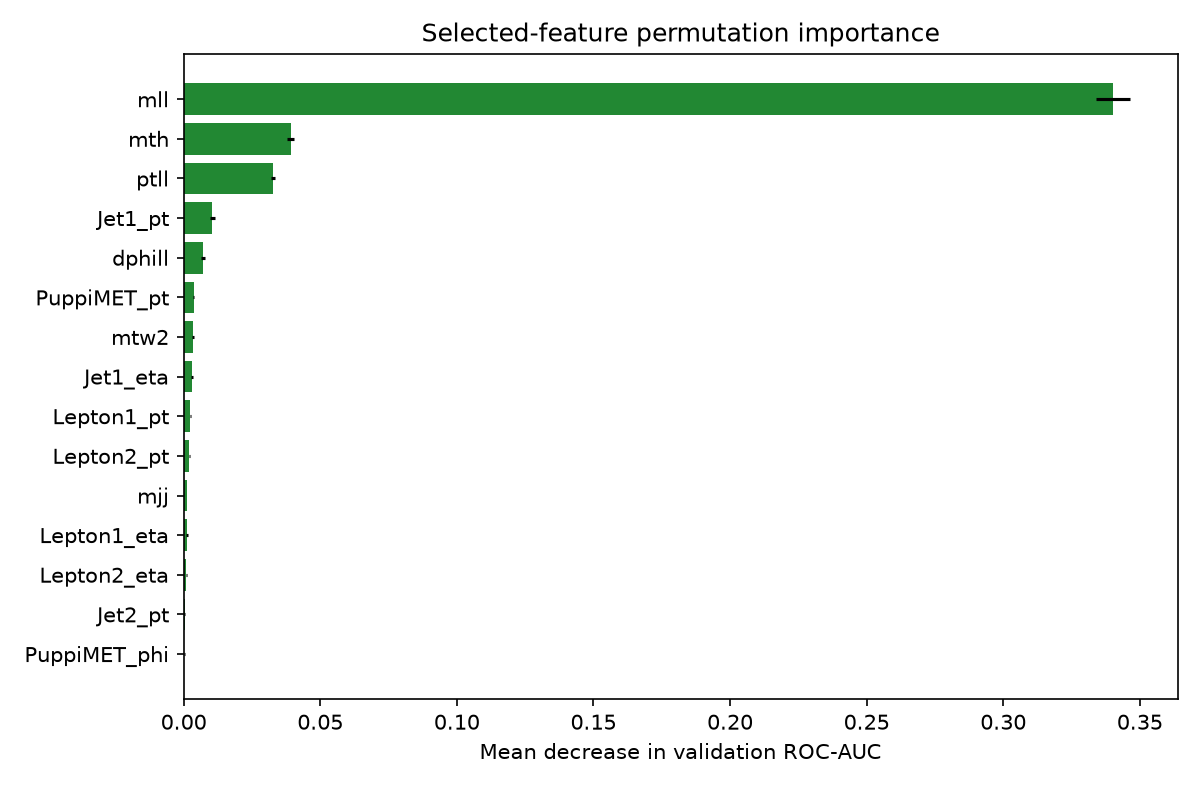

{'selected_validation_metrics': {'ROC-AUC': 0.9104846346852328, 'average_precision': 0.5207495412611388, 'accuracy': 0.8129060199220441, 'balanced_accuracy': 0.84140284574588, 'precision': 0.36024939172749393, 'recall': 0.8780578206078576, 'F1': 0.510890662065991}, 'frozen_threshold': 0.12657913433680507, 'rule': 'maximize validation balanced accuracy; ties use the highest threshold'}


| option | model | feature_set | threshold | validation_ROC_AUC | validation_AP | validation_balanced_accuracy | train_minus_validation_AUC |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Option A — reproduced validation reference | option_a_hist_gradient_boosting_3_top10 | top_10 | 0.1154 | 0.9096 | 0.5196 | 0.8412 | 0.01182 |
| Option B — selected validation candidate | lightgbm_leaves31_160 | top_15 | 0.1266 | 0.9105 | 0.5207 | 0.8414 | 0.01603 |

| metric | Option B minus Option A mean | paired 95% CI | replicates |
| --- | --- | --- | --- |
| ROC-AUC | 0.0008512 | [0.00014879252394237041,0.001497458371233101] | 1000 |
| average_precision | 0.001371 | [-0.0037444715208689167,0.006802202958326073] | 1000 |

Option A was reproduced from its recorded configuration on the same fitting/validation split; Option B model selection used validation results only. A paired interval spanning zero does not establish a meaningful improvement.


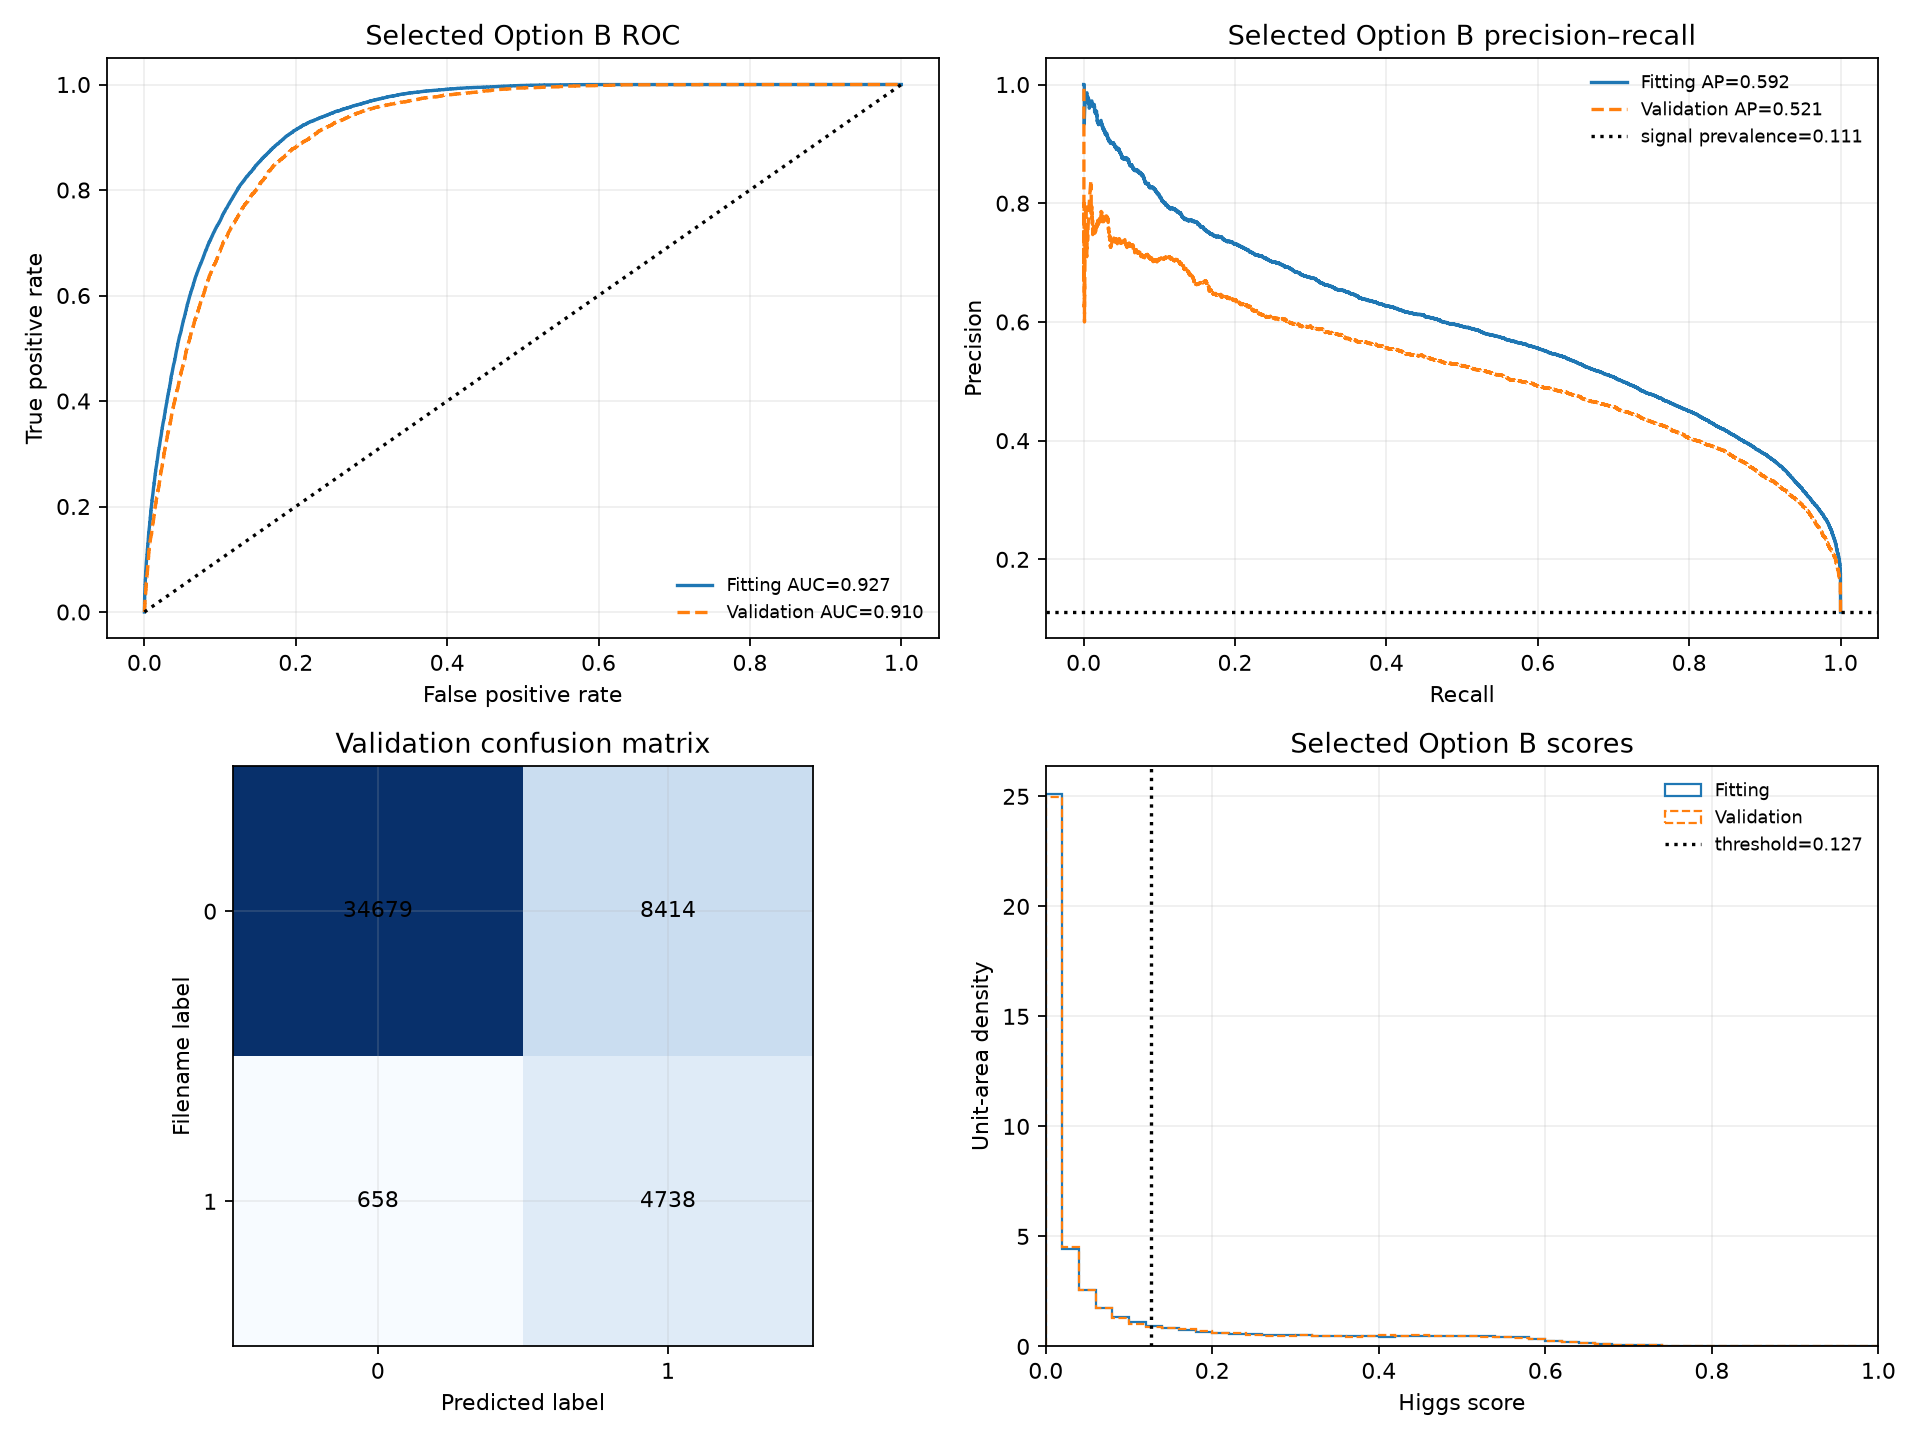

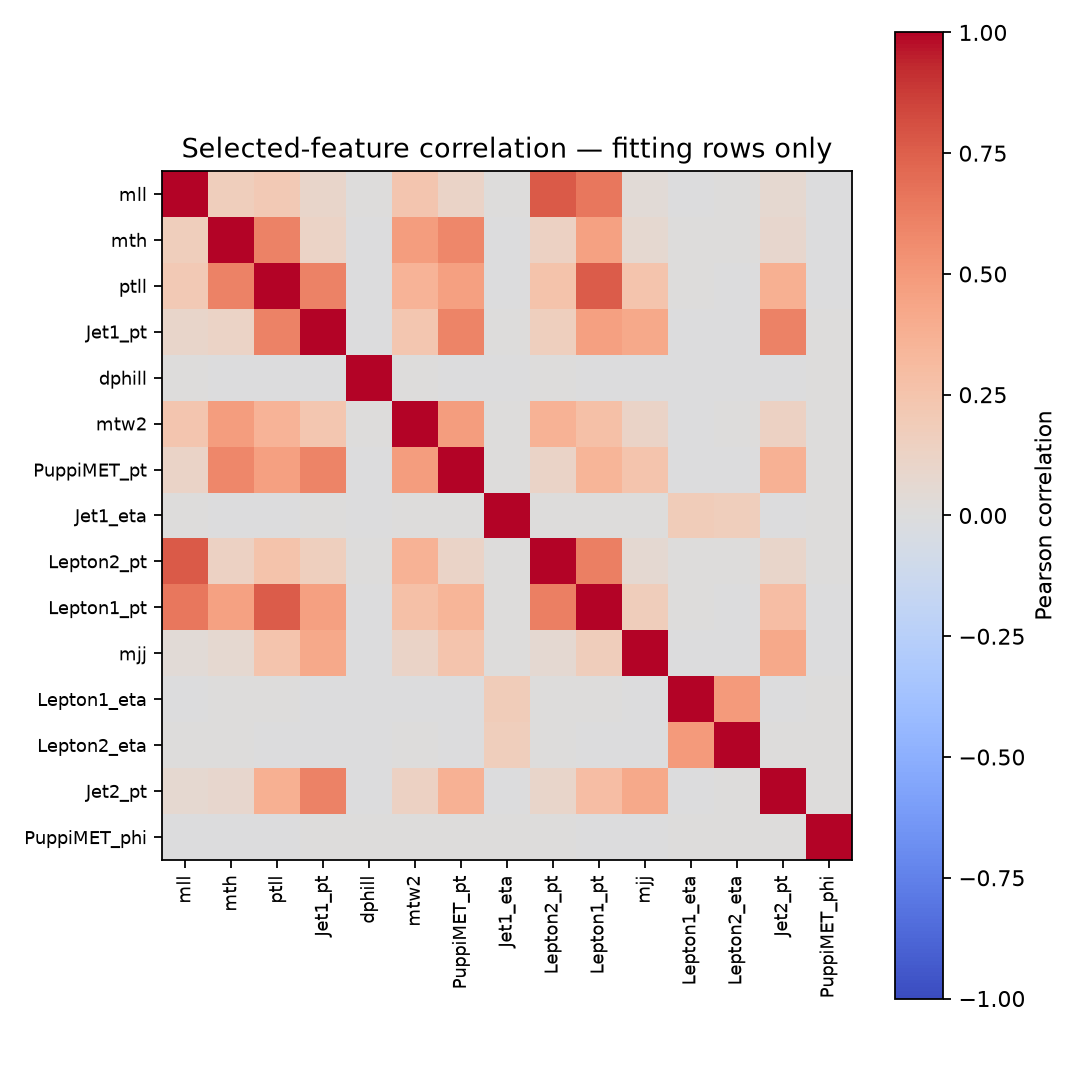

In [10]:
selected_cols = [FEATURES.index(f) for f in selected_features]
selected_importance_ref = "importance_full.png"
if selected_name != "full":
    with threadpool_limits(limits=estimator_thread_limit(winner)):
        selected_imp = permutation_importance(
            selected_estimator,
            X_val[imp_ix][:, selected_cols],
            y_val[imp_ix],
            scoring="roc_auc",
            n_repeats=IMPORTANCE_REPEATS,
            random_state=SEED,
            n_jobs=1,
        )
    fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * len(selected_features))))
    oo = np.argsort(selected_imp.importances_mean)[::-1]
    ax.barh(
        range(len(oo)),
        selected_imp.importances_mean[oo],
        xerr=selected_imp.importances_std[oo],
        color="#228833",
    )
    ax.set_yticks(range(len(oo)), [selected_features[i] for i in oo])
    ax.invert_yaxis()
    ax.set(
        xlabel="Mean decrease in validation ROC-AUC",
        title="Selected-feature permutation importance",
    )
    fig.tight_layout()
    selected_importance_ref = "importance_selected.png"
    fig.savefig(OUT_DIR / selected_importance_ref, dpi=150)
    display(Image(filename=str(OUT_DIR / selected_importance_ref)))
    plt.close(fig)
else:
    print("Full-feature importance also applies to selected model.")

# Freeze the threshold from validation balanced accuracy; ties choose the highest threshold.
fpr, tpr, th = roc_curve(y_val, selected_val_score)
ba = (tpr + 1 - fpr) / 2
FROZEN_THRESHOLD = float(th[np.flatnonzero(ba == ba.max())[-1]])
val_metrics = metrics(y_val, selected_val_score, FROZEN_THRESHOLD)
fit_score = selected_estimator.predict_proba(X_fit[:, selected_cols])[:, 1]
fit_metrics = metrics(y_fit, fit_score, FROZEN_THRESHOLD)
print(
    {
        "selected_validation_metrics": val_metrics,
        "frozen_threshold": FROZEN_THRESHOLD,
        "rule": THRESHOLD_RULE,
    }
)

# Refit Option A's documented model and top-10 features on this same fitting split.
# This is a validation reference outside the predeclared 18-configuration Option B search.
OPTION_A_FEATURES = [
    "mll", "mth", "ptll", "Jet1_pt", "dphill", "PuppiMET_pt",
    "mtw2", "Jet1_eta", "Lepton1_eta", "Lepton1_pt",
]
OPTION_A_CONFIG = {
    "family": "hist_gradient_boosting",
    "id": "option_a_hist_gradient_boosting_3_top10",
    "params": {
        "max_leaf_nodes": 31,
        "learning_rate": 0.1,
        "max_iter": 100,
        "l2_regularization": 1.0,
        "early_stopping": False,
    },
    "backend": "CPU",
    "device": "cpu",
    "library_version": sklearn.__version__,
    "workers": HGB_THREADS,
}
option_a_cols = [FEATURES.index(feature) for feature in OPTION_A_FEATURES]
option_a_estimator = make_estimator(OPTION_A_CONFIG)
with threadpool_limits(limits=HGB_THREADS):
    option_a_estimator.fit(X_fit[:, option_a_cols], y_fit)
    option_a_fit_scores = option_a_estimator.predict_proba(X_fit[:, option_a_cols])[:, 1]
    option_a_validation_scores = option_a_estimator.predict_proba(X_val[:, option_a_cols])[:, 1]
option_a_fpr, option_a_tpr, option_a_thresholds = roc_curve(y_val, option_a_validation_scores)
option_a_balanced_accuracy = (option_a_tpr + 1 - option_a_fpr) / 2
option_a_threshold = float(
    option_a_thresholds[np.flatnonzero(option_a_balanced_accuracy == option_a_balanced_accuracy.max())[-1]]
)
option_a_validation_metrics = metrics(y_val, option_a_validation_scores, option_a_threshold)
option_a_train_auc = float(roc_auc_score(y_fit, option_a_fit_scores))
OPTION_A_RECORDED_VALIDATION = {
    "ROC-AUC": 0.9096383970145973,
    "average_precision": 0.5195515817292351,
    "threshold": 0.11543311965789133,
}
assert np.isclose(option_a_validation_metrics["ROC-AUC"], OPTION_A_RECORDED_VALIDATION["ROC-AUC"], rtol=0, atol=1e-12)
assert np.isclose(option_a_validation_metrics["average_precision"], OPTION_A_RECORDED_VALIDATION["average_precision"], rtol=0, atol=1e-12)
assert np.isclose(option_a_threshold, OPTION_A_RECORDED_VALIDATION["threshold"], rtol=0, atol=1e-12)

option_b_train_auc = float(roc_auc_score(y_fit, fit_score))
option_a_comparison = [
    {
        "option": "Option A — reproduced validation reference",
        "model": OPTION_A_CONFIG["id"],
        "feature_set": "top_10",
        "threshold": option_a_threshold,
        "validation_ROC_AUC": option_a_validation_metrics["ROC-AUC"],
        "validation_AP": option_a_validation_metrics["average_precision"],
        "validation_balanced_accuracy": option_a_validation_metrics["balanced_accuracy"],
        "train_minus_validation_AUC": option_a_train_auc - option_a_validation_metrics["ROC-AUC"],
    },
    {
        "option": "Option B — selected validation candidate",
        "model": winner["id"],
        "feature_set": selected_name,
        "threshold": FROZEN_THRESHOLD,
        "validation_ROC_AUC": val_metrics["ROC-AUC"],
        "validation_AP": val_metrics["average_precision"],
        "validation_balanced_accuracy": val_metrics["balanced_accuracy"],
        "train_minus_validation_AUC": option_b_train_auc - val_metrics["ROC-AUC"],
    },
]
display_table(option_a_comparison)

# Quantify the Option B minus Option A validation difference on paired event resamples.
option_a_groups, option_a_group_count = score_group_ids(option_a_validation_scores)
option_b_groups, option_b_group_count = score_group_ids(selected_val_score)
comparison_rng = np.random.default_rng(BOOTSTRAP_SEED + 50)
paired_option_a_b = {"ROC-AUC": np.empty(BOOTSTRAP_REPLICATES), "average_precision": np.empty(BOOTSTRAP_REPLICATES)}
for replicate in range(BOOTSTRAP_REPLICATES):
    positive_draw = comparison_rng.choice(pos_validation, len(pos_validation), replace=True)
    negative_draw = comparison_rng.choice(neg_validation, len(neg_validation), replace=True)
    option_a_auc, option_a_ap = grouped_auc_ap(
        option_a_groups[positive_draw], option_a_groups[negative_draw], option_a_group_count
    )
    option_b_auc, option_b_ap = grouped_auc_ap(
        option_b_groups[positive_draw], option_b_groups[negative_draw], option_b_group_count
    )
    paired_option_a_b["ROC-AUC"][replicate] = option_b_auc - option_a_auc
    paired_option_a_b["average_precision"][replicate] = option_b_ap - option_a_ap
option_a_b_bootstrap = {
    metric: {
        "mean_difference": float(np.mean(differences)),
        "CI95": [float(np.quantile(differences, 0.025)), float(np.quantile(differences, 0.975))],
    }
    for metric, differences in paired_option_a_b.items()
}
display_table(
    [
        {"metric": metric, "Option B minus Option A mean": values["mean_difference"], "paired 95% CI": values["CI95"], "replicates": BOOTSTRAP_REPLICATES}
        for metric, values in option_a_b_bootstrap.items()
    ]
)
print(
    "Option A was reproduced from its recorded configuration on the same fitting/validation split; "
    "Option B model selection used validation results only. A paired interval spanning zero does not establish a meaningful improvement."
)

# Selected-model training/validation diagnostics, all before any test-event read.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for split_name, truth, axis, style in [
    ("Fitting", y_fit, axes[0, 0], "-"),
    ("Validation", y_val, axes[0, 0], "--"),
]:
    current_scores = fit_score if split_name == "Fitting" else selected_val_score
    false_positive_rate, true_positive_rate, _ = roc_curve(truth, current_scores)
    axis.plot(false_positive_rate, true_positive_rate, ls=style, label=f"{split_name} AUC={roc_auc_score(truth, current_scores):.3f}")
axes[0, 0].plot([0, 1], [0, 1], "k:")
axes[0, 0].set(xlabel="False positive rate", ylabel="True positive rate", title="Selected Option B ROC")
for split_name, truth, axis, style in [
    ("Fitting", y_fit, axes[0, 1], "-"),
    ("Validation", y_val, axes[0, 1], "--"),
]:
    current_scores = fit_score if split_name == "Fitting" else selected_val_score
    precision, recall, _ = precision_recall_curve(truth, current_scores)
    axis.plot(recall, precision, ls=style, label=f"{split_name} AP={average_precision_score(truth, current_scores):.3f}")
axes[0, 1].axhline(y_fit.mean(), color="k", ls=":", label=f"signal prevalence={y_fit.mean():.3f}")
axes[0, 1].set(xlabel="Recall", ylabel="Precision", title="Selected Option B precision–recall")
validation_predictions = selected_val_score >= FROZEN_THRESHOLD
validation_matrix = confusion_matrix(y_val, validation_predictions)
axes[1, 0].imshow(validation_matrix, cmap="Blues")
axes[1, 0].set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted label", ylabel="Filename label", title="Validation confusion matrix")
for (row_index, column_index), value in np.ndenumerate(validation_matrix):
    axes[1, 0].text(column_index, row_index, str(value), ha="center", va="center")
bins = np.linspace(0, 1, 51)
axes[1, 1].hist(fit_score, bins=bins, density=True, histtype="step", label="Fitting")
axes[1, 1].hist(selected_val_score, bins=bins, density=True, histtype="step", ls="--", label="Validation")
axes[1, 1].axvline(FROZEN_THRESHOLD, color="k", ls=":", label=f"threshold={FROZEN_THRESHOLD:.3f}")
axes[1, 1].set(xlim=(0, 1), xlabel="Higgs score", ylabel="Unit-area density", title="Selected Option B scores")
for axis in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    axis.grid(alpha=0.2)
    axis.legend(frameon=False, fontsize=8)
axes[1, 0].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / "selected_option_b_validation_diagnostics.png", dpi=160)
display(Image(filename=str(OUT_DIR / "selected_option_b_validation_diagnostics.png")))
plt.close(fig)

if selected_name != "full":
    selected_corr = np.corrcoef(X_fit[:, selected_cols].astype(float), rowvar=False)
    fig, ax = plt.subplots(
        figsize=(
            max(6, 0.45 * len(selected_features)),
            max(5, 0.45 * len(selected_features)),
        )
    )
    im = ax.imshow(selected_corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(
        range(len(selected_features)), selected_features, rotation=90, fontsize=8
    )
    ax.set_yticks(range(len(selected_features)), selected_features, fontsize=8)
    ax.set_title("Selected-feature correlation — fitting rows only")
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "selected_feature_correlation.png", dpi=160)
    display(Image(filename=str(OUT_DIR / "selected_feature_correlation.png")))
    plt.close(fig)


## Option B freeze manifest

The manifest records the selected model, feature set, threshold, split, inputs and runtime configuration before test-event values are read. The saved estimator remains fit only on the fitting partition.


In [11]:
cfg = next(config for config in MODEL_CONFIGS if config["id"] == winner["id"])
train_meta = [row for row in inventory if row["split"] == "train"]
test_meta = [row for row in inventory if row["split"] == "test"]
manifest = {
    "schema_version": "hsf-option-b-freeze-v1",
    "status": "frozen before reading test-event values",
    "configuration": cfg,
    "selected_feature_set": selected_name,
    "features": selected_features,
    "preprocessing": "median imputer fitted on fitting rows; scaler only for logistic regression",
    "missing_policy": "NaNs median imputed from fitting rows; infinities invalid at inference; no -999 replacement",
    "seed": SEED,
    "thread_settings": {
        "available_cpus": CPU_AVAILABLE,
        "hist_gradient_boosting_and_boosting_threads": HGB_THREADS,
        "random_forest_workers": RF_WORKERS,
        "random_forest_native_threads": 1,
        "loky_max_cpu_count": os.environ.get("LOKY_MAX_CPU_COUNT"),
    },
    "gpu": {"nvidia_device": NVIDIA_DEVICE, "optional_status": OPTIONAL_STATUS},
    "split": "same as Option A: StratifiedGroupKFold(4), closest fold to 75/25 and class proportions; duplicate feature rows grouped",
    "fit_rows": len(fit_i),
    "validation_rows": len(val_i),
    "split_counts": split_counts,
    "positive_label": "Higgs inferred from filename",
    "background_labels": ["DY", "Top", "WW"],
    "class_weighting_or_resampling": "none",
    "training_files": [
        {"filename": row["filename"], "sha256": row["sha256"], "entries": row["entries"]}
        for row in train_meta
    ],
    "test_metadata_only": [
        {"filename": row["filename"], "sha256": row["sha256"], "entries": row["entries"], "branches": row["branches"], "types": row["types"]}
        for row in test_meta
    ],
    "threshold": FROZEN_THRESHOLD,
    "threshold_rule": THRESHOLD_RULE,
    "validation_metrics": val_metrics,
    "option_a_reproduced_validation_comparison": option_a_comparison,
    "option_a_paired_validation_differences": option_a_b_bootstrap,
    "candidate_search": {
        "budget": 18,
        "attempted": len(attempts),
        "successful": len(rows),
        "failed": len(attempts) - len(rows),
        "attempts": attempts,
        "family_allocations": family_allocations,
        "paired_leader_bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "selection_metric": "validation ROC-AUC",
    },
    "feature_search": {
        "sets": [{"name": name, "features": feature_list} for name, feature_list in sets],
        "count": len(sets),
        "importance_repeats": IMPORTANCE_REPEATS,
        "importance_row_cap": IMPORTANCE_ROW_CAP,
        "importance_rows": len(imp_ix),
        "importance_seed": SEED,
        "paired_bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "AUC_loss_tolerance": EPS_AUC,
        "AP_loss_tolerance": EPS_AP,
        "selection_rule": "reduced set accepted only if both upper one-sided 95% paired-bootstrap loss bounds meet tolerances; fewest features wins, then higher AUC and AP",
    },
    "versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "scikit_learn": sklearn.__version__,
        "uproot": uproot.__version__,
        "xgboost": OPTIONAL_IMPORTS["xgboost"],
        "lightgbm": OPTIONAL_IMPORTS["lightgbm"],
    },
    "limitations": [
        "filename labels do not verify CMS process identities or decays",
        "train/test event-level independence is not established",
        "Option A already inspected these test files; Option B test results are exploratory",
        "one validation split and selection among many candidates may yield optimistic performance",
        "no generator weights or physics normalization are applied",
    ],
}
model_path = OUT_DIR / "frozen_pipeline.pkl"
manifest_path = OUT_DIR / "freeze_manifest.json"
config_path = OUT_DIR / "frozen_config.json"
for output_path in [model_path, manifest_path, config_path]:
    if output_path.exists():
        raise FileExistsError(output_path)
with model_path.open("wb") as output_file:
    pickle.dump(
        {
            "estimator": selected_estimator,
            "features": selected_features,
            "threshold": FROZEN_THRESHOLD,
            "manifest": manifest,
        },
        output_file,
    )
manifest_path.write_text(json.dumps(manifest, indent=2))
config_path.write_text(
    json.dumps(
        {
            "configuration": cfg,
            "features": selected_features,
            "threshold": FROZEN_THRESHOLD,
            "seed": SEED,
            "option": "B — extended validation-selected experiment",
        },
        indent=2,
    )
)
with model_path.open("rb") as model_file:
    reloaded = pickle.load(model_file)
roundtrip_scores = reloaded["estimator"].predict_proba(X_val[:, selected_cols])[:, 1]
roundtrip_max_abs_error = float(np.max(np.abs(roundtrip_scores - selected_val_score)))
assert np.allclose(roundtrip_scores, selected_val_score, rtol=0, atol=1e-12)
FROZEN = True

display(Markdown("```json\n" + json.dumps({key: manifest[key] for key in ["configuration", "selected_feature_set", "features", "seed", "split", "threshold", "validation_metrics", "candidate_search", "feature_search"]}, indent=2) + "\n```"))
print(
    {
        "FROZEN": FROZEN,
        "manifest_path": str(manifest_path),
        "model_path": str(model_path),
        "roundtrip_max_abs_error": roundtrip_max_abs_error,
        "output_directory": str(OUT_DIR),
    }
)


```json
{
  "configuration": {
    "family": "lightgbm",
    "id": "lightgbm_leaves31_160",
    "params": {
      "n_estimators": 160,
      "num_leaves": 31,
      "max_depth": -1,
      "learning_rate": 0.08,
      "reg_lambda": 1.0
    },
    "backend": "CPU",
    "device": "cpu",
    "library_version": "4.7.0",
    "workers": 4
  },
  "selected_feature_set": "top_15",
  "features": [
    "mll",
    "mth",
    "ptll",
    "Jet1_pt",
    "dphill",
    "mtw2",
    "PuppiMET_pt",
    "Jet1_eta",
    "Lepton2_pt",
    "Lepton1_pt",
    "mjj",
    "Lepton1_eta",
    "Lepton2_eta",
    "Jet2_pt",
    "PuppiMET_phi"
  ],
  "seed": 20261015,
  "split": "same as Option A: StratifiedGroupKFold(4), closest fold to 75/25 and class proportions; duplicate feature rows grouped",
  "threshold": 0.12657913433680507,
  "validation_metrics": {
    "ROC-AUC": 0.9104846346852328,
    "average_precision": 0.5207495412611388,
    "accuracy": 0.8129060199220441,
    "balanced_accuracy": 0.84140284574588,
    "precision": 0.36024939172749393,
    "recall": 0.8780578206078576,
    "F1": 0.510890662065991
  },
  "candidate_search": {
    "budget": 18,
    "attempted": 18,
    "successful": 18,
    "failed": 0,
    "attempts": [
      {
        "id": "logistic_C_0.05",
        "family": "logistic_regression",
        "params": {
          "C": 0.05,
          "max_iter": 2000
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 0.5806028750084806,
        "train_auc": 0.8612385000249422,
        "validation": {
          "ROC-AUC": 0.865409862600509,
          "average_precision": 0.40993689081692625,
          "accuracy": 0.8893151023943575,
          "balanced_accuracy": 0.5688308447895123,
          "precision": 0.5087296809151114,
          "recall": 0.15659747961452927,
          "F1": 0.23947853195408814
        },
        "gap": -0.004171362575566828,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "logistic_C_0.3",
        "family": "logistic_regression",
        "params": {
          "C": 0.3,
          "max_iter": 2000
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 0.6655442499904893,
        "train_auc": 0.8612138503796597,
        "validation": {
          "ROC-AUC": 0.8653562135692975,
          "average_precision": 0.4101006891843579,
          "accuracy": 0.889438841799171,
          "balanced_accuracy": 0.5724670320574958,
          "precision": 0.5100401606425703,
          "recall": 0.16475166790214973,
          "F1": 0.24905448942428912
        },
        "gap": -0.004142363189637788,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "logistic_C_3",
        "family": "logistic_regression",
        "params": {
          "C": 3.0,
          "max_iter": 2000
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 0.5930807080003433,
        "train_auc": 0.8612060587866699,
        "validation": {
          "ROC-AUC": 0.865346135292372,
          "average_precision": 0.4101773779844324,
          "accuracy": 0.889438841799171,
          "balanced_accuracy": 0.5728723241475928,
          "precision": 0.5099828864803194,
          "recall": 0.16567828020756115,
          "F1": 0.25010490977759126
        },
        "gap": -0.004140076505702139,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "decision_tree_depth3_leaf20",
        "family": "decision_tree",
        "params": {
          "max_depth": 3,
          "min_samples_leaf": 20
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 1.3357452920172364,
        "train_auc": 0.8659840517798478,
        "validation": {
          "ROC-AUC": 0.867860550346255,
          "average_precision": 0.3729818602575309,
          "accuracy": 0.8887170286044257,
          "balanced_accuracy": 0.5,
          "precision": 0.0,
          "recall": 0.0,
          "F1": 0.0
        },
        "gap": -0.0018764985664071476,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "decision_tree_depth5_leaf10",
        "family": "decision_tree",
        "params": {
          "max_depth": 5,
          "min_samples_leaf": 10
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 1.8811064580222592,
        "train_auc": 0.8883555917155044,
        "validation": {
          "ROC-AUC": 0.8880088536426389,
          "average_precision": 0.4183831768285826,
          "accuracy": 0.8911093237641527,
          "balanced_accuracy": 0.6127201926111604,
          "precision": 0.5220364741641338,
          "recall": 0.25463306152705706,
          "F1": 0.3423019431988042
        },
        "gap": 0.000346738072865449,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "decision_tree_depth8_leaf10",
        "family": "decision_tree",
        "params": {
          "max_depth": 8,
          "min_samples_leaf": 10
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 2.604630082991207,
        "train_auc": 0.9053819633936263,
        "validation": {
          "ROC-AUC": 0.8953406012066546,
          "average_precision": 0.45600292411232424,
          "accuracy": 0.8931716471777104,
          "balanced_accuracy": 0.6167175184940145,
          "precision": 0.5415065334358186,
          "recall": 0.261119347664937,
          "F1": 0.3523380845211303
        },
        "gap": 0.010041362186971714,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "random_forest_160_depth8",
        "family": "random_forest",
        "params": {
          "n_estimators": 160,
          "max_depth": 8,
          "min_samples_leaf": 1
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 8,
        "runtime_seconds": 8.764936541003408,
        "train_auc": 0.9077165766640677,
        "validation": {
          "ROC-AUC": 0.8995736538367886,
          "average_precision": 0.4844187891243562,
          "accuracy": 0.8887788983068324,
          "balanced_accuracy": 0.5002779836916235,
          "precision": 1.0,
          "recall": 0.0005559673832468495,
          "F1": 0.0011113169105389886
        },
        "gap": 0.008142922827279131,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "random_forest_200_depth16",
        "family": "random_forest",
        "params": {
          "n_estimators": 200,
          "max_depth": 16,
          "min_samples_leaf": 5
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 8,
        "runtime_seconds": 14.611820666992571,
        "train_auc": 0.9649301833034323,
        "validation": {
          "ROC-AUC": 0.9070035995554085,
          "average_precision": 0.5099121644800584,
          "accuracy": 0.8975850192827239,
          "balanced_accuracy": 0.6119863211699448,
          "precision": 0.5972850678733032,
          "recall": 0.2446256486286138,
          "F1": 0.34709439915855905
        },
        "gap": 0.05792658374802373,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "random_forest_240_unlimited_leaf10",
        "family": "random_forest",
        "params": {
          "n_estimators": 240,
          "max_depth": null,
          "min_samples_leaf": 10
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 8,
        "runtime_seconds": 19.06131441699108,
        "train_auc": 0.9716252201989904,
        "validation": {
          "ROC-AUC": 0.907331529527472,
          "average_precision": 0.506458240538596,
          "accuracy": 0.8981212233702489,
          "balanced_accuracy": 0.6179620835568674,
          "precision": 0.5981067125645438,
          "recall": 0.2575982209043736,
          "F1": 0.3601036269430052
        },
        "gap": 0.06429369067151847,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "hist_gradient_boosting_leaves7_lr005",
        "family": "hist_gradient_boosting",
        "params": {
          "max_leaf_nodes": 7,
          "learning_rate": 0.05,
          "max_iter": 100,
          "l2_regularization": 1.0,
          "early_stopping": false
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 1.937277749995701,
        "train_auc": 0.9039435159164947,
        "validation": {
          "ROC-AUC": 0.9043987939474156,
          "average_precision": 0.5015494645051121,
          "accuracy": 0.8965951040442162,
          "balanced_accuracy": 0.5901920806478212,
          "precision": 0.6101499423298731,
          "recall": 0.1960711638250556,
          "F1": 0.2967741935483871
        },
        "gap": -0.0004552780309209359,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "hist_gradient_boosting_leaves15_lr008",
        "family": "hist_gradient_boosting",
        "params": {
          "max_leaf_nodes": 15,
          "learning_rate": 0.08,
          "max_iter": 150,
          "l2_regularization": 1.0,
          "early_stopping": false
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 2.853605082986178,
        "train_auc": 0.9166426073876996,
        "validation": {
          "ROC-AUC": 0.9101716189288197,
          "average_precision": 0.5218696138626006,
          "accuracy": 0.8995442265256037,
          "balanced_accuracy": 0.6376492890193856,
          "precision": 0.5964718853362734,
          "recall": 0.3007783543365456,
          "F1": 0.39990144141924355
        },
        "gap": 0.006470988458879945,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "hist_gradient_boosting_leaves31_lr01",
        "family": "hist_gradient_boosting",
        "params": {
          "max_leaf_nodes": 31,
          "learning_rate": 0.1,
          "max_iter": 150,
          "l2_regularization": 2.0,
          "early_stopping": false
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "1.9.1",
        "workers": 4,
        "runtime_seconds": 3.041582959005609,
        "train_auc": 0.9287159846291491,
        "validation": {
          "ROC-AUC": 0.9103673486568786,
          "average_precision": 0.5211093160660029,
          "accuracy": 0.8993173709501124,
          "balanced_accuracy": 0.6480592524241664,
          "precision": 0.5858957219251337,
          "recall": 0.3248702742772424,
          "F1": 0.41797806390081066
        },
        "gap": 0.018348635972270433,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "xgboost_depth3_120",
        "family": "xgboost",
        "params": {
          "n_estimators": 120,
          "max_depth": 3,
          "learning_rate": 0.05,
          "reg_lambda": 1.0
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "3.4.1",
        "workers": 4,
        "runtime_seconds": 0.8734390000172425,
        "train_auc": 0.9028817641981541,
        "validation": {
          "ROC-AUC": 0.9034752586666,
          "average_precision": 0.489132528503044,
          "accuracy": 0.8943884179917094,
          "balanced_accuracy": 0.5861945934953343,
          "precision": 0.577552171460801,
          "recall": 0.18977020014825796,
          "F1": 0.28567443158041567
        },
        "gap": -0.0005934944684458099,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "xgboost_depth4_160",
        "family": "xgboost",
        "params": {
          "n_estimators": 160,
          "max_depth": 4,
          "learning_rate": 0.08,
          "reg_lambda": 1.0
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "3.4.1",
        "workers": 4,
        "runtime_seconds": 0.9773827909957618,
        "train_auc": 0.9144731607412436,
        "validation": {
          "ROC-AUC": 0.9098485012426019,
          "average_precision": 0.5195783850484273,
          "accuracy": 0.8997298356328239,
          "balanced_accuracy": 0.6333765597590344,
          "precision": 0.6025345622119815,
          "recall": 0.2907709414381023,
          "F1": 0.39225
        },
        "gap": 0.00462465949864177,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "xgboost_depth5_200",
        "family": "xgboost",
        "params": {
          "n_estimators": 200,
          "max_depth": 5,
          "learning_rate": 0.1,
          "reg_lambda": 2.0
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "3.4.1",
        "workers": 4,
        "runtime_seconds": 1.199665374995675,
        "train_auc": 0.926169485997202,
        "validation": {
          "ROC-AUC": 0.9103926443363644,
          "average_precision": 0.5221958396104786,
          "accuracy": 0.8998329518035019,
          "balanced_accuracy": 0.6449448691803961,
          "precision": 0.5934790149150191,
          "recall": 0.3170867309117865,
          "F1": 0.4133349438337964
        },
        "gap": 0.015776841660837593,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "lightgbm_leaves15_120",
        "family": "lightgbm",
        "params": {
          "n_estimators": 120,
          "num_leaves": 15,
          "max_depth": -1,
          "learning_rate": 0.05,
          "reg_lambda": 1.0
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "4.7.0",
        "workers": 4,
        "runtime_seconds": 1.368111542018596,
        "train_auc": 0.9116799914852692,
        "validation": {
          "ROC-AUC": 0.9093226611770426,
          "average_precision": 0.5202565158937467,
          "accuracy": 0.899482356823197,
          "balanced_accuracy": 0.6291033466897846,
          "precision": 0.60381861575179,
          "recall": 0.28131949592290584,
          "F1": 0.3838179519595449
        },
        "gap": 0.0023573303082266017,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "lightgbm_leaves31_160",
        "family": "lightgbm",
        "params": {
          "n_estimators": 160,
          "num_leaves": 31,
          "max_depth": -1,
          "learning_rate": 0.08,
          "reg_lambda": 1.0
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "4.7.0",
        "workers": 4,
        "runtime_seconds": 1.827774875011528,
        "train_auc": 0.9272036883228018,
        "validation": {
          "ROC-AUC": 0.9105495145336794,
          "average_precision": 0.5205435773534758,
          "accuracy": 0.8988842830332653,
          "balanced_accuracy": 0.6453027824026085,
          "precision": 0.5835310064384954,
          "recall": 0.3191252779836916,
          "F1": 0.4126033305379178
        },
        "gap": 0.016654173789122373,
        "warnings": [],
        "success": true,
        "failure_reason": null
      },
      {
        "id": "lightgbm_leaves31_200",
        "family": "lightgbm",
        "params": {
          "n_estimators": 200,
          "num_leaves": 31,
          "max_depth": -1,
          "learning_rate": 0.1,
          "reg_lambda": 2.0
        },
        "backend": "CPU",
        "device": "cpu",
        "library_version": "4.7.0",
        "workers": 4,
        "runtime_seconds": 2.0367895839735866,
        "train_auc": 0.9336410070271837,
        "validation": {
          "ROC-AUC": 0.9099766998494491,
          "average_precision": 0.5170235135708762,
          "accuracy": 0.8983068324774691,
          "balanced_accuracy": 0.6465990720123871,
          "precision": 0.5770122557138125,
          "recall": 0.32283172720533726,
          "F1": 0.4140225787284611
        },
        "gap": 0.0236643071777346,
        "warnings": [],
        "success": true,
        "failure_reason": null
      }
    ],
    "family_allocations": {
      "logistic_regression": 3,
      "decision_tree": 3,
      "random_forest": 3,
      "hist_gradient_boosting": 3,
      "xgboost": 3,
      "lightgbm": 3
    },
    "paired_leader_bootstrap_replicates": 1000,
    "selection_metric": "validation ROC-AUC"
  },
  "feature_search": {
    "sets": [
      {
        "name": "full",
        "features": [
          "Jet1_eta",
          "Jet1_phi",
          "Jet1_pt",
          "Jet2_eta",
          "Jet2_phi",
          "Jet2_pt",
          "Lepton1_eta",
          "Lepton1_phi",
          "Lepton1_pt",
          "Lepton2_eta",
          "Lepton2_phi",
          "Lepton2_pt",
          "PuppiMET_phi",
          "PuppiMET_pt",
          "dphill",
          "jet_cat",
          "mjj",
          "mll",
          "mth",
          "mtw2",
          "njet",
          "ptll"
        ]
      },
      {
        "name": "without_leptons",
        "features": [
          "Jet1_eta",
          "Jet1_phi",
          "Jet1_pt",
          "Jet2_eta",
          "Jet2_phi",
          "Jet2_pt",
          "PuppiMET_phi",
          "PuppiMET_pt",
          "dphill",
          "jet_cat",
          "mjj",
          "mll",
          "mth",
          "mtw2",
          "njet",
          "ptll"
        ]
      },
      {
        "name": "without_missing_momentum",
        "features": [
          "Jet1_eta",
          "Jet1_phi",
          "Jet1_pt",
          "Jet2_eta",
          "Jet2_phi",
          "Jet2_pt",
          "Lepton1_eta",
          "Lepton1_phi",
          "Lepton1_pt",
          "Lepton2_eta",
          "Lepton2_phi",
          "Lepton2_pt",
          "dphill",
          "jet_cat",
          "mjj",
          "mll",
          "mth",
          "mtw2",
          "njet",
          "ptll"
        ]
      },
      {
        "name": "without_jets",
        "features": [
          "Lepton1_eta",
          "Lepton1_phi",
          "Lepton1_pt",
          "Lepton2_eta",
          "Lepton2_phi",
          "Lepton2_pt",
          "PuppiMET_phi",
          "PuppiMET_pt",
          "dphill",
          "mll",
          "mth",
          "mtw2",
          "ptll"
        ]
      },
      {
        "name": "without_dilepton_derived",
        "features": [
          "Jet1_eta",
          "Jet1_phi",
          "Jet1_pt",
          "Jet2_eta",
          "Jet2_phi",
          "Jet2_pt",
          "Lepton1_eta",
          "Lepton1_phi",
          "Lepton1_pt",
          "Lepton2_eta",
          "Lepton2_phi",
          "Lepton2_pt",
          "PuppiMET_phi",
          "PuppiMET_pt",
          "jet_cat",
          "mjj",
          "njet"
        ]
      },
      {
        "name": "top_5",
        "features": [
          "mll",
          "mth",
          "ptll",
          "Jet1_pt",
          "dphill"
        ]
      },
      {
        "name": "top_10",
        "features": [
          "mll",
          "mth",
          "ptll",
          "Jet1_pt",
          "dphill",
          "mtw2",
          "PuppiMET_pt",
          "Jet1_eta",
          "Lepton2_pt",
          "Lepton1_pt"
        ]
      },
      {
        "name": "top_15",
        "features": [
          "mll",
          "mth",
          "ptll",
          "Jet1_pt",
          "dphill",
          "mtw2",
          "PuppiMET_pt",
          "Jet1_eta",
          "Lepton2_pt",
          "Lepton1_pt",
          "mjj",
          "Lepton1_eta",
          "Lepton2_eta",
          "Jet2_pt",
          "PuppiMET_phi"
        ]
      },
      {
        "name": "without_mll",
        "features": [
          "Jet1_eta",
          "Jet1_phi",
          "Jet1_pt",
          "Jet2_eta",
          "Jet2_phi",
          "Jet2_pt",
          "Lepton1_eta",
          "Lepton1_phi",
          "Lepton1_pt",
          "Lepton2_eta",
          "Lepton2_phi",
          "Lepton2_pt",
          "PuppiMET_phi",
          "PuppiMET_pt",
          "dphill",
          "jet_cat",
          "mjj",
          "mth",
          "mtw2",
          "njet",
          "ptll"
        ]
      }
    ],
    "count": 9,
    "importance_repeats": 5,
    "importance_row_cap": 20000,
    "importance_rows": 20000,
    "importance_seed": 20261015,
    "paired_bootstrap_replicates": 1000,
    "AUC_loss_tolerance": 0.01,
    "AP_loss_tolerance": 0.01,
    "selection_rule": "reduced set accepted only if both upper one-sided 95% paired-bootstrap loss bounds meet tolerances; fewest features wins, then higher AUC and AP"
  }
}
```

{'FROZEN': True, 'manifest_path': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification_extended/om_rishabh_hsf_classification_extended_20261016_v3/freeze_manifest.json', 'model_path': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification_extended/om_rishabh_hsf_classification_extended_20261016_v3/frozen_pipeline.pkl', 'roundtrip_max_abs_error': 0.0, 'output_directory': '/Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification_extended/om_rishabh_hsf_classification_extended_20261016_v3'}


## Exploratory test diagnostics — not a fresh holdout

Option A already evaluated these same test files. After the Option B freeze manifest is written, we score them once for descriptive diagnostics only. Do not interpret this as an unbiased final comparison, and do not use these results to alter the candidate.


In [12]:
# Test event values are read only after the freeze manifest has been written.
assert FROZEN, "Test event values require a recorded freeze manifest."
t = time.perf_counter()
test_by_class = {}
test_label_parts = []
for fn in TEST_FILES:
    assert FROZEN
    c = fn.split("-")[0]
    a = read_matrix(DATA_DIR / fn)
    test_by_class[c] = a
    test_label_parts.append(np.repeat(c, len(a)))
X_test = np.concatenate([test_by_class[c] for c in CLASSES])
lab_test = np.concatenate(test_label_parts)
y_test = (lab_test == POSITIVE_CLASS).astype(np.int8)
test_read_seconds = time.perf_counter() - t
assert len(X_test) == sum(r["entries"] for r in test_meta)
print(
    {
        "events_read": {c: len(test_by_class[c]) for c in CLASSES},
        "total": len(X_test),
        "read_seconds": test_read_seconds,
    }
)


{'events_read': {'DY': 29979, 'Higgs': 112075, 'Top': 531601, 'WW': 185741}, 'total': 859396, 'read_seconds': 0.7558094999985769}


### Data integrity and overlap

NaNs use the frozen imputer. Infinite rows are counted and excluded because they cannot be scored. All other rows remain. Exact feature matches to development and duplicates within test are descriptive; matching features do not establish event identity.

In [13]:
test_inf = np.isinf(X_test).any(axis=1)
test_nan = np.isnan(X_test).any(axis=1)
test_sentinel = (X_test == -999).any(axis=1)
valid = ~test_inf
test_keys = np.array([row_key(r) for r in X_test], dtype=object)
dev_keys = set(groups.tolist())
overlap = np.array([k in dev_keys for k in test_keys])
_, test_sizes = np.unique(test_keys, return_counts=True)
test_key_labels = {}
for key, cls in zip(test_keys, lab_test):
    test_key_labels.setdefault(key, set()).add(cls)
cross_label_test_keys = {k: v for k, v in test_key_labels.items() if len(v) > 1}
print(
    {
        "cross_label_test_feature_groups": len(cross_label_test_keys),
        "cross_label_test_rows": int(
            sum(np.sum(test_keys == k) for k in cross_label_test_keys)
        ),
        "rows": len(X_test),
        "infinite_rows_excluded": int(test_inf.sum()),
        "NaN_rows_median_imputed": int(test_nan.sum()),
        "minus_999_rows_retained": int(test_sentinel.sum()),
        "scored_rows": int(valid.sum()),
        "exact_test_development_matches": int(overlap.sum()),
        "test_duplicate_rows_after_first": int(np.sum(test_sizes[test_sizes > 1] - 1)),
    }
)


{'cross_label_test_feature_groups': 0, 'cross_label_test_rows': 0, 'rows': 859396, 'infinite_rows_excluded': 0, 'NaN_rows_median_imputed': 0, 'minus_999_rows_retained': 0, 'scored_rows': 859396, 'exact_test_development_matches': 0, 'test_duplicate_rows_after_first': 0}


### Exploratory test metrics

Metrics use the frozen validation threshold and are unweighted. The files have already been evaluated in Option A, so these are exploratory diagnostics, not an untouched comparison of the two options.


In [14]:
cols = [FEATURES.index(f) for f in selected_features]
test_score = np.full(len(X_test), np.nan)
valid_test_rows = np.flatnonzero(valid)
test_inference_started = time.perf_counter()
with threadpool_limits(limits=HGB_THREADS):
    test_score[valid_test_rows] = selected_estimator.predict_proba(
        X_test[np.ix_(valid_test_rows, cols)]
    )[:, 1]
test_inference_seconds = time.perf_counter() - test_inference_started


def bootstrap_ci(yy, ss, B, seed):
    pos = np.flatnonzero(yy == 1)
    neg = np.flatnonzero(yy == 0)
    rng = np.random.default_rng(seed)
    aa = np.empty(B)
    pp = np.empty(B)
    # Map both classes through one shared score ordering for tie handling.
    all_groups, group_count = score_group_ids(ss)
    for b in range(B):
        pos_draw = rng.choice(pos, len(pos), replace=True)
        neg_draw = rng.choice(neg, len(neg), replace=True)
        aa[b], pp[b] = grouped_auc_ap(
            all_groups[pos_draw], all_groups[neg_draw], group_count
        )
    return {
        "ROC-AUC": [float(np.quantile(aa, 0.025)), float(np.quantile(aa, 0.975))],
        "average_precision": [
            float(np.quantile(pp, 0.025)),
            float(np.quantile(pp, 0.975)),
        ],
        "replicates": B,
        "seed": seed,
    }


splits = {
    "Fitting": (y_fit, fit_score),
    "Validation": (y_val, selected_val_score),
    "Test": (y_test[valid], test_score[valid]),
}
frozen_metrics = {}
bootstrap_seconds = {}
for i, (name, (yy, ss)) in enumerate(splits.items()):
    frozen_metrics[name] = metrics(yy, ss, FROZEN_THRESHOLD)
    if name in ["Validation", "Test"]:
        bootstrap_started = time.perf_counter()
        frozen_metrics[name]["95pct_CI"] = bootstrap_ci(
            yy, ss, BOOTSTRAP_REPLICATES, BOOTSTRAP_SEED + 20 + i
        )
        bootstrap_seconds[name.lower()] = time.perf_counter() - bootstrap_started
metric_rows = []
for split_name, values in frozen_metrics.items():
    row = {key: value for key, value in values.items() if key != "95pct_CI"}
    row["split"] = split_name
    confidence_intervals = values.get("95pct_CI", {})
    for metric, column in [
        ("ROC-AUC", "AUC 95% CI"),
        ("average_precision", "AP 95% CI"),
    ]:
        interval = confidence_intervals.get(metric)
        row[column] = f"[{interval[0]:.4f}, {interval[1]:.4f}]" if interval else "—"
    metric_rows.append(row)
display_table(metric_rows)
print(
    "Option B test metrics are exploratory: Option A already inspected these files. "
    "No physics-normalized yields or unbiased Option A/Option B comparison are claimed."
)


| ROC-AUC | average_precision | accuracy | balanced_accuracy | precision | recall | F1 | split | AUC 95% CI | AP 95% CI |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.9265 | 0.5925 | 0.8217 | 0.8572 | 0.3749 | 0.903 | 0.5299 | Fitting | — | — |
| 0.9105 | 0.5207 | 0.8129 | 0.8414 | 0.3602 | 0.8781 | 0.5109 | Validation | [0.9073, 0.9135] | [0.5086, 0.5333] |
| 0.9212 | 0.5811 | 0.8299 | 0.8472 | 0.4255 | 0.8706 | 0.5717 | Test | [0.9206, 0.9219] | [0.5783, 0.5841] |

Option B test metrics are exploratory: Option A already inspected these files. No physics-normalized yields or unbiased Option A/Option B comparison are claimed.


### Frozen-model plots

ROC, precision–recall, confusion matrix and score plots use the same frozen estimator. AP baselines show each split's filename-derived Higgs prevalence.

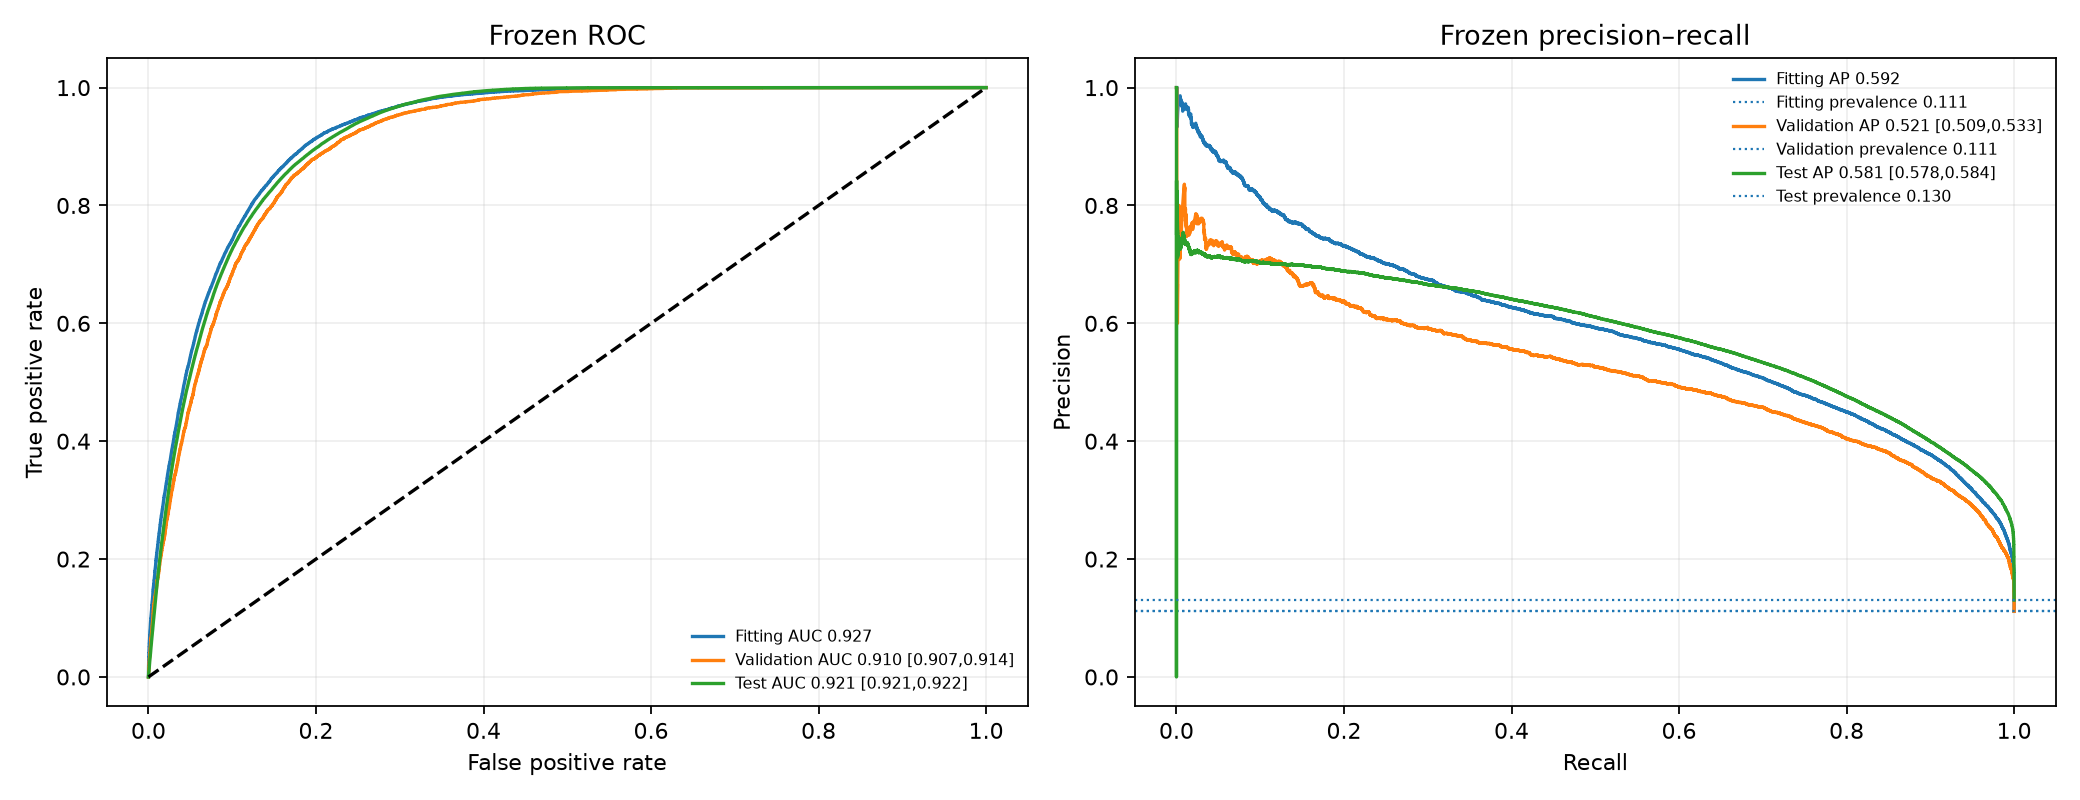

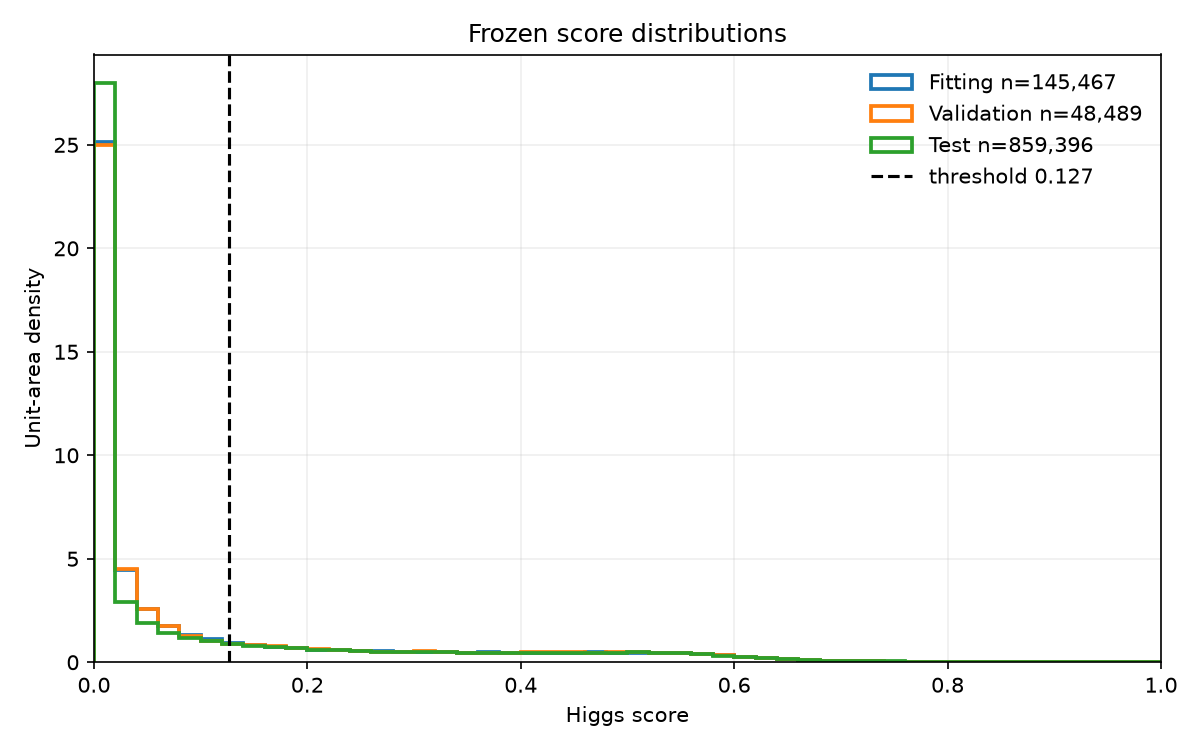

Test confusion matrix [[TN, FP], [FN, TP]]: [[615603 131718]
 [ 14501  97574]]


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for name, (yy, ss) in splits.items():
    m = frozen_metrics[name]
    fpr, tpr, _ = roc_curve(yy, ss)
    p, r, _ = precision_recall_curve(yy, ss)
    ci = m.get("95pct_CI", {})
    ac = ci.get("ROC-AUC")
    pc = ci.get("average_precision")
    axs[0].plot(
        fpr,
        tpr,
        label=f"{name} AUC {m['ROC-AUC']:.3f}"
        + (f" [{ac[0]:.3f},{ac[1]:.3f}]" if ac else ""),
    )
    axs[1].plot(
        r,
        p,
        label=f"{name} AP {m['average_precision']:.3f}"
        + (f" [{pc[0]:.3f},{pc[1]:.3f}]" if pc else ""),
    )
    axs[1].axhline(
        np.mean(yy), ls=":", lw=1, label=f"{name} prevalence {np.mean(yy):.3f}"
    )
axs[0].plot([0, 1], [0, 1], "k--")
axs[0].set(
    xlabel="False positive rate", ylabel="True positive rate", title="Frozen ROC"
)
axs[1].set(xlabel="Recall", ylabel="Precision", title="Frozen precision–recall")
for ax in axs:
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUT_DIR / "frozen_roc_pr.png", dpi=160)
display(Image(filename=str(OUT_DIR / "frozen_roc_pr.png")))
plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 5))
for name, (yy, ss) in splits.items():
    ax.hist(
        ss,
        bins=np.linspace(0, 1, 51),
        density=True,
        histtype="step",
        lw=1.8,
        label=f"{name} n={len(ss):,}",
    )
ax.axvline(
    FROZEN_THRESHOLD, color="k", ls="--", label=f"threshold {FROZEN_THRESHOLD:.3f}"
)
ax.set(
    xlim=(0, 1),
    xlabel="Higgs score",
    ylabel="Unit-area density",
    title="Frozen score distributions",
)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "frozen_score_shapes.png", dpi=150)
display(Image(filename=str(OUT_DIR / "frozen_score_shapes.png")))
plt.close(fig)
test_cm = confusion_matrix(y_test[valid], test_score[valid] >= FROZEN_THRESHOLD)
print("Test confusion matrix [[TN, FP], [FN, TP]]:", test_cm)


### Process diagnostics, KS comparisons and feature shift

KS distances and p-values are descriptive. Tied tree scores, large sample sizes, possible overlap and unverified independence limit their interpretation. A non-significant p-value would not prove absence of overtraining.

| label | comparison | n1 | n2 | D | p |
| --- | --- | --- | --- | --- | --- |
| DY | Fitting vs Validation | 29327 | 9776 | 0.01602 | 0.04586 |
| DY | Fitting vs Test | 29327 | 29979 | 0.01077 | 0.06389 |
| DY | Validation vs Test | 9776 | 29979 | 0.00686 | 0.8761 |
| Higgs | Fitting vs Validation | 16188 | 5396 | 0.04658 | 4.551e-08 |
| Higgs | Fitting vs Test | 16188 | 112075 | 0.05044 | 1.024e-31 |
| Higgs | Validation vs Test | 5396 | 112075 | 0.01434 | 0.2383 |
| Top | Fitting vs Validation | 15340 | 5113 | 0.01691 | 0.2202 |
| Top | Fitting vs Test | 15340 | 531601 | 0.0559 | 6.192e-41 |
| Top | Validation vs Test | 5113 | 531601 | 0.0528 | 1.04e-12 |
| WW | Fitting vs Validation | 84612 | 28204 | 0.008982 | 0.06547 |
| WW | Fitting vs Test | 84612 | 185741 | 0.006998 | 0.006705 |
| WW | Validation vs Test | 28204 | 185741 | 0.00413 | 0.7961 |

| label | test_count | fraction_above_threshold | Higgs_vs_process_AUC | Higgs_vs_process_AP |
| --- | --- | --- | --- | --- |
| DY | 29979 | 0.1014 | 0.9501 | 0.9857 |
| Higgs | 112075 | 0.8706 | — | — |
| Top | 531601 | 0.1646 | 0.9281 | 0.6783 |
| WW | 185741 | 0.2216 | 0.8969 | 0.7938 |

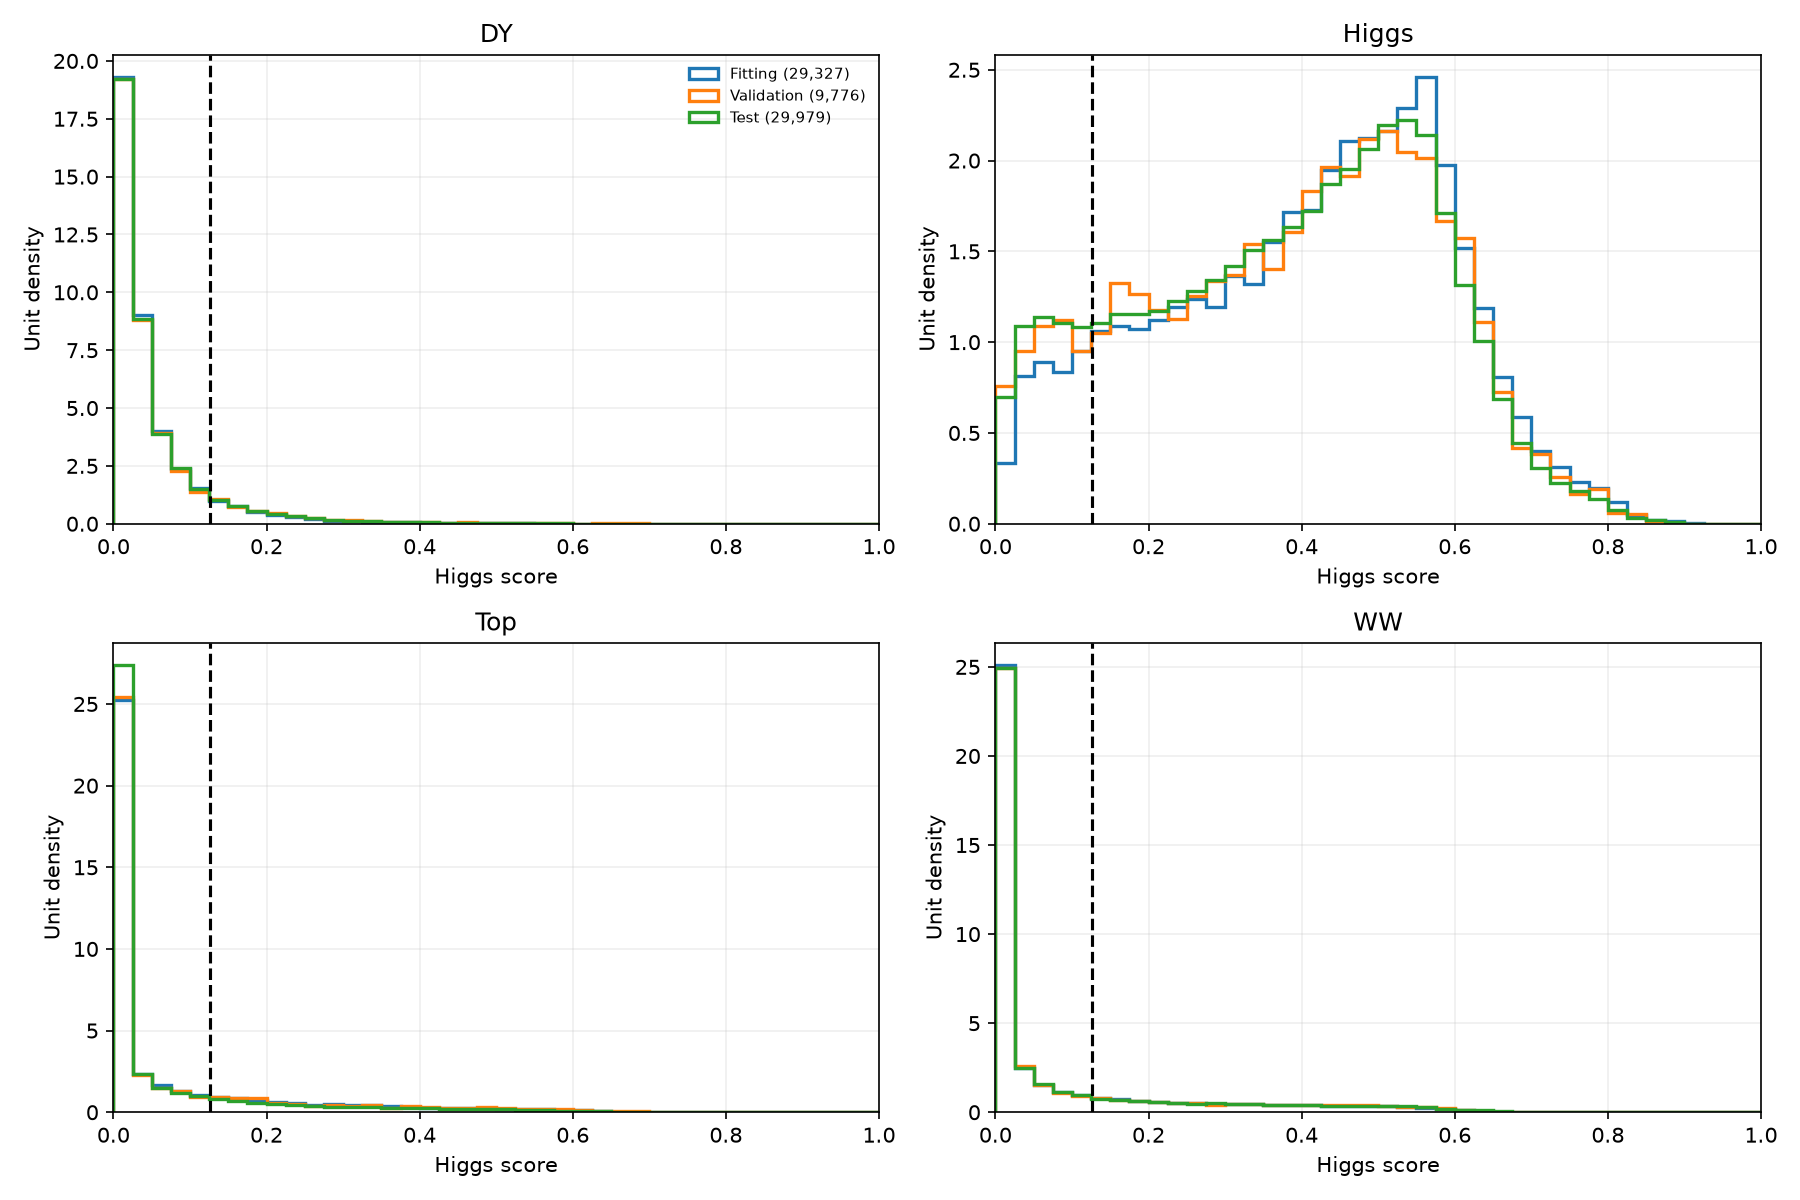

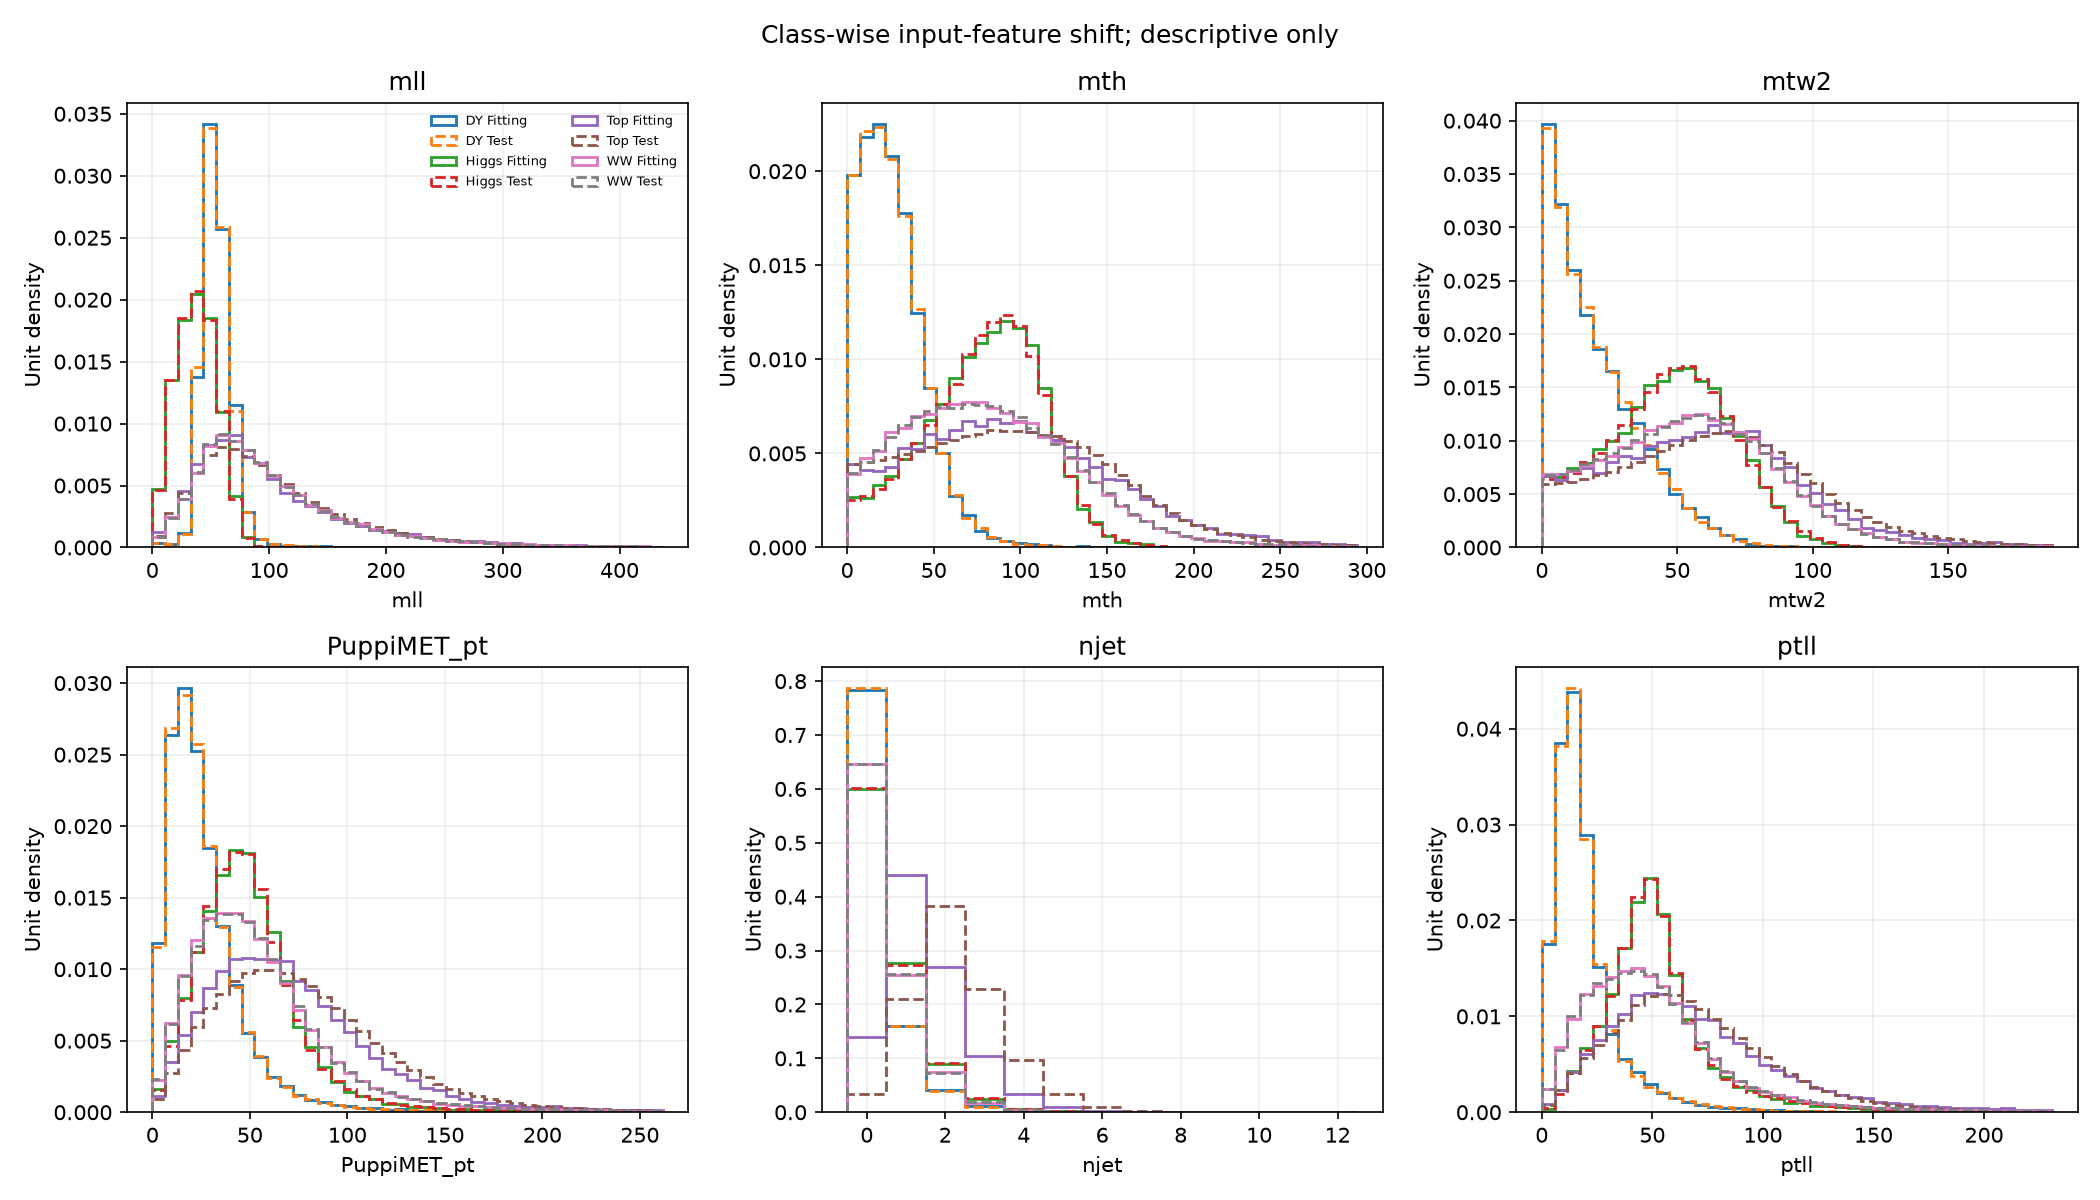

Primary test rows scored: 859,396
Exact feature-vector matches with development rows: 0
Matched-row sensitivity: no matched rows; no secondary exclusion needed
Feature-vector matches do not establish event identity.


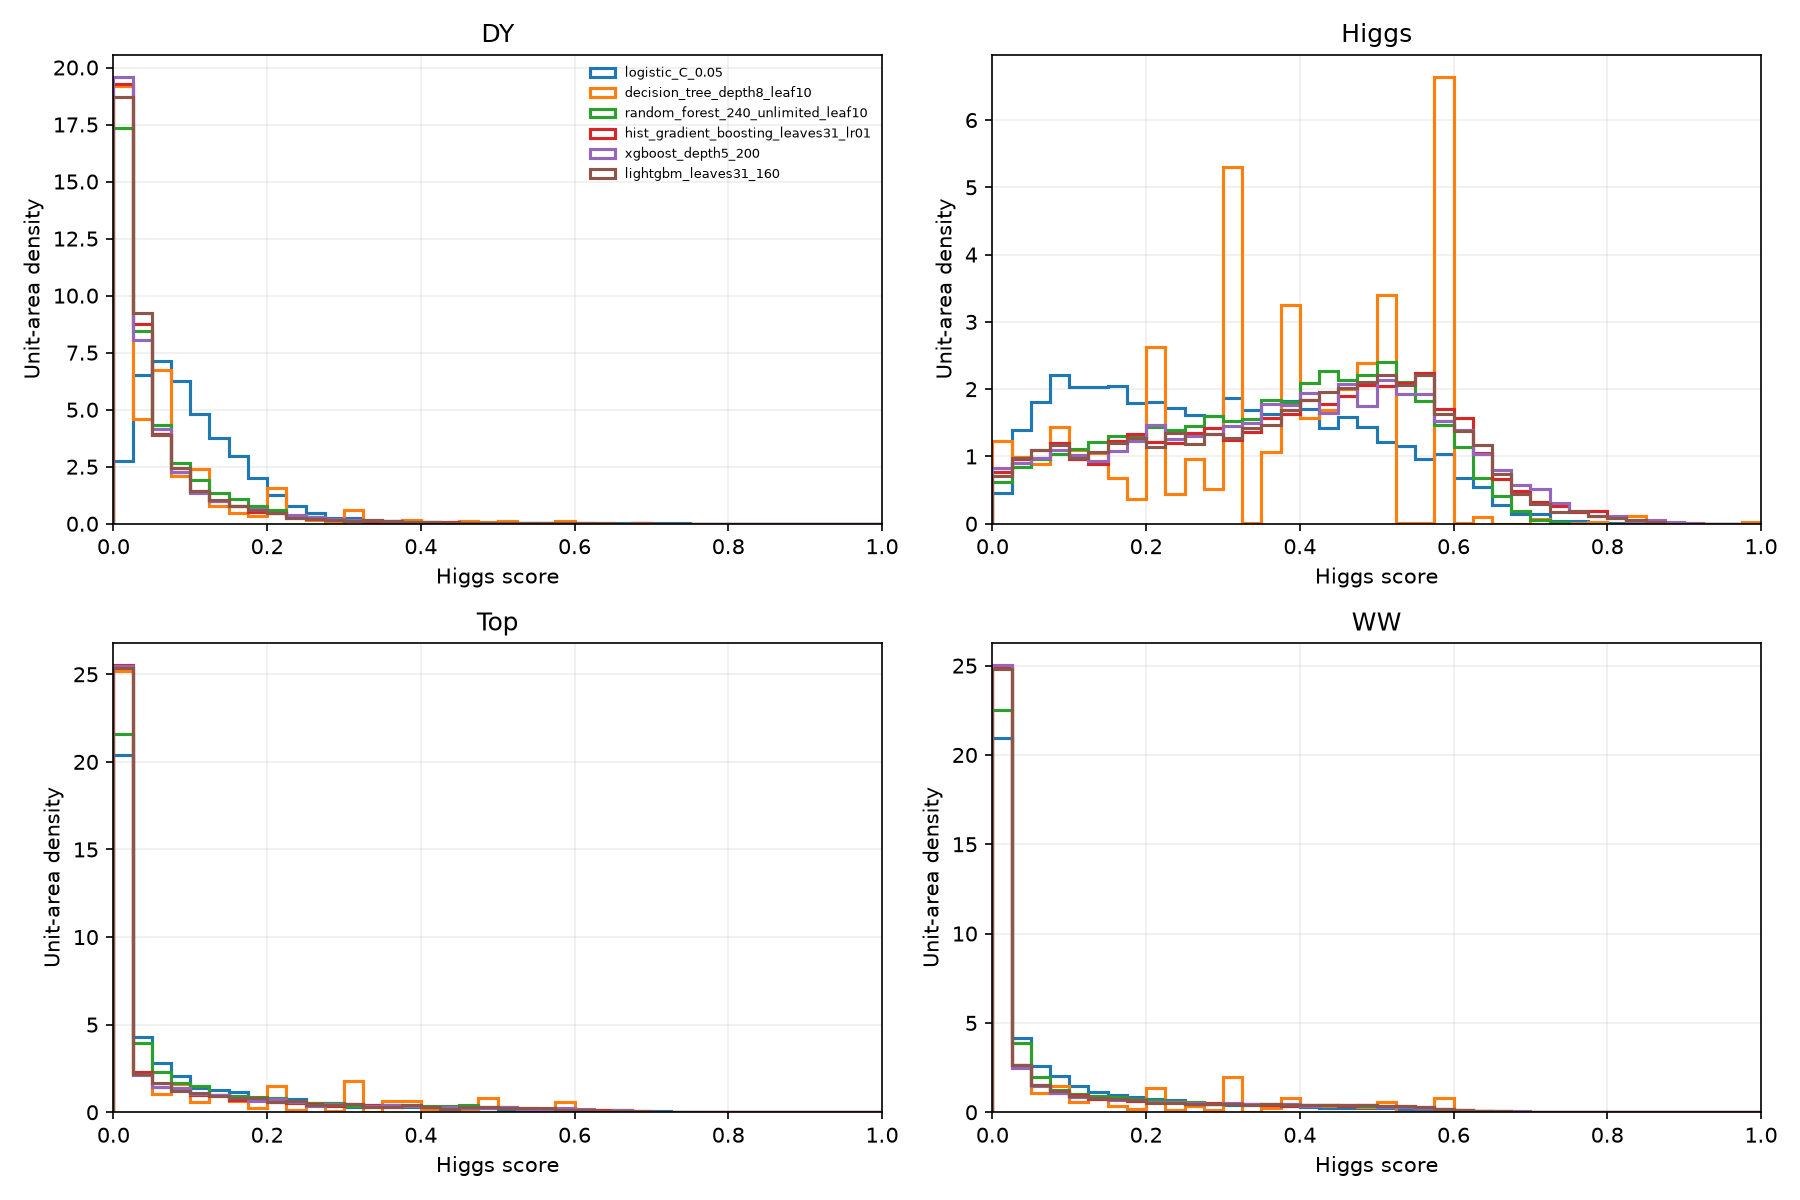

In [16]:
details = {
    "Fitting": (lab_fit, fit_score),
    "Validation": (lab_val, selected_val_score),
    "Test": (lab_test[valid], test_score[valid]),
}
ks_rows = []
for c in CLASSES:
    for s1, s2 in [
        ("Fitting", "Validation"),
        ("Fitting", "Test"),
        ("Validation", "Test"),
    ]:
        l1, a = details[s1]
        l2, b = details[s2]
        u = a[l1 == c]
        v = b[l2 == c]
        k = ks_2samp(u, v, method="auto")
        ks_rows.append(
            {
                "label": c,
                "comparison": s1 + " vs " + s2,
                "n1": len(u),
                "n2": len(v),
                "D": float(k.statistic),
                "p": float(k.pvalue),
            }
        )
display_table(ks_rows)
process_rows = []
for c in CLASSES:
    mask = valid & (lab_test == c)
    sc = test_score[mask]
    row = {
        "label": c,
        "test_count": int(mask.sum()),
        "fraction_above_threshold": float(np.mean(sc >= FROZEN_THRESHOLD)),
    }
    if c != "Higgs":
        pair = valid & np.isin(lab_test, ["Higgs", c])
        row["Higgs_vs_process_AUC"] = float(
            roc_auc_score(y_test[pair], test_score[pair])
        )
        row["Higgs_vs_process_AP"] = float(
            average_precision_score(y_test[pair], test_score[pair])
        )
    process_rows.append(row)
display_table(process_rows)
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axs.flat, CLASSES):
    for name, (labs, ss) in details.items():
        v = ss[labs == c]
        ax.hist(
            v,
            bins=np.linspace(0, 1, 41),
            density=True,
            histtype="step",
            lw=1.6,
            label=f"{name} ({len(v):,})",
        )
    ax.axvline(FROZEN_THRESHOLD, color="k", ls="--")
    ax.set(xlim=(0, 1), xlabel="Higgs score", ylabel="Unit density", title=c)
    ax.grid(alpha=0.2)
axs[0, 0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUT_DIR / "scores_by_process.png", dpi=150)
display(Image(filename=str(OUT_DIR / "scores_by_process.png")))
plt.close(fig)
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axs.flat, ["mll", "mth", "mtw2", "PuppiMET_pt", "njet", "ptll"]):
    j = FEATURES.index(name)
    allvals = np.r_[X_fit[:, j], X_test[valid, j]]
    hi = np.nanquantile(allvals, 0.995)
    bins = (
        np.arange(np.nanmin(allvals) - 0.5, np.nanmax(allvals) + 1.5, 1)
        if name == "njet"
        else np.linspace(np.nanmin(allvals), hi, 41)
    )
    for c in CLASSES:
        for split, labs, mat, style in [
            ("Fitting", lab_fit, X_fit, "-"),
            ("Test", lab_test[valid], X_test[valid], "--"),
        ]:
            v = mat[labs == c, j]
            ax.hist(
                v,
                bins=bins,
                density=True,
                histtype="step",
                lw=1.35,
                ls=style,
                label=f"{c} {split}",
            )
    ax.set(xlabel=name, ylabel="Unit density", title=name)
    ax.grid(alpha=0.2)
axs[0, 0].legend(frameon=False, fontsize=6, ncol=2)
fig.suptitle("Class-wise input-feature shift; descriptive only")
fig.tight_layout()
fig.savefig(OUT_DIR / "classwise_feature_shift.png", dpi=150)
display(Image(filename=str(OUT_DIR / "classwise_feature_shift.png")))
plt.close(fig)
if overlap.sum():
    keep = valid & ~overlap
    sensitivity = (
        metrics(y_test[keep], test_score[keep], FROZEN_THRESHOLD)
        if len(np.unique(y_test[keep])) == 2
        else "undefined: one class remains"
    )
else:
    keep = valid
    sensitivity = "no matched rows; no secondary exclusion needed"
print(f"Primary test rows scored: {int(valid.sum()):,}")
print(f"Exact feature-vector matches with development rows: {int(overlap.sum()):,}")
if isinstance(sensitivity, dict):
    print("Matched-row sensitivity metrics:")
    display_table([sensitivity])
else:
    print(f"Matched-row sensitivity: {sensitivity}")
print("Feature-vector matches do not establish event identity.")
# Validation score distributions by each filename-derived process for shortlisted models.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cls in zip(axes.flat, CLASSES):
    mask = lab_val == cls
    for cid in short_ids:
        ax.hist(
            scores[cid]["validation"][mask],
            bins=np.linspace(0, 1, 41),
            density=True,
            histtype="step",
            lw=1.5,
            label=cid,
        )
    ax.set(xlim=(0, 1), xlabel="Higgs score", ylabel="Unit-area density", title=cls)
    ax.grid(alpha=0.2)
axes[0, 0].legend(frameon=False, fontsize=6)
fig.tight_layout()
fig.savefig(OUT_DIR / "candidate_scores_by_process.png", dpi=150)
display(Image(filename=str(OUT_DIR / "candidate_scores_by_process.png")))
plt.close(fig)


## Conclusion

This experiment compares a predeclared set of available model configurations and feature subsets on one deterministic fitting/validation split. All labels come from filenames; CMS process identity, event-level independence and physics normalization remain unverified. Option B test diagnostics are exploratory because Option A already used the same files. A fresh independent sample is needed for an unbiased final comparison.


In [17]:
print("Output directory:", OUT_DIR)
print(
    "Eight input inventories:",
    [(r["filename"], r["entries"], r["sha256"]) for r in inventory],
)
print("Search configurations:", len(attempts), "successful:", len(rows), "feature sets:", len(sets))
print(
    "Option B selected model:",
    winner["id"],
    "feature set:",
    selected_name,
    "threshold:",
    FROZEN_THRESHOLD,
)
runtime_rows = [
    {"stage": "training ROOT reads", "seconds": training_read_seconds},
    {"stage": "duplicate grouping and split", "seconds": group_split_seconds},
    {"stage": "candidate fits and predictions", "seconds": search_seconds},
    {"stage": "leading paired bootstrap", "seconds": leading_bootstrap_seconds},
    {"stage": "candidate fitting only", "seconds": candidate_fit_seconds},
    {"stage": "candidate paired bootstrap", "seconds": leading_bootstrap_seconds},
    {"stage": "full-feature permutation importance", "seconds": importance_seconds},
    {"stage": "feature-subset fits and predictions", "seconds": subset_fit_seconds},
    {"stage": "feature-subset paired bootstrap", "seconds": subset_bootstrap_seconds},
    {"stage": "test ROOT reads", "seconds": test_read_seconds},
    {"stage": "test inference", "seconds": test_inference_seconds},
    {"stage": "validation bootstrap", "seconds": bootstrap_seconds["validation"]},
    {"stage": "test bootstrap", "seconds": bootstrap_seconds["test"]},
    {"stage": "active notebook elapsed", "seconds": time.perf_counter() - NOTEBOOK_STARTED},
]
display_table(runtime_rows)
print(
    {
        "available_cpus": CPU_AVAILABLE,
        "hist_gradient_boosting_threads": HGB_THREADS,
        "random_forest_workers": RF_WORKERS,
        "cpu_override": CPU_OVERRIDE,
        "optional_families": OPTIONAL_STATUS,
        "nvidia_device": NVIDIA_DEVICE,
    }
)


Output directory: /Users/falcon/Documents/docs/hsf-india-bvcoe-2026/outputs/hsf_classification_extended/om_rishabh_hsf_classification_extended_20261016_v3
Eight input inventories: [('DY-train.root', 39103, '65d8e6ef0da05be440e6d38288ef479a9dc9055b9340fabf679a7b54f5367948'), ('Higgs-train.root', 21584, 'efcda212fba7ce344787840f7282a0fb37495861bbc71f1c74ca219c78041195'), ('Top-train.root', 20453, '30beb02050e2c007792bd7313e69fcaba42c564da08db6e3f8b06687f17f4841'), ('WW-train.root', 112816, '3388cb9207ac8fdc3dd3a964522a8047f00b0e5ee58eedfa7c5560d184e494c4'), ('DY-test.root', 29979, '6cc2ef3cf337e3d6a021b1026874b0d4baae1735ca8b8e46aa8866ced9366803'), ('Higgs-test.root', 112075, '68f470682df3a15f59792d0a995ccfc3be34ebe9a5d2dfb6987f064252ca1c13'), ('Top-test.root', 531601, 'ac26218027a3190e8c785a3497f9f9cabe5ed4f2ab47ea20d5ea6769d9b1b3bd'), ('WW-test.root', 185741, 'd1c0a375017360823c756a5994dac2248e2c59ef8a41d150ad70ae959685efe0')]
Search configurations: 18 successful: 18 feature sets: 9
Op

| stage | seconds |
| --- | --- |
| training ROOT reads | 0.2651 |
| duplicate grouping and split | 20.44 |
| candidate fits and predictions | 66.22 |
| leading paired bootstrap | 6.529 |
| candidate fitting only | 66.21 |
| candidate paired bootstrap | 6.529 |
| full-feature permutation importance | 5.955 |
| feature-subset fits and predictions | 10.95 |
| feature-subset paired bootstrap | 16.13 |
| test ROOT reads | 0.7558 |
| test inference | 2.566 |
| validation bootstrap | 1.911 |
| test bootstrap | 49.27 |
| active notebook elapsed | 205.7 |

{'available_cpus': 10, 'hist_gradient_boosting_threads': 4, 'random_forest_workers': 8, 'cpu_override': None, 'optional_families': {'xgboost': {'available': True, 'version': '3.4.1', 'backend': 'CPU', 'device': 'cpu', 'gpu_fallback_reason': 'nvidia-smi not found; no NVIDIA runtime detected'}, 'lightgbm': {'available': True, 'version': '4.7.0', 'backend': 'CPU', 'device': 'cpu', 'gpu_fallback_reason': 'nvidia-smi not found; no NVIDIA runtime detected'}}, 'nvidia_device': None}
